# Follow-up analyses G1-G3 on the boundary-extended run (decided 11 Oct 2026)

Three analyses added to the boundary-extended run (notebook `02_ceemdan_itransformer_shap_r1_ext`, tag I-15) without
changing any of its results:
- **G1 (R1.15):** attribution for all 18 modelled cities, not only the 8 of rule D4 (10 new cities).
- **G2 (R1.1, R1.3):** the main design on 4 decompositions (seed bases 123, 42, 2024, 7) with 5 model seeds each,
  accuracy and attribution (Delhi, Mumbai, Bengaluru) for all 20 models, and a random-effects analysis that separates
  the decomposition realisation from training variability.
- **G3 (R1.16):** 5 model seeds for every city-conditioning arm (12 new trainings). Report only: the main model stays.

**Reads** the I-15 run's Drive folder `MyDrive/phase4_v2_results_r1_ext` (never written) and `MyDrive/city_day.csv`.
**Writes** only to `MyDrive/phase4_v2_results_r1_ext/guide_followups/`. The reused files are copied there and checked
against the SHA-256 recorded from the authors' copy of the run (P1).

**Steps**
1. Upload this notebook to Colab. *Runtime → Change runtime type → T4 GPU*, High-RAM on (8 cores for the
   decompositions). Turn on background execution. Then *Runtime → Run all* and allow Drive access.
2. Before anything new runs, the pre-flight checks must pass (about 30 min):
   - P1 the reused files have the recorded SHA-256;
   - P2a this session's CEEMDAN recomputes saved decomposition days exactly;
   - P2 the datasets are rebuilt exactly;
   - P3 every reused model reproduces its saved test predictions;
   - P4 KernelSHAP reproduces saved values;
   - P5 one training repeated on this session agrees with the 7 Oct one within the seed s.d.
3. Then, in this order: G3 (about 1 h), G1 (about 2.4 h), G2 decompositions (5 to 6 h), G2 trainings (about 1.2 h),
   G2 SHAP (about 13 h). About 23 to 24 h in all, over two sessions.
4. After a disconnect, *Run all* again in a new session. Finished decompositions (per city), trainings and SHAP runs
   (per city and model) are reloaded and checked, not repeated.
5. If a check stops the notebook, do not delete or edit files.
6. Done when the last cell prints `G1-G3 COMPLETE`. The results zip holds the `reports/` and `plots/` folders, which are
   in `results/04_followups/` of this repository.

Code cells without a "G" heading are copied unchanged from notebook 02 _r1_ext.

## Setup (copied from notebook 02 _r1_ext)

In [43]:
# Colab GPU runtime check reminder:
#   Runtime -> Change runtime type -> Hardware accelerator -> GPU (T4 is fine)
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-2dfa80af-aeba-6058-917c-0b52eae903b0)


In [2]:
# Minimal installs — Colab already ships GPU-linked torch/numpy/pandas/sklearn/matplotlib/seaborn.
# Only these two are unlikely to be preinstalled:
#   EMD-signal  -> imported as `from PyEMD import CEEMDAN`  (verified in utils/ceemdan_utils.py
#                  and utils/augmented_features.py — both do `from PyEMD import CEEMDAN`)
#   shap        -> imported as `import shap`                (verified in utils/shap_utils.py)
!pip install -q "EMD-signal==1.9.0" "shap==0.51.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 69.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.2/82.2 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 6.7 MB/s eta 0:00:00


In [3]:
import sys
import time
import json
import pickle
import random
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(message)s')
logger = logging.getLogger('phase4_v2_notebook')

print(f"torch version   : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")

torch version   : 2.11.0+cu130
CUDA available  : True


In [4]:
# ── GPU detection (KNOWN FACT #1) ───────────────────────────────────────────
# CEEMDANFeatureTrainer / iTransformerTrainer / GroupLSTMTrainer all default to
# device='cpu' in the original .py files and none of the original train_*.py scripts
# ever override this. We detect the device once, here, and pass it explicitly into
# every trainer constructor throughout this notebook.
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
if device == 'cpu':
    print("WARNING: No GPU detected. Go to Runtime -> Change runtime type -> GPU.")

Using device: cuda


In [5]:
RANDOM_SEED = 123  # from config_phase4_v2.py

def set_all_seeds(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    # Deterministic cuDNN kernels — slightly slower, but removes one more source of
    # run-to-run variance on GPU. Not present in the original (CPU-only) code, added here
    # since this notebook is GPU-specific.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_all_seeds(RANDOM_SEED)
print(f"All RNGs seeded with {RANDOM_SEED}")

All RNGs seeded with 123


## Inputs (check P1) and the settings of the I-15 run

In [6]:
# ── Follow-up analyses G1-G3 (decided 11 Oct 2026): where this notebook reads and writes (check P1) ──
# Reads the AR-extended run of notebook 02 _r1_ext (decision I-15) in MyDrive/phase4_v2_results_r1_ext and never
# writes there. Everything new goes to its subfolder guide_followups. The files reused from the I-15 run are copied
# into that subfolder once, and every copy must have the SHA-256 recorded from the authors' copy of the run
# (recorded in this cell, text files after CRLF -> LF). So the reused models, datasets, decompositions and SHAP
# values are exactly those the manuscript reports. Saved trainings are copied to models/reused_runs, not to
# models/runs, so this notebook's resume helper never reloads them by itself (they are loaded and checked by
# g_load_run, after the pre-flight cell).
from google.colab import drive
drive.mount('/content/drive')
import hashlib
import os
import platform
import shutil

G_SOURCE_DIR = Path('/content/drive/MyDrive/phase4_v2_results_r1_ext')   # the I-15 run, read only
RESULTS_DIR = G_SOURCE_DIR / 'guide_followups'
MODELS_DIR, PLOTS_DIR, REPORTS_DIR = RESULTS_DIR / 'models', RESULTS_DIR / 'plots', RESULTS_DIR / 'reports'
G_INPUTS_DIR = REPORTS_DIR / 'inputs_r1_ext'   # copies of the I-15 records this notebook compares against
G_REUSED_RUNS_DIR = MODELS_DIR / 'reused_runs'
G_INPUTS = json.loads(r'''{
 "models/c5_decompositions/c5_Ahmedabad.npz": [
  "models/c5_decompositions/c5_Ahmedabad.npz",
  "6ffabbbba15913d044e1e5b9f13c1927661deaf13da7ae96f6f2bc832602da3c"
 ],
 "models/c5_decompositions/c5_Amaravati.npz": [
  "models/c5_decompositions/c5_Amaravati.npz",
  "1a1aef39aba673b77140290fb755cc45478427d86077f176996f0f9b97a7e645"
 ],
 "models/c5_decompositions/c5_Amritsar.npz": [
  "models/c5_decompositions/c5_Amritsar.npz",
  "ba1f5a8384122281ebb1d36d74097fd4ed02902b8edb470362a98b5a17969f01"
 ],
 "models/c5_decompositions/c5_Bengaluru.npz": [
  "models/c5_decompositions/c5_Bengaluru.npz",
  "487630402b20a4eaf51b39db348703e6186392cee9aa8c93e0d6b64be5c700ea"
 ],
 "models/c5_decompositions/c5_Brajrajnagar.npz": [
  "models/c5_decompositions/c5_Brajrajnagar.npz",
  "02ff8e921636b3720ab92361b003667dfedece878c6f1e4cac9d0b825eb5b81d"
 ],
 "models/c5_decompositions/c5_Chennai.npz": [
  "models/c5_decompositions/c5_Chennai.npz",
  "3083adf00665d90e44e828e1a6a9bfb20d4ae4bf2835fd96c2a786a7ad07ed87"
 ],
 "models/c5_decompositions/c5_Delhi.npz": [
  "models/c5_decompositions/c5_Delhi.npz",
  "992ca9b7ff6d35292a103ee146dfc54032427e77c849ebd1643db41d72aad014"
 ],
 "models/c5_decompositions/c5_Gurugram.npz": [
  "models/c5_decompositions/c5_Gurugram.npz",
  "4663945ea4db644545c01b0ef1546d7af2f195ceec951b0b8813fc0217ca08c2"
 ],
 "models/c5_decompositions/c5_Hyderabad.npz": [
  "models/c5_decompositions/c5_Hyderabad.npz",
  "d894b77811d54cad05a5e39a62beb52b054f6688bae0e588650100f1a9554c2e"
 ],
 "models/c5_decompositions/c5_Jaipur.npz": [
  "models/c5_decompositions/c5_Jaipur.npz",
  "3dc57cce9c5030d134ad9465528e316631484d17289e6e58c8dc6e4b3b525f02"
 ],
 "models/c5_decompositions/c5_Jorapokhar.npz": [
  "models/c5_decompositions/c5_Jorapokhar.npz",
  "bb70a9662428cc3a176f64320b54a4a85c267d78568b0c5304f807f60bd95ae9"
 ],
 "models/c5_decompositions/c5_Kolkata.npz": [
  "models/c5_decompositions/c5_Kolkata.npz",
  "5564caf3b06861ad1e5eb2c73cedcffbf097a4cbeff58b71f197fb571b06a5ec"
 ],
 "models/c5_decompositions/c5_Lucknow.npz": [
  "models/c5_decompositions/c5_Lucknow.npz",
  "20e911925e50b1102cb6f027967f544cbb5d09b3dce5093c2b257f7e1e416e04"
 ],
 "models/c5_decompositions/c5_Mumbai.npz": [
  "models/c5_decompositions/c5_Mumbai.npz",
  "d18b262378860e8bf16a9f3314055198bfb9aa8cc6fe70b7e662bf8c02a71413"
 ],
 "models/c5_decompositions/c5_Patna.npz": [
  "models/c5_decompositions/c5_Patna.npz",
  "37facd6334a6ba0fc1700d5cac65ba9199d9a347b5e70089ec0a2345608d5b88"
 ],
 "models/c5_decompositions/c5_Talcher.npz": [
  "models/c5_decompositions/c5_Talcher.npz",
  "2eecd97334cc1b92a6b93e003d434877ba1afa030f5640e3fb2eea1907f7d8fd"
 ],
 "models/c5_decompositions/c5_Thiruvananthapuram.npz": [
  "models/c5_decompositions/c5_Thiruvananthapuram.npz",
  "e42d910e239448ad367e1331dfec36a97b2917c6708e6549d0ffe1015f0216f9"
 ],
 "models/c5_decompositions/c5_Visakhapatnam.npz": [
  "models/c5_decompositions/c5_Visakhapatnam.npz",
  "41bc2e554cec78872b46ff24ff2475a80e4b9b05d62199731944ff42fb7c3745"
 ],
 "models/c5_decompositions_seed42/c5_Ahmedabad.npz": [
  "models/c5_decompositions_seed42/c5_Ahmedabad.npz",
  "d54937f86c26bc40a5b08c8b4e5651785f18d8bf4bf1a3e4f0411b34ecd5338f"
 ],
 "models/c5_decompositions_seed42/c5_Amaravati.npz": [
  "models/c5_decompositions_seed42/c5_Amaravati.npz",
  "72b045f0b2531283bc5ac8d8c225d6bbc304e4a84598304a4e0dca3cf5ebea4e"
 ],
 "models/c5_decompositions_seed42/c5_Amritsar.npz": [
  "models/c5_decompositions_seed42/c5_Amritsar.npz",
  "4cdb44c88ca37192e1b23395b1ca5b2e75be77ffc43f04368f0b6c1ce949520d"
 ],
 "models/c5_decompositions_seed42/c5_Bengaluru.npz": [
  "models/c5_decompositions_seed42/c5_Bengaluru.npz",
  "2344bd37c2b983fb4f4f915c61f141410a5616d6732e308e63de7ba8ff025b43"
 ],
 "models/c5_decompositions_seed42/c5_Brajrajnagar.npz": [
  "models/c5_decompositions_seed42/c5_Brajrajnagar.npz",
  "7c1369ba35c45e89b83650324d7ab49c64f70916f95f215b51f5c64dfdb9a4f5"
 ],
 "models/c5_decompositions_seed42/c5_Chennai.npz": [
  "models/c5_decompositions_seed42/c5_Chennai.npz",
  "78d063a5d360171bd1827c6e9d01135a5276487977be00d2d53a102e237ee423"
 ],
 "models/c5_decompositions_seed42/c5_Delhi.npz": [
  "models/c5_decompositions_seed42/c5_Delhi.npz",
  "b25049f5fe734ba338d036aaa0224d22816d14c9bf750bf194c0af0559737200"
 ],
 "models/c5_decompositions_seed42/c5_Gurugram.npz": [
  "models/c5_decompositions_seed42/c5_Gurugram.npz",
  "00a436d7730d2735e3050f8de051450064a09e828aabacc3a7aee05635d76250"
 ],
 "models/c5_decompositions_seed42/c5_Hyderabad.npz": [
  "models/c5_decompositions_seed42/c5_Hyderabad.npz",
  "a090715504b37d11c21afc81f0fbc9fbdd59093c089d2da41330dc7c8606ef37"
 ],
 "models/c5_decompositions_seed42/c5_Jaipur.npz": [
  "models/c5_decompositions_seed42/c5_Jaipur.npz",
  "d2b2c0e9fb49962d77c0296a72a96991b8a7db57ac81ae86edc43f07a0ce9be2"
 ],
 "models/c5_decompositions_seed42/c5_Jorapokhar.npz": [
  "models/c5_decompositions_seed42/c5_Jorapokhar.npz",
  "8b6378892ca45cd273d99977f74928e7c17952d8b9d351f4b979574dcd04d6c1"
 ],
 "models/c5_decompositions_seed42/c5_Kolkata.npz": [
  "models/c5_decompositions_seed42/c5_Kolkata.npz",
  "1a346da8d0f699d8ca0a0aaa60da383140e4fac3457bf98cce447374f6b911fa"
 ],
 "models/c5_decompositions_seed42/c5_Lucknow.npz": [
  "models/c5_decompositions_seed42/c5_Lucknow.npz",
  "11ad1596fbf687743d4addc353556de0ff8e18a4dba31302c0ecbe97dac01ed9"
 ],
 "models/c5_decompositions_seed42/c5_Mumbai.npz": [
  "models/c5_decompositions_seed42/c5_Mumbai.npz",
  "71a7204ea57ae97432fb3d8e2acce3389917431fe49028ed9e35b562c0c61be8"
 ],
 "models/c5_decompositions_seed42/c5_Patna.npz": [
  "models/c5_decompositions_seed42/c5_Patna.npz",
  "d69ae97d80cf7216f1dccd9628571070f4de06b2602582b8bbdf8eefb9f9182d"
 ],
 "models/c5_decompositions_seed42/c5_Talcher.npz": [
  "models/c5_decompositions_seed42/c5_Talcher.npz",
  "2ac6e45c10e13be2faa39470a14c174825b5fe0d9e7baff3b219c1c9861f7333"
 ],
 "models/c5_decompositions_seed42/c5_Thiruvananthapuram.npz": [
  "models/c5_decompositions_seed42/c5_Thiruvananthapuram.npz",
  "256561289e260d702dc02dafe0126b0864c4836fa1da0839e4db20bf73ebeb71"
 ],
 "models/c5_decompositions_seed42/c5_Visakhapatnam.npz": [
  "models/c5_decompositions_seed42/c5_Visakhapatnam.npz",
  "f5198fd088cac7de4d751104e9a486d8857370096186e7e2e85c419d3be32b86"
 ],
 "models/ceemdan_it_v2_dseed42_lb7.pt": [
  "models/ceemdan_it_v2_dseed42_lb7.pt",
  "d4cbe7e351a1e71585f1ae489458605b7a859f2df23c023d0c19312a8951d672"
 ],
 "models/ceemdan_it_v2_dseed42_lb7_dataset.npz": [
  "models/ceemdan_it_v2_dseed42_lb7_dataset.npz",
  "c443bec1987bc5d575b49cf793f6a0a951386322ab48a4d75fd912cd56a3e6a0"
 ],
 "models/ceemdan_it_v2_dseed42_lb7_scalers.pkl": [
  "models/ceemdan_it_v2_dseed42_lb7_scalers.pkl",
  "04f481b7ef4f485d7b199b352988d36b73627e55779c6417595dda587d9137aa"
 ],
 "models/ceemdan_it_v2_lb7.pt": [
  "models/ceemdan_it_v2_lb7.pt",
  "2184fa3ef205a8e0fc172aaed5534219e59aa7edb1a9df63c6cbe3c8ba46555e"
 ],
 "models/ceemdan_it_v2_lb7_dataset.npz": [
  "models/ceemdan_it_v2_lb7_dataset.npz",
  "9cde7dee0f4e42bf9a36fcbbaa4ef514a4e9a34e21b31ff60c188487537b8301"
 ],
 "models/ceemdan_it_v2_lb7_scalers.pkl": [
  "models/ceemdan_it_v2_lb7_scalers.pkl",
  "885750ea8e47cfa1d5ac414b49e25a07f4ce993311738490dbd4cda5c431de6d"
 ],
 "models/runs/r116_lb7_bias_s2024.pt": [
  "models/reused_runs/r116_lb7_bias_s2024.pt",
  "47f59c2250e304ff8fa1cf43ae9a10dd5151cbce264c14240f5f1cd582d0254e"
 ],
 "models/runs/r116_lb7_bias_s2025.pt": [
  "models/reused_runs/r116_lb7_bias_s2025.pt",
  "58aad58d65c96fb36ff617bb39ec3fd87164b808df2f1688f704828d98d1cb1f"
 ],
 "models/runs/r116_lb7_bias_s42.pt": [
  "models/reused_runs/r116_lb7_bias_s42.pt",
  "98040d316f48d9c3a3f39856c231c69d48d8ddfb5dd577c95c51fe19405f80ec"
 ],
 "models/runs/r116_lb7_bias_s7.pt": [
  "models/reused_runs/r116_lb7_bias_s7.pt",
  "b4a5be91e611b720b45e9e527f0e293b9da1533d97a71c99284e818d32c4bb27"
 ],
 "models/runs/r116_lb7_none_s123.pt": [
  "models/reused_runs/r116_lb7_none_s123.pt",
  "d8ed6d5c3306b0edf4c900511aa1191044bacc9f9097e690e6094e72b7b470ec"
 ],
 "models/runs/r116_lb7_scale_bias_s123.pt": [
  "models/reused_runs/r116_lb7_scale_bias_s123.pt",
  "441c3bae5d5b3fcb72a74a6d10d53b8155005dc0a5a22b3cca782cb9f4790bda"
 ],
 "models/runs/r116_lb7_vector_bias_s123.pt": [
  "models/reused_runs/r116_lb7_vector_bias_s123.pt",
  "01a05e91edf878b322f37fdaee4ca29c80eeb0b6639c0595e417001f7001f934"
 ],
 "models/runs/v2_dseed42_lb7_bias_d1b_s123.pt": [
  "models/reused_runs/v2_dseed42_lb7_bias_d1b_s123.pt",
  "fcee06c7a8897d6725c9a277f07caa894a3e4f9d7b16a47987c0120297ef60b7"
 ],
 "models/runs/v2_lb7_bias_d1b_s123.pt": [
  "models/reused_runs/v2_lb7_bias_d1b_s123.pt",
  "21b38b45e993352da84738d4061a91b8c7543bfe32d2b76ad86ec5fe64a75054"
 ],
 "reports/r113_lookback_selection.json": [
  "reports/inputs_r1_ext/r113_lookback_selection.json",
  "81dd1f89d912d28457b25231339e6ba01f7d98379eb536b4e05015e8912a9bbb"
 ],
 "reports/r116_city_diagnostics_lb7.csv": [
  "reports/inputs_r1_ext/r116_city_diagnostics_lb7.csv",
  "542df190e7ad6153acd14c6f105339d10175a84080dc43374298e5994f1302dc"
 ],
 "reports/r116_conditioning_runs_lb7.csv": [
  "reports/inputs_r1_ext/r116_conditioning_runs_lb7.csv",
  "a010fcd98e355c30732886c84267fa37d60f9e377fa8aa6253738c52d80f4faf"
 ],
 "reports/r116_rule_lb7.json": [
  "reports/inputs_r1_ext/r116_rule_lb7.json",
  "b9d80df39c1d809d582d0c72113414d42fb3cfa0af4afb47c80bd7a9af20ad8a"
 ],
 "reports/r116_test_predictions_lb7.npz": [
  "reports/inputs_r1_ext/r116_test_predictions_lb7.npz",
  "0399ddd49bc28e3abdeb3ddfd015fc768ecee802510756b4088735bf8c5b0f87"
 ],
 "reports/r117_decomp_seed_accuracy_lb7.csv": [
  "reports/inputs_r1_ext/r117_decomp_seed_accuracy_lb7.csv",
  "e4808e84e8754b353500897a9e36e24d55ae71f48a9a28f8cdde8192b2cbaed6"
 ],
 "reports/shap/r117_decomp_seed_shap_lb7.csv": [
  "reports/inputs_r1_ext/shap/r117_decomp_seed_shap_lb7.csv",
  "7fb78542e96a2291c31c61c97342fdf6b1578ad06b13bc42115e47b21dd149bf"
 ],
 "reports/shap/shap8_attribution_matrix_lb7.csv": [
  "reports/inputs_r1_ext/shap/shap8_attribution_matrix_lb7.csv",
  "afd8b7a0656205e8aa3916a849b984c0b6a937f9da0c30022ce1b9e346dbf4b5"
 ],
 "reports/shap/shap8_summary_lb7.csv": [
  "reports/inputs_r1_ext/shap/shap8_summary_lb7.csv",
  "b51f229e3303315a6307550eb934abf60e53891c15f38cd6ca4d68e114c3ff02"
 ],
 "reports/shap/shap_cache_r1/v2_Bengaluru_lb7_n100_bg50_seed127.npz": [
  "reports/shap/shap_cache_r1/v2_Bengaluru_lb7_n100_bg50_seed127.npz",
  "549f3d8245fded2dfccc777ea73e28f2f03d3d6b47ac7be5196520357575e94b"
 ],
 "reports/shap/shap_cache_r1/v2_Delhi_lb7_n100_bg50_seed133.npz": [
  "reports/shap/shap_cache_r1/v2_Delhi_lb7_n100_bg50_seed133.npz",
  "2c335dcd6096e5c5fccf678637fa6832fe3ffa57b6388c79caabd20c86b94648"
 ],
 "reports/shap/shap_cache_r1/v2_Gurugram_lb7_n100_bg50_seed135.npz": [
  "reports/shap/shap_cache_r1/v2_Gurugram_lb7_n100_bg50_seed135.npz",
  "b3d38c1c1d27c63e2a00c7f6ca564487f8ddd3ca26b799f173d377a0f5cb3092"
 ],
 "reports/shap/shap_cache_r1/v2_Jaipur_lb7_n100_bg50_seed138.npz": [
  "reports/shap/shap_cache_r1/v2_Jaipur_lb7_n100_bg50_seed138.npz",
  "228507df7cf3d4ffdc9fe2e3be9b5aaccb6adbf8e64f71959a57e5b2512d0c99"
 ],
 "reports/shap/shap_cache_r1/v2_Kolkata_lb7_n100_bg50_seed141.npz": [
  "reports/shap/shap_cache_r1/v2_Kolkata_lb7_n100_bg50_seed141.npz",
  "b14fa1525eff3f37202099edd455274255deba97614a2145498da9932c8d0413"
 ],
 "reports/shap/shap_cache_r1/v2_Lucknow_lb7_n100_bg50_seed142.npz": [
  "reports/shap/shap_cache_r1/v2_Lucknow_lb7_n100_bg50_seed142.npz",
  "d07392748bb72e4a127add01ec474bf6b82493541e1b2440b5c4241073cc01ac"
 ],
 "reports/shap/shap_cache_r1/v2_Mumbai_lb7_n100_bg50_seed143.npz": [
  "reports/shap/shap_cache_r1/v2_Mumbai_lb7_n100_bg50_seed143.npz",
  "a9d4d46d805549913afed1a422a44864d5d15de84b97ada38ff1778d4c36cddb"
 ],
 "reports/shap/shap_cache_r1/v2_Patna_lb7_n100_bg50_seed144.npz": [
  "reports/shap/shap_cache_r1/v2_Patna_lb7_n100_bg50_seed144.npz",
  "cc5dd721495f32cb1039b283d02511b68562f723065f8485c59640322f771a5a"
 ],
 "reports/shap/shap_cache_r1/v2_dseed42_Bengaluru_lb7_n100_bg50_seed127.npz": [
  "reports/shap/shap_cache_r1/v2_dseed42_Bengaluru_lb7_n100_bg50_seed127.npz",
  "940020c43c866fe87e69c850394bd95cd1f6be70d9957fca06da6dee785ed51e"
 ],
 "reports/shap/shap_cache_r1/v2_dseed42_Delhi_lb7_n100_bg50_seed133.npz": [
  "reports/shap/shap_cache_r1/v2_dseed42_Delhi_lb7_n100_bg50_seed133.npz",
  "70495f7dd4938ac03c2def2dcac0c760edc58e8e276ddb887e614effbd287fbb"
 ],
 "reports/shap/shap_cache_r1/v2_dseed42_Mumbai_lb7_n100_bg50_seed143.npz": [
  "reports/shap/shap_cache_r1/v2_dseed42_Mumbai_lb7_n100_bg50_seed143.npz",
  "7bb81aeab34af93593edaf56993f1e1b978c81795aa56dd851b8f27c9582016c"
 ],
 "reports/shap/shap_periods_v2_dseed42_lb7.csv": [
  "reports/inputs_r1_ext/shap/shap_periods_v2_dseed42_lb7.csv",
  "e7731f8ac6eb76e29a4d61d10c810d7d4205bffbd4fb63257445539814677548"
 ],
 "reports/shap/shap_periods_v2_lb7.csv": [
  "reports/inputs_r1_ext/shap/shap_periods_v2_lb7.csv",
  "b14939306c9c98ce2f044960aa7c4bb4b20c5ef6cedd6006812b04f1b87814d7"
 ]
}''')   # path in the I-15 folder -> [path here, SHA-256]; set by the builder
G_TEXT_SUFFIXES = ('.csv', '.json')


def g_sha256(path):
    '''SHA-256 of a file, text files (.csv, .json) after CRLF -> LF (the rule used when the digests were recorded).'''
    path = Path(path)
    with open(path, 'rb') as f:
        b = f.read()
    if path.suffix in G_TEXT_SUFFIXES:
        b = b.replace(b'\r\n', b'\n')
    return hashlib.sha256(b).hexdigest()


if not G_SOURCE_DIR.is_dir():
    raise FileNotFoundError(f'P1: {G_SOURCE_DIR} not found: the I-15 run (notebook 02 _r1_ext) must be on Drive')
for d in (MODELS_DIR, PLOTS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
g_new_copies = 0
for g_src_rel, (g_dst_rel, g_want) in sorted(G_INPUTS.items()):
    g_src, g_dst = G_SOURCE_DIR / g_src_rel, RESULTS_DIR / g_dst_rel
    if not g_dst.exists():
        if not g_src.is_file():
            raise FileNotFoundError(f'P1: {g_src} not found in the I-15 run')
        g_dst.parent.mkdir(parents=True, exist_ok=True)
        g_tmp = g_dst.with_name(g_dst.name + '.partial')
        shutil.copyfile(g_src, g_tmp)
        os.replace(g_tmp, g_dst)
        g_new_copies += 1
    g_got = g_sha256(g_dst)
    if g_got != g_want:
        raise ValueError(f'P1: {g_dst_rel} has SHA-256 {g_got[:16]}..., not the {g_want[:16]}... of the I-15 run as the '
                         f'authors hold it. Do not delete anything: report this message.')
print(f'P1 passed: {len(G_INPUTS)} files of the I-15 run in {RESULTS_DIR} with the recorded SHA-256 '
      f'({g_new_copies} copied in this session)')


def g_versions():
    '''The software and hardware of this session (recorded, not checked: P2 to P5 check the results).'''
    import PyEMD
    import scipy
    import shap
    import sklearn
    return {'python': platform.python_version(), 'torch': torch.__version__, 'cuda': torch.version.cuda,
            'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            'cpu_count': os.cpu_count(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
            'scikit-learn': sklearn.__version__, 'EMD-signal': PyEMD.__version__, 'shap': shap.__version__}


G_SESSION_JSON = REPORTS_DIR / 'g_sessions.json'
G_SESSIONS = json.loads(G_SESSION_JSON.read_text()) if G_SESSION_JSON.exists() else []
G_SESSIONS.append({'started': time.strftime('%Y-%m-%d %H:%M:%S %Z'), **g_versions()})
G_SESSION_JSON.write_text(json.dumps(G_SESSIONS, indent=1))
print(f'session {len(G_SESSIONS)}:', json.dumps(G_SESSIONS[-1]))


Mounted at /content/drive
P1 passed: 73 files of the I-15 run in /content/drive/MyDrive/phase4_v2_results_r1_ext/guide_followups with the recorded SHA-256 (0 copied in this session)
session 3: {"started": "2026-10-12 17:16:03 UTC", "python": "3.13.15", "torch": "2.11.0+cu130", "cuda": "13.0", "gpu": "Tesla T4", "cpu_count": 8, "numpy": "2.1.3", "pandas": "2.2.3", "scipy": "1.16.3", "scikit-learn": "1.6.1", "EMD-signal": "1.9.0", "shap": "0.51.0"}


In [7]:
CANDIDATE_PATHS = [
    Path('/content/city_day.csv'),
    Path('/content/drive/MyDrive/city_day.csv'),
    Path('/content/drive/MyDrive/phase4_v2_data/city_day.csv'),
]

DATA_FILE = next((p for p in CANDIDATE_PATHS if p.exists()), None)

if DATA_FILE is None:
    print("city_day.csv not found in common locations.")
    print("Please upload Implementation/Datasets/kaggle/2/city_day.csv now.")
    from google.colab import files
    uploaded = files.upload()
    # Take whichever file was uploaded (should be city_day.csv)
    uploaded_name = next(iter(uploaded.keys()))
    DATA_FILE = Path('/content') / uploaded_name

print(f"Using data file: {DATA_FILE}")
assert DATA_FILE.exists(), f"Data file not found at {DATA_FILE}"

city_day.csv not found in common locations.
Please upload Implementation/Datasets/kaggle/2/city_day.csv now.


Saving city_day.csv to city_day.csv
Using data file: /content/city_day.csv


In [8]:
# ── G1-G3: the input data, and the settings of the I-15 run that this notebook repeats (from its records) ──
G_CITY_DAY_SHA256 = '0d84b21c3e4878bbad8df362f2ab05f61ad959538dddf5918e714077ed3c1847'   # as archived (Methods)
if g_sha256(DATA_FILE) != G_CITY_DAY_SHA256:
    raise ValueError(f'P1: {DATA_FILE} is not the archived city_day.csv (SHA-256 {G_CITY_DAY_SHA256[:16]}...)')
with open(G_INPUTS_DIR / 'r113_lookback_selection.json') as f:
    MAIN_LOOKBACK = int(json.load(f)['main_lookback'])          # R1.13: chosen on validation data (Section 6)
with open(G_INPUTS_DIR / f'r116_rule_lb{MAIN_LOOKBACK}.json') as f:
    MAIN_CONDITIONING = json.load(f)['main_conditioning']       # R1.16: the rule fixed in advance kept the scalar bias
if (MAIN_LOOKBACK, MAIN_CONDITIONING) != (7, 'bias'):
    raise ValueError(f'G: the I-15 records give lookback {MAIN_LOOKBACK} and {MAIN_CONDITIONING!r}, not 7 and the bias')
# As in notebook 02 _r1_ext: Section 9 (SHAP), Section 13 (model seeds)
SHAP_LOOKBACK = MAIN_LOOKBACK
SHAP_CITIES = ['Delhi', 'Mumbai', 'Bengaluru']
SHAP_N_BACKGROUND = 50
SHAP_MAX_TEST = 100
SEEDS = [42, 123, 2024, 7, 2025]
print(f'city_day.csv as archived; main lookback {MAIN_LOOKBACK}, city term {MAIN_CONDITIONING!r}, model seeds {SEEDS}')


city_day.csv as archived; main lookback 7, city term 'bias', model seeds [42, 123, 2024, 7, 2025]


## Pipeline code of notebook 02 _r1_ext (copied unchanged)

In [9]:
# From phase1_baselines/config_phase1.py
FEATURE_COLUMNS = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene"
]
TARGET_COLUMN = "AQI"

# From config_phase4_v2.py
N_POLLUTANTS   = 12
N_IMFS         = 5    # Revision 1, R1.2 a1: IMF1-IMF4 + one slow channel (C5_N_CHANNELS in the C5 helper)
N_FEATURES_V2  = N_POLLUTANTS + N_IMFS   # 17
# Split and modelled cities: Revision 1, R1.9/R1.10, common target dates for every city and one city
# rule (at least one training window), in the R1.9 helper cell. Replaces TRAIN_RATIO = 0.7,
# VAL_RATIO = 0.1 and MIN_CITY_SAMPLES = 300.
LOOKBACK_PERIODS_V2 = [7, 14, 21, 30]
# CEEMDAN settings: the C5 helper cell (Revision 1, R1.1). CEEMDAN_V2_PARAMS removed: its noise_std_factor
# was never applied by PyEMD (N4).
ITRANSFORMER_V2_PARAMS = {'d_model': 128, 'nhead': 8, 'ff_dim': 512, 'n_layers': 4, 'dropout': 0.1}
EPOCHS_V2        = 150
BATCH_SIZE_V2    = 32
PATIENCE_V2      = 15
LEARNING_RATE_V2 = 0.0005
WEIGHT_DECAY_V2  = 1e-06
WARMUP_EPOCHS_V2 = 10
H1_TARGET        = 0.92  # research-proposal hypothesis threshold, from train_ceemdan_itransformer_v2.py


def load_clean_data(data_file, target_col=TARGET_COLUMN):
    '''Transcribed from train_ceemdan_itransformer_v2.py::load_clean_data.
    Revision 1: pollutant filling moved to the window builders (N1/R1.11). R3.6 (T2): the target is a parameter,
    and the rows kept are the days with a target value (PM2.5 for the PM2.5 check, Section 15).'''
    logger.info(f"Loading data from {data_file}...")
    df = pd.read_csv(data_file)
    df = df.dropna(subset=[target_col])
    # Revision 1, N1/R1.11 (P3): pollutant gaps are no longer filled here. The submitted
    # ffill().bfill() back-filled from later dates and, being ungrouped, from other cities, and the
    # mean fill used the whole dataset. Each window builder now fills them on the daily calendar
    # (n1_pollutant_calendar, n1_fill_constant).

    logger.info(f"Cleaned data: {df.shape}, Cities: {df['City'].nunique()}")
    return df

In [10]:
# Revision 1, reviewer comment R3.3, decision D1 option (b): calendar-based windows.
#
# Each city's series is placed on a continuous daily calendar running from its first to its last
# observed day. A run of at most D1_MAX_FILL_DAYS consecutive missing days is filled by copying the
# last observed day (past values only). Longer runs stay missing. A forecast window is used only if
# every one of its input days is observed or filled AND its target day is observed. Targets are
# never filled, so every evaluated target is a real observation, and a window of length L always
# spans exactly L calendar days followed by the next calendar day as its target.
D1_MAX_FILL_DAYS = 3


def d1_calendar_city(df_c, value_cols, max_fill_days=D1_MAX_FILL_DAYS):
    '''
    Place one city's rows on a daily calendar and forward-fill short gaps.

    df_c        : rows of a single city, one row per observed day, with a 'Date' column.
    value_cols  : columns to carry onto the calendar.
    Returns (frame, observed, available):
      frame     : DataFrame with 'Date' plus value_cols, one row per calendar day. Days in a gap of
                  at most max_fill_days hold an exact copy of the last observed day. Days in longer
                  gaps hold NaN.
      observed  : bool ndarray, True where df_c has a row for that day.
      available : bool ndarray, True where the day is observed or filled.
    '''
    dates = pd.to_datetime(df_c['Date'])
    if dates.duplicated().any():
        raise ValueError('d1_calendar_city: duplicate dates within one city')
    vals = df_c[list(value_cols)].set_index(dates).sort_index()
    calendar = pd.date_range(vals.index[0], vals.index[-1], freq='D')
    frame = vals.reindex(calendar)
    observed = np.asarray(calendar.isin(vals.index), dtype=bool)
    missing = ~observed

    # Length of the missing run each day belongs to. run_id increases at every observed day, so all
    # days of one missing run share the run_id of the observed day that precedes them.
    run_id = np.cumsum(observed)
    run_len = pd.Series(missing.astype(np.int64)).groupby(run_id).transform('sum').to_numpy()
    fill = missing & (run_len <= max_fill_days)

    # Copy the last observed day. The calendar starts on an observed day, so one always exists.
    last_obs = np.maximum.accumulate(np.where(observed, np.arange(len(observed)), -1))
    if fill.any():
        frame.iloc[np.flatnonzero(fill)] = frame.iloc[last_obs[fill]].to_numpy()

    available = observed | fill
    frame = frame.rename_axis('Date').reset_index()
    return frame, observed, available


def d1_window_starts(observed, available, seq_len):
    '''
    Start indices of usable windows on the calendar.

    Window i uses input days i .. i+seq_len-1 and target day i+seq_len. It is usable when every
    input day is available (observed or filled) and the target day is observed.
    '''
    observed = np.asarray(observed, dtype=bool)
    available = np.asarray(available, dtype=bool)
    n = len(observed)
    if n <= seq_len:
        return np.array([], dtype=np.int64)
    csum = np.concatenate([[0], np.cumsum(available.astype(np.int64))])
    starts = np.arange(n - seq_len, dtype=np.int64)
    inputs_ok = (csum[starts + seq_len] - csum[starts]) == seq_len
    target_ok = observed[starts + seq_len]
    return starts[inputs_ok & target_ok]


def d1_train_row_mask(n_rows, train_starts, seq_len, available):
    '''
    Calendar rows used to fit scalers: available days up to and including the target day of the
    last training window. No validation or test day is included.
    '''
    mask = np.zeros(n_rows, dtype=bool)
    if len(train_starts) == 0:
        return mask
    mask[: int(train_starts[-1]) + seq_len + 1] = True
    return mask & np.asarray(available, dtype=bool)


In [11]:
# ── Revision 1, N1 / R1.11 (decision P3, gaps after the forward fill by option (c)): pollutant gaps filled from the city's own past ──
# Replaces groupby('City').ffill().bfill() + full-dataset mean fill in the loaders. Each window builder,
# on the daily calendar from d1_calendar_city:
#   1. n1_pollutant_calendar: a pollutant value is the last real reading within N1_MAX_FILL_DAYS
#      calendar days. A gap still open after the city's first reading of that pollutant gets the median
#      of the city's own readings in the previous N1_HISTORY_DAYS available days (the history of the
#      causal decomposition, R1.1 C5), or of all its earlier readings if there are none in that span.
#      No backward fill, nothing from another city, nothing from a later date.
#   2. n1_fill_constant: days before the city's first reading of a pollutant (or every day, if never
#      measured) get one constant per pollutant, the same for every city and date: the median of all
#      cities' real readings on training rows (the D1 scaler rows, d1_train_row_mask). Each builder
#      keeps the readings from n1_readings for this, since filled values cannot be told apart later.
N1_MAX_FILL_DAYS = 3     # same limit as D1_MAX_FILL_DAYS
N1_HISTORY_DAYS = 365    # same history cap as the causal decomposition (R1.1, C5)


def n1_readings(values, observed):
    '''Real pollutant readings on the daily calendar: values on observed days, NaN elsewhere.

    values: (n_days, n_pollutants) from d1_calendar_city, whose rows on non-observed days are D1 copies.
    '''
    return np.where(np.asarray(observed, dtype=bool)[:, None], values, np.nan)


def n1_pollutant_calendar(values, observed, available, max_fill_days=N1_MAX_FILL_DAYS,
                          history_days=N1_HISTORY_DAYS):
    '''Pollutant array on the daily calendar, filled from the city's own past readings only.

    values: (n_days, n_pollutants) from d1_calendar_city. Only rows of observed days are real readings,
    so the rows D1 copied into short AQI gaps are discarded and rebuilt by the same rule. Unavailable
    days stay NaN. Available days before the city's first reading of a pollutant stay NaN, for
    n1_fill_constant.
    '''
    available = np.asarray(available, dtype=bool)
    real = n1_readings(values, observed)
    out = pd.DataFrame(real).ffill(limit=max_fill_days).to_numpy(dtype=np.float64, copy=True)
    out[~available] = np.nan

    # Longer gaps after the first reading: median of the readings in the history_days available days
    # before day t. Unavailable days are skipped, as gaps are joined in the decomposition history (G1).
    avail_days = np.flatnonzero(available)
    avail_rank = np.cumsum(available) - 1
    days = np.arange(len(out))
    for j in range(out.shape[1]):
        read = np.isfinite(real[:, j])
        if not read.any():
            continue
        first = int(np.argmax(read))
        for t in np.flatnonzero(available & np.isnan(out[:, j]) & (days > first)):
            start = avail_days[max(int(avail_rank[t]) - history_days, 0)]
            past = real[start:t, j]
            past = past[np.isfinite(past)]
            if past.size == 0:                       # no reading in that span: all earlier readings
                past = real[:t, j][read[:t]]
            out[t, j] = np.median(past)
    return out


def n1_fill_constant(city_raw, key, city_splits, seq_len):
    '''Fill the days before each city's first reading of a pollutant with one pooled constant per pollutant.

    city_raw[c][key]: (n_days, n_pollutants) from n1_pollutant_calendar, filled in place. city_raw[c]
    also holds 'n', 'available', 'starts' and 'n1_readings' (from n1_readings). city_splits[c][0] is the
    number of training windows. The constant is the median of all cities' real readings on training rows.
    Returns the constant per pollutant.
    '''
    readings = []
    for c in city_raw:
        d = city_raw[c]
        rows = d1_train_row_mask(d['n'], d['starts'][:city_splits[c][0]], seq_len, d['available'])
        readings.append(d['n1_readings'][rows])
    readings = np.vstack(readings)
    if not np.isfinite(readings).any(axis=0).all():
        raise ValueError("N1: a pollutant has no training reading in any city")
    constant = np.nanmedian(readings, axis=0)
    for c in city_raw:
        x = city_raw[c][key]
        gap = np.isnan(x) & np.asarray(city_raw[c]['available'], dtype=bool)[:, None]
        x[gap] = np.broadcast_to(constant, x.shape)[gap]
    return constant

In [12]:
# ── Revision 1, R1.9/R1.10 (decision P4 on common dates) with the R1.1 minimum history (C5): windows, split, cities ──
# Replaces the per-city 70/10/20 split and the per-builder city thresholds (300 + L rows, L + 10 rows, none).
# Every builder takes a city's windows from r19_city_windows:
#   1. D1 windows (d1_window_starts).
#   2. R1.1 minimum history: a window is kept only if its last input day has at least R11_MIN_HISTORY_DAYS
#      available days up to and including it, counted from the start of the record (gaps joined, G1).
#   3. Split by the target date, the same dates for every city: training targets before R19_VAL_START,
#      validation targets before R19_TEST_START, test targets up to R19_DATA_END.
# A city is modelled only if it has at least one training window. r19_check_cities then makes every builder
# call of a run model the same cities, in the same order, per target (R3.6: the PM2.5 check has its own cities).
R19_VAL_START = np.datetime64('2019-04-01')    # first validation target date
R19_TEST_START = np.datetime64('2019-07-01')   # first test target date
R19_DATA_END = np.datetime64('2020-07-01')     # last day of the data set, last test target date
R11_MIN_HISTORY_DAYS = 180                     # R1.1 decision C5


def r19_city_windows(dates, observed, available, seq_len, min_history=R11_MIN_HISTORY_DAYS):
    '''Usable windows of one city and its split by target date.

    dates, observed, available: the daily calendar from d1_calendar_city.
    Returns (starts, (n_train, n_train + n_val, n_windows)). starts are in date order, so the first n_train
    windows are training windows, the next n_val validation windows and the rest test windows.
    '''
    available = np.asarray(available, dtype=bool)
    starts = d1_window_starts(observed, available, seq_len)
    history = np.cumsum(available)                      # available days up to and including each day
    starts = starts[history[starts + seq_len - 1] >= min_history]
    target = pd.to_datetime(pd.Series(dates)).to_numpy(dtype='datetime64[D]')[starts + seq_len]
    if len(target) and (np.any(np.diff(target) <= np.timedelta64(0, 'D')) or target[-1] > R19_DATA_END):
        raise ValueError('R1.9: window targets must be increasing and end by R19_DATA_END')
    n_train = int(np.searchsorted(target, R19_VAL_START, side='left'))
    n_train_val = int(np.searchsorted(target, R19_TEST_START, side='left'))
    return starts, (n_train, n_train_val, len(starts))


_r19_cities_in_run = {}


def r19_check_cities(valid_cities, builder, target='AQI'):
    '''Every builder call of a run for the same target must model the same cities in the same order (decision
    R1.9/R1.10).

    The first call per target records the list. A later call with a different list raises. Re-running this cell
    resets it. Revision 1, R3.6 (T2): the PM2.5 check models the cities with a PM2.5 training window, so the lists
    are kept per target. Every builder except the main model's is AQI-only and uses the default.
    '''
    cities = tuple(valid_cities)
    if not cities:
        raise ValueError(f'R1.9: {builder} has no city with a training window ({target})')
    first = _r19_cities_in_run.setdefault(target, (cities, builder))
    if cities != first[0]:
        raise ValueError(f'R1.9: {builder} models {list(cities)} for {target}, but {first[1]} modelled {list(first[0])}')

In [13]:
# ── Revision 1, R1.9/R1.10 (decision P4) and R3.3 D3 S1: accuracy per lockdown period, and the filled-day flag ──
# Every headline accuracy is also reported for the two periods of the common test year, a window assigned by its
# target date (decided 3 Oct 2026, step 6d):
#   pre-lockdown       targets 1 Jul 2019 to 24 Mar 2020
#   lockdown/Unlock    targets 25 Mar 2020 (first day of the national lockdown) to 1 Jul 2020 (Unlock 1.0)
# Each result row keeps its full-year metrics and gains n, r2, rmse, mae and mape per period, suffixed _pre and _lock,
# computed with the notebook's own Evaluator. S1 (R3.3 D3): a test window is "filled" if at least one input day was
# filled by D1 (available but not observed). N1 pollutant gaps are not counted.
R110_LOCKDOWN_START = np.datetime64('2020-03-25')   # first lockdown/Unlock target date
R110_COLUMNS = [f'{k}_{p}' for p in ('pre', 'lock') for k in ('n', 'r2', 'rmse', 'mae', 'mape')]


def r110_test_dates(dates, starts, split, seq_len):
    '''Target dates of one city's test windows (from r19_city_windows), in window order.'''
    dates = pd.to_datetime(pd.Series(dates)).to_numpy(dtype='datetime64[D]')
    return dates[np.asarray(starts, dtype=np.int64)[split[1]:] + seq_len]


def r110_filled_windows(observed, starts, seq_len):
    '''Per window: True if at least one input day was filled by D1 (S1).'''
    n_filled = np.concatenate([[0], np.cumsum(~np.asarray(observed, dtype=bool))])
    starts = np.asarray(starts, dtype=np.int64)
    return (n_filled[starts + seq_len] - n_filled[starts]) > 0


def r110_metrics(y_true, y_pred):
    '''n, r2, rmse, mae and mape by the Evaluator's definitions. NaN when fewer than 2 windows.'''
    y_true = np.asarray(y_true, dtype=np.float64).ravel()
    y_pred = np.asarray(y_pred, dtype=np.float64).ravel()
    if len(y_true) < 2:
        return {'n': len(y_true), 'r2': np.nan, 'rmse': np.nan, 'mae': np.nan, 'mape': np.nan}
    return {'n': len(y_true), 'r2': float(Evaluator.r2(y_true, y_pred)), 'rmse': float(Evaluator.rmse(y_true, y_pred)),
            'mae': float(Evaluator.mae(y_true, y_pred)), 'mape': float(Evaluator.mape(y_true, y_pred))}


def r110_period_columns(y_true, y_pred, target_dates):
    '''The pre-lockdown and lockdown/Unlock metrics of a test set, as columns n_pre, r2_pre, ..., mape_lock.'''
    dates = np.asarray(target_dates, dtype='datetime64[D]')
    y_true = np.asarray(y_true, dtype=np.float64).ravel()
    y_pred = np.asarray(y_pred, dtype=np.float64).ravel()
    if not len(dates) == len(y_true) == len(y_pred):
        raise ValueError(f'R1.10: {len(dates)} target dates for {len(y_true)} targets and {len(y_pred)} predictions')
    if len(dates) and (dates.min() < R19_TEST_START or dates.max() > R19_DATA_END):
        raise ValueError('R1.10: the period breakdown is for test windows only')
    lock = dates >= R110_LOCKDOWN_START
    out = {}
    for period, m in (('pre', ~lock), ('lock', lock)):
        out.update({f'{k}_{period}': v for k, v in r110_metrics(y_true[m], y_pred[m]).items()})
    return out


In [14]:
# ── Revision 1, R3.3 D3 S2 (step 6e): window construction of the S2 sensitivity arms ──
# Decided 30 Sep (D3) and 3 Oct 2026 (S2 details). The arms vary only how windows are cut:
#   'd1b'    D1(b), the main pipeline: daily calendar, gaps of at most D1_MAX_FILL_DAYS days filled from the last
#            observed day
#   'd1a'    D1(a), exclude: daily calendar with nothing filled, so every input day and target is an observed day
#   'steps'  observation steps, the submitted procedure: L consecutive observed rows, whatever calendar gaps lie
#            between them, and the next observed row as target. Per-day values as in 'd1a' (N1 on the daily
#            calendar, then the observed rows are kept)
# 'd1a' and 'steps' share the causal decomposition of the observed days only (I-6), made by c5_decompose_all with
# max_fill_days=0.
S2_ARMS = ('d1b', 'd1a', 'steps')


def s2_calendar(df_c, value_cols, gap_arm):
    '''Daily calendar of one city for an S2 arm: (cal, observed, available, rows). rows marks the calendar days the
    arm cuts its windows over: every day, or the observed days for 'steps'.'''
    if gap_arm not in S2_ARMS:
        raise ValueError(f'S2: unknown arm {gap_arm!r}, expected one of {S2_ARMS}')
    cal, observed, available = d1_calendar_city(df_c, value_cols,
                                                max_fill_days=D1_MAX_FILL_DAYS if gap_arm == 'd1b' else 0)
    rows = observed.copy() if gap_arm == 'steps' else np.ones(len(cal), dtype=bool)
    return cal, observed, available, rows


def s2_decomposition(dec, rows):
    '''A saved decomposition indexed by the kept rows instead of calendar days (unchanged when every day is kept).'''
    rows = np.asarray(rows, dtype=bool)
    if rows.all():
        return dec
    if not rows[dec['days']].all():
        raise ValueError('S2: a decomposed day is not among the kept rows (the steps arm needs the observed-days '
                         'decomposition)')
    return dict(dec, days=(np.cumsum(rows) - 1)[dec['days']].astype(np.int64))


In [15]:
# ── Revision 1, R1.1 (decision C5) and R1.2 (decision a1): causal CEEMDAN with sifting-order channels ──
# Replaces the full-record, energy-ranked decomposition (extract_city_imf_features).
# For every available day t of a city with at least C5_MIN_HISTORY available days so far, CEEMDAN runs on the
# last min(C5_W_MAX, available days so far) available AQI values up to and including t, joined across longer
# gaps (D2 = G1). Nothing after t enters. A window whose last input day is t takes all its channel values from
# the decomposition at t (its last L values).
# Each decomposition uses a fresh CEEMDAN instance seeded with the city's seed, so a result does not depend on
# which other days were decomposed, in which order, or on how many processes ran.
# Channels (a1): IMF1 to IMF4 in sifting order, plus one slow channel = IMF5 onwards + the residue.
# Saved per city and day: the last C5_KEEP values of every component (a1 channels and CEEMDAN+LSTM groups are
# derived from them), the number of components, the history length and each channel's zero-crossing period
# over the history (I-5). The noise amplitude is passed as `epsilon`, the argument PyEMD reads. The submitted
# code passed `noise_std`, which PyEMD ignores, so the submitted runs used PyEMD's default of 0.005.
# Revision 1, I-14 (step 6i): optional end-effect correction. With extension 'mirror' or 'ar' the history is extended
# by ext_days values computed from the history alone, decomposed, and the components are cut back to the history.
# The default 'none' is C5 as run of record (its saved settings, and so every existing cache, are unchanged).
import hashlib
import os

C5_W_MAX = 365                      # history cap, available days
C5_MIN_HISTORY = R11_MIN_HISTORY_DAYS   # 180, from the R1.9 helper cell
C5_TRIALS = 100
C5_EPSILON = 0.2                    # noise amplitude, as stated in Methods
C5_MAX_IMF = 8                      # PyEMD max_imf: at most max_imf + 1 IMFs plus the residue
C5_SEED_BASE = 123                  # city seed = C5_SEED_BASE + index of the city among all cities in the data
C5_KEEP = 30                        # values kept per decomposition: the longest lookback
C5_N_CHANNELS = 5
C5_MAX_COMPONENTS = C5_MAX_IMF + 2
C5_CHANNEL_NAMES = ['IMF1', 'IMF2', 'IMF3', 'IMF4', 'IMF5+ (slow)']
C5_EXTENSIONS = ('none', 'mirror', 'ar')   # I-14
C5_EXT_DAYS = 30                    # I-14: extension length, the longest lookback
C5_AR_MAX_ORDER = 14                # I-14: largest AR order tried for the 'ar' extension


def c5_params(trials=C5_TRIALS, epsilon=C5_EPSILON, max_imf=C5_MAX_IMF, w_max=C5_W_MAX,
              min_history=C5_MIN_HISTORY, keep=C5_KEEP, extension='none', ext_days=C5_EXT_DAYS):
    '''Every setting that determines a saved decomposition. A saved file must match these exactly.
    I-14: the extension settings are recorded only when an extension is used, so 'none' keeps the C5 record.'''
    import PyEMD
    if extension not in C5_EXTENSIONS:
        raise ValueError(f'C5: unknown extension {extension!r}')
    p = {'trials': int(trials), 'epsilon': float(epsilon), 'max_imf': int(max_imf), 'w_max': int(w_max),
         'min_history': int(min_history), 'keep': int(keep), 'pyemd': str(PyEMD.__version__)}
    if extension != 'none':
        p.update({'extension': str(extension), 'ext_days': int(ext_days), 'ar_max_order': C5_AR_MAX_ORDER})
    return p


def c5_ar_forecast(x, n_ahead, max_order=C5_AR_MAX_ORDER):
    '''I-14: n_ahead values continuing x by an AR(p) model with intercept, fitted by least squares on x only.
    p in 1..max_order minimises AIC, every order fitted on the same targets x[max_order:]. Forecast recursively.'''
    x = np.asarray(x, dtype=np.float64)
    n = len(x) - max_order
    if n <= 2 * max_order + 2:
        raise ValueError(f'C5: history of {len(x)} values is too short for an AR({max_order}) extension')
    y = x[max_order:]
    best = None
    for p in range(1, max_order + 1):
        X = np.column_stack([np.ones(n)] + [x[max_order - k:len(x) - k] for k in range(1, p + 1)])
        coef, *_ = np.linalg.lstsq(X, y, rcond=None)
        rss = float(np.sum((y - X @ coef) ** 2))
        aic = n * np.log(max(rss, 1e-300) / n) + 2 * (p + 1)
        if best is None or aic < best[0]:
            best = (aic, p, coef)
    _, p, coef = best
    buf = list(x[-p:])
    out = np.empty(n_ahead)
    for i in range(n_ahead):
        out[i] = coef[0] + sum(coef[k] * buf[-k] for k in range(1, p + 1))
        buf.append(out[i])
    return out


def c5_extend(x, extension='none', ext_days=C5_EXT_DAYS):
    '''I-14: the history x followed by ext_days values computed from x alone ('none': x unchanged).
    'mirror': x[n-2], x[n-3], ..., x[n-1-ext_days] (even symmetry about the last day). 'ar': c5_ar_forecast.'''
    x = np.asarray(x, dtype=np.float64)
    if extension == 'none':
        return x
    if extension == 'mirror':
        if len(x) < ext_days + 2:
            raise ValueError(f'C5: history of {len(x)} values is too short for a {ext_days}-day mirror')
        return np.concatenate([x, x[-2:-ext_days - 2:-1]])
    if extension == 'ar':
        return np.concatenate([x, c5_ar_forecast(x, ext_days)])
    raise ValueError(f'C5: unknown extension {extension!r}')


def c5_decompose(history, seed, trials=C5_TRIALS, epsilon=C5_EPSILON, max_imf=C5_MAX_IMF, extension='none',
                 ext_days=C5_EXT_DAYS):
    '''CEEMDAN components of one history, in sifting order (last row = residue). No fallback: errors raise.
    I-14: with an extension, the extended history is decomposed and the components are cut back to the history.

    Fewer than C5_N_CHANNELS components is allowed here and recorded, so a long run is never lost. Such a day
    cannot give a1 channels: c5_channels raises when a window needs it (decision for the authors).
    '''
    from PyEMD import CEEMDAN
    x = np.asarray(history, dtype=np.float64)
    comps = CEEMDAN(trials=trials, epsilon=epsilon, max_imf=max_imf, seed=seed, parallel=False)(
        c5_extend(x, extension, ext_days))[:, :len(x)]
    if not np.allclose(comps.sum(axis=0), x, rtol=0, atol=1e-6 * max(1.0, float(np.abs(x).max()))):
        raise ValueError('C5: CEEMDAN components do not reconstruct the history')
    if len(comps) > C5_MAX_COMPONENTS:
        raise ValueError(f'C5: {len(comps)} components, more than the {C5_MAX_COMPONENTS} that max_imf allows')
    return comps


def c5_channels(comps):
    '''a1 channels (5, n) from components (K, n): IMF1..IMF4, and the sum of IMF5 onwards and the residue.'''
    comps = np.asarray(comps, dtype=np.float64)
    if len(comps) < C5_N_CHANNELS:
        raise ValueError(f'C5: {len(comps)} components, a1 needs at least {C5_N_CHANNELS}')
    return np.vstack([comps[:C5_N_CHANNELS - 1], comps[C5_N_CHANNELS - 1:].sum(axis=0, keepdims=True)])


def c5_period(x):
    '''Zero-crossing period in days (as period_zero_crossing in the submitted notebook). NaN below 2 crossings.'''
    x = np.asarray(x, dtype=np.float64) - np.mean(x)
    s = np.sign(x)
    s[s == 0] = 1
    n = int(np.sum(s[:-1] != s[1:]))
    return 2.0 * (len(x) - 1) / n if n >= 2 else np.nan


def c5_days(available, min_history=C5_MIN_HISTORY):
    '''Calendar days decomposed: available days with at least min_history available days up to and including them.'''
    available = np.asarray(available, dtype=bool)
    return np.flatnonzero(available & (np.cumsum(available) >= min_history))


def c5_history(aqi, available, t, w_max=C5_W_MAX):
    '''The last min(w_max, available days so far) available AQI values up to and including day t (gaps joined).'''
    idx = np.flatnonzero(np.asarray(available, dtype=bool)[:t + 1])[-w_max:]
    return np.asarray(aqi, dtype=np.float64)[idx]


def _c5_job(args):
    '''One decomposition. Top-level so that worker processes can run it.'''
    history, seed, trials, epsilon, max_imf, keep = args[:6]
    extension, ext_days = args[6:8] if len(args) > 6 else ('none', C5_EXT_DAYS)   # I-14
    comps = c5_decompose(history, seed, trials, epsilon, max_imf, extension, ext_days)
    tail = np.full((C5_MAX_COMPONENTS, keep), np.nan)
    tail[:len(comps)] = comps[:, -keep:]
    periods = (np.array([c5_period(ch) for ch in c5_channels(comps)]) if len(comps) >= C5_N_CHANNELS
               else np.full(C5_N_CHANNELS, np.nan))
    return tail, len(comps), periods


def c5_decompose_city(aqi, available, seed, n_jobs=1, trials=C5_TRIALS, epsilon=C5_EPSILON,
                      max_imf=C5_MAX_IMF, w_max=C5_W_MAX, min_history=C5_MIN_HISTORY, keep=C5_KEEP,
                      extension='none', ext_days=C5_EXT_DAYS):
    '''Causal decompositions of one city on its D1 calendar (aqi, available from d1_calendar_city).

    Returns {'days', 'tail' (n, C5_MAX_COMPONENTS, keep), 'n_components', 'periods' (n, 5), 'history_len'}.
    '''
    days = c5_days(available, min_history)
    jobs = [(c5_history(aqi, available, t, w_max), seed, trials, epsilon, max_imf, keep, extension, ext_days)
            for t in days]
    if n_jobs > 1:
        from multiprocessing import Pool
        with Pool(n_jobs) as pool:
            out = pool.map(_c5_job, jobs, chunksize=max(1, len(jobs) // (8 * n_jobs)))
    else:
        out = [_c5_job(j) for j in jobs]
    return {'days': days.astype(np.int64),
            'tail': np.stack([o[0] for o in out]) if out else np.empty((0, C5_MAX_COMPONENTS, keep)),
            'n_components': np.array([o[1] for o in out], dtype=np.int64),
            'periods': np.stack([o[2] for o in out]) if out else np.empty((0, C5_N_CHANNELS)),
            'history_len': np.array([len(j[0]) for j in jobs], dtype=np.int64)}


def c5_fingerprint(dates, aqi, available, seed):
    '''Identifies the input of a city's decompositions: calendar, available days, AQI on them, seed.'''
    available = np.asarray(available, dtype=bool)
    h = hashlib.sha256()
    h.update(pd.to_datetime(pd.Series(dates)).dt.strftime('%Y-%m-%d').str.cat(sep=',').encode())
    h.update(available.tobytes())
    h.update(np.asarray(aqi, dtype=np.float64)[available].tobytes())
    h.update(str(int(seed)).encode())
    return h.hexdigest()


def c5_load_or_compute(city, dates, aqi, available, seed, cache_dir, n_jobs=None, **params):
    '''Decompositions of one city, from cache_dir/c5_<city>.npz if it was made with the same settings and input,
    otherwise computed and saved. A file made with other settings or other input raises instead of being reused
    or silently overwritten: delete it to recompute.'''
    expected = c5_params(**params)
    fp = c5_fingerprint(dates, aqi, available, seed)
    path = Path(cache_dir) / f'c5_{city}.npz'
    if path.exists():
        saved = np.load(path, allow_pickle=False)
        meta = json.loads(str(saved['meta']))
        if meta['params'] != expected or meta['fingerprint'] != fp:
            raise ValueError(f'C5: {path} was made with other settings or input ({meta["params"]}); delete it to recompute')
        return {k: saved[k] for k in ('days', 'tail', 'n_components', 'periods', 'history_len')}
    n_jobs = n_jobs or os.cpu_count() or 1
    dec = c5_decompose_city(aqi, available, seed, n_jobs=n_jobs, **params)
    short = int((dec['n_components'] < C5_N_CHANNELS).sum())
    if short:
        logger.warning(f'C5: {city}: {short} of {len(dec["days"])} days have fewer than {C5_N_CHANNELS} components; '
                       f'windows ending on them cannot be built (decision needed)')
    Path(cache_dir).mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + '.partial.npz')
    np.savez_compressed(tmp, meta=json.dumps({'city': city, 'params': expected, 'fingerprint': fp}), **dec)
    os.replace(tmp, path)
    return dec


def c5_spot_check(dec, aqi, available, seed, n_check=3, rng_seed=0, **params):
    '''Recompute n_check saved days one at a time and require exact equality (checks a parallel run).'''
    p = c5_params(**params)
    rng = np.random.default_rng(rng_seed)
    for r in rng.choice(len(dec['days']), size=min(n_check, len(dec['days'])), replace=False):
        h = c5_history(aqi, available, int(dec['days'][r]), p['w_max'])
        tail, n_comp, periods = _c5_job((h, seed, p['trials'], p['epsilon'], p['max_imf'], p['keep'],
                                         p.get('extension', 'none'), p.get('ext_days', C5_EXT_DAYS)))
        if not (n_comp == dec['n_components'][r] and np.array_equal(tail, dec['tail'][r], equal_nan=True)
                and np.array_equal(periods, dec['periods'][r], equal_nan=True)):
            raise ValueError(f'C5: saved decomposition of day {int(dec["days"][r])} is not reproduced')


def c5_rows(dec, days):
    '''Row of each calendar day in dec. Raises if a day was not decomposed.'''
    days = np.asarray(days, dtype=np.int64)
    rows = np.searchsorted(dec['days'], days)
    if len(days) and (rows.max() >= len(dec['days']) or not np.array_equal(dec['days'][rows], days)):
        raise ValueError('C5: a requested day has no decomposition (history shorter than the minimum?)')
    return rows


def c5_window_channels(dec, starts, seq_len):
    '''a1 channel values of each window, from the decomposition at its last input day: (n, seq_len, 5).'''
    out = np.empty((len(starts), seq_len, C5_N_CHANNELS))
    for i, r in enumerate(c5_rows(dec, np.asarray(starts) + seq_len - 1)):
        k = int(dec['n_components'][r])
        if k < C5_N_CHANNELS:
            raise ValueError(f'C5: the decomposition of day {int(dec["days"][r])} has {k} components, '
                             f'a1 needs {C5_N_CHANNELS} (decision needed)')
        out[i] = c5_channels(dec['tail'][r, :k, -seq_len:]).T
    return out


In [16]:
# Proposed changes to model parameters for potentially higher R2
ITRANSFORMER_V2_PARAMS = {'d_model': 256, 'nhead': 8, 'ff_dim': 1024, 'n_layers': 6, 'dropout': 0.1}
EPOCHS_V2        = 200
PATIENCE_V2      = 20

print(f"Updated ITRANSFORMER_V2_PARAMS: {ITRANSFORMER_V2_PARAMS}")
print(f"Updated EPOCHS_V2: {EPOCHS_V2}")
print(f"Updated PATIENCE_V2: {PATIENCE_V2}")


Updated ITRANSFORMER_V2_PARAMS: {'d_model': 256, 'nhead': 8, 'ff_dim': 1024, 'n_layers': 6, 'dropout': 0.1}
Updated EPOCHS_V2: 200
Updated PATIENCE_V2: 20


In [17]:
df = load_clean_data(DATA_FILE)
print(df.shape)
print(df['City'].nunique(), "cities:", sorted(df['City'].unique()))
df.head()

(24850, 16)
26 cities: ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
28,Ahmedabad,2015-01-29,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,0.02,0.00,3.14,209.0,Poor
29,Ahmedabad,2015-01-30,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,0.04,0.00,4.81,328.0,Very Poor
30,Ahmedabad,2015-01-31,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,7.67,514.0,Severe
31,Ahmedabad,2015-02-01,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,25.87,782.0,Severe
32,Ahmedabad,2015-02-02,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,35.61,914.0,Severe


In [18]:
# Copied unchanged from notebook 02 _r1_ext, Section 4 (causal decompositions): only the definitions C5_MAIN_EXTENSION, C5_ALL_CITIES, c5_decompose_all. The rest
# of that cell runs the I-15 run's own steps, which this notebook reuses instead of repeating.
C5_MAIN_EXTENSION = 'ar'


C5_ALL_CITIES = sorted(df['City'].unique())   # the city seed is C5_SEED_BASE + the city's index in this list


def c5_decompose_all(df, feature_cols, target_col, cache_dir, all_cities=C5_ALL_CITIES,
                     max_fill_days=D1_MAX_FILL_DAYS, seed_base=C5_SEED_BASE, **params):
    '''Causal decompositions of target_col for every modelled city of df: {city: saved decomposition}.
    Revision 1, R3.3 S2 (step 6e): max_fill_days=0 decomposes the observed days only (D1(a) and steps arms).
    R1.1-7 (step 6f): seed_base sets the city seeds, seed_base + the city's index in all_cities.'''
    decs = {}
    for city in sorted(df['City'].unique()):
        df_c = df[df['City'] == city].sort_values('Date').reset_index(drop=True)
        cal_c, observed, available = d1_calendar_city(df_c, list(feature_cols) + [target_col],
                                                      max_fill_days=max_fill_days)
        if all(r19_city_windows(cal_c['Date'], observed, available, L)[1][0] == 0 for L in LOOKBACK_PERIODS_V2):
            continue   # not modelled: no training window (R1.9/R1.10)
        y = cal_c[target_col].values.astype(np.float64)
        seed = seed_base + all_cities.index(city)
        t0 = time.time()
        dec = c5_load_or_compute(city, cal_c['Date'], y, available, seed, cache_dir, **params)
        c5_spot_check(dec, y, available, seed, **params)
        decs[city] = dec
        logger.info(f"  C5 {city} ({target_col}): {len(dec['days'])} days decomposed, components "
                    f"{int(dec['n_components'].min())}-{int(dec['n_components'].max())}, "
                    f"fewer than {C5_N_CHANNELS}: {int((dec['n_components'] < C5_N_CHANNELS).sum())}, {time.time() - t0:.0f} s")
    logger.info(f"C5 decompositions of {target_col} ready for {len(decs)} cities: {list(decs)}")
    return decs


## The decompositions of the I-15 run (check P2a)

In [19]:
# ── G1-G3: the decompositions of the I-15 run, loaded and checked (check P2a) ──
# The main decomposition (seed base 123) and the second one of Section 17 (seed base 42), both with the AR boundary
# extension, loaded by the copied c5_decompose_all: a city's file is reused only if its settings and input match.
# Spot check: the copied c5_spot_check requires exact equality, which holds within one software stack (it checks a
# parallel run). Between Colab images the same CEEMDAN differs in the last bits (the laptop reproduces Colab's values
# to about 5e-14, I-14 record), so a Colab update would stop every reload. Here the spot check recomputes the same 3
# days per city and accepts a difference of at most 1e-9 of the history's scale, with the same number of components
# and the same channel periods; the largest difference and whether every day was exact are recorded (P2a). Every file
# is a copy checked by P1, so nothing is decomposed here; a missing file would mean a new decomposition and is refused.
C5_CACHE_DIR = MODELS_DIR / 'c5_decompositions'
G2_DSEEDS = [C5_SEED_BASE, 42, 2024, 7]   # G2: the four seed bases of the I-15 run's component check (c5_seed_stability)
G2_CACHE_DIRS = {b: C5_CACHE_DIR if b == C5_SEED_BASE else MODELS_DIR / f'c5_decompositions_seed{b}' for b in G2_DSEEDS}
G_SPOT_RTOL = 1e-9
G_SPOT = {}   # seed base -> {'days': n, 'exact': n exact, 'max_abs_diff', 'max_rel_diff'}


def g_spot_check(dec, aqi, available, seed, n_check=3, rng_seed=0, **params):
    '''c5_spot_check with a tolerance: the same days recomputed, components within G_SPOT_RTOL of the history's
    scale, the same number of components and the same channel periods. Records the result in G_SPOT.'''
    p = c5_params(**params)
    rng = np.random.default_rng(rng_seed)
    rec = G_SPOT.setdefault(g_spot_base, {'days': 0, 'exact': 0, 'max_abs_diff': 0.0, 'max_rel_diff': 0.0})
    for r in rng.choice(len(dec['days']), size=min(n_check, len(dec['days'])), replace=False):
        h = c5_history(aqi, available, int(dec['days'][r]), p['w_max'])
        tail, n_comp, periods = _c5_job((h, seed, p['trials'], p['epsilon'], p['max_imf'], p['keep'],
                                         p.get('extension', 'none'), p.get('ext_days', C5_EXT_DAYS)))
        saved = dec['tail'][r]
        ok_shape = n_comp == dec['n_components'][r] and np.array_equal(np.isnan(tail), np.isnan(saved))
        diff = float(np.nanmax(np.abs(tail - saved))) if ok_shape else np.inf
        scale = max(1.0, float(np.max(np.abs(h))))
        if not (ok_shape and diff <= G_SPOT_RTOL * scale and np.array_equal(periods, dec['periods'][r], equal_nan=True)):
            raise ValueError(f'P2a: the saved decomposition of day {int(dec["days"][r])} (seed {seed}) is not reproduced '
                             f'(components {n_comp} against {int(dec["n_components"][r])}, max diff {diff:.2e})')
        rec['days'] += 1
        rec['exact'] += int(diff == 0.0)
        rec['max_abs_diff'] = max(rec['max_abs_diff'], diff)
        rec['max_rel_diff'] = max(rec['max_rel_diff'], diff / scale)


def g_decompose_all(seed_base):
    '''c5_decompose_all for every modelled city with this seed base and the main settings (AR extension), its cache in
    G2_CACHE_DIRS, with g_spot_check in place of the exact spot check during the call.'''
    global c5_spot_check, g_spot_base
    exact_check, g_spot_base = c5_spot_check, seed_base
    c5_spot_check = g_spot_check
    try:
        return c5_decompose_all(df, FEATURE_COLUMNS, TARGET_COLUMN, G2_CACHE_DIRS[seed_base], seed_base=seed_base,
                                extension=C5_MAIN_EXTENSION)
    finally:
        c5_spot_check = exact_check


G2_DECOMP = {}
for b in (C5_SEED_BASE, 42):
    want = sorted(Path(dst).name for dst, _ in G_INPUTS.values() if Path(dst).parent == G2_CACHE_DIRS[b].relative_to(RESULTS_DIR))
    have = sorted(p.name for p in G2_CACHE_DIRS[b].glob('c5_*.npz'))
    if len(want) != 18 or have != want:
        raise ValueError(f'P1: {G2_CACHE_DIRS[b]} holds {have}, not the 18 checked copies {want}')
    G2_DECOMP[b] = g_decompose_all(b)
C5_DECOMP = G2_DECOMP[C5_SEED_BASE]
if list(G2_DECOMP[42]) != list(C5_DECOMP) or any(not np.array_equal(G2_DECOMP[42][c]['days'], C5_DECOMP[c]['days'])
                                                 for c in C5_DECOMP):
    raise ValueError('P2a: the two decompositions of the I-15 run cover other cities or days')
(REPORTS_DIR / 'g_spot_check.json').write_text(json.dumps(G_SPOT, indent=1))
for b, rec in G_SPOT.items():
    print(f"P2a passed, seed base {b}: {rec['days']} saved days recomputed, {rec['exact']} exactly, largest difference "
          f"{rec['max_abs_diff']:.1e} ({rec['max_rel_diff']:.1e} of the history's scale)")


P2a passed, seed base 123: 54 saved days recomputed, 54 exactly, largest difference 0.0e+00 (0.0e+00 of the history's scale)
P2a passed, seed base 42: 54 saved days recomputed, 54 exactly, largest difference 0.0e+00 (0.0e+00 of the history's scale)


In [20]:
def build_augmented_dataset(df, feature_cols, target_col, seq_len=14, decompositions=None, gap_arm='d1b'):
    '''
    Transcribed from utils/augmented_features.py::build_augmented_dataset (unchanged).

    Build the v2 training dataset with per-city CEEMDAN augmented features.

    For each valid city:
      1. Sort by date
      2. Extract per-city IMFs (no city-boundary artifacts)
      3. Create sliding windows WITHIN the city (no cross-city contamination)
      4. Assign a city_id integer to each sequence

    All city data is pooled for global training with:
      - scaler_X: GlobalMinMaxScaler fitted on all training pollutant data
      - scaler_imf: Global MinMaxScaler fitted on all training IMF data
      - scaler_y: Global MinMaxScaler fitted on all training AQI targets

    Revision 1 (R1.1 C5, R1.2 a1): `decompositions` holds the saved causal decompositions per city
    (C5_DECOMP). Each window's 5 channels come from the decomposition at its last input day.
    Revision 1, R3.3 D3 S2 (step 6e): `gap_arm` selects the window construction ('d1b', the main pipeline;
    'd1a'; 'steps'), see the S2 helper cell.
    '''

    # Revision 1, R3.6 (T2): the target is never an input (raw AQI is not one, and PM2.5 is dropped for the PM2.5 check)
    if target_col in feature_cols:
        raise ValueError(f'R3.6: the target {target_col} is among the input columns')
    cities = sorted(df['City'].unique())

    # ── Step 1: Per-city raw data extraction + causal channels ──────────────
    city_raw = {}
    for city in cities:
        df_c = (df[df['City'] == city]
                .sort_values('Date')
                .reset_index(drop=True))

        # Revision 1, R3.3 D1(b): daily calendar with short gaps filled from past values. R3.3 S2 (step 6e): an S2
        # arm changes only this calendar ('d1a') or the calendar rows its windows are cut over ('steps').
        cal_c, observed, available, arm_rows = s2_calendar(df_c, list(feature_cols) + [target_col], gap_arm)
        # N1 on the daily calendar (its limits are calendar days), then the arm's rows
        feats = n1_pollutant_calendar(cal_c[feature_cols].values.astype(np.float64), observed, available)[arm_rows]   # N1
        readings = n1_readings(cal_c[feature_cols].values.astype(np.float64), observed)[arm_rows]
        cal_c = cal_c[arm_rows].reset_index(drop=True)
        observed, available = observed[arm_rows], available[arm_rows]
        # Revision 1, R1.9/R1.10 + R1.1: windows after the minimum history, split by common target dates.
        # A city without a training window is not modelled.
        starts, split = r19_city_windows(cal_c['Date'], observed, available, seq_len)
        if split[0] == 0:
            logger.info(f"  Skipping {city}: no training window")
            continue
        aqi = cal_c[target_col].values.astype(np.float64)

        # Revision 1, R1.1 C5 + R1.2 a1: each window's channels come from the causal decomposition at its
        # last input day (saved decompositions, Section 4), indexed by the arm's rows (S2).
        dec = s2_decomposition(decompositions[city], arm_rows)
        if not np.array_equal(dec['days'], c5_days(available)):
            raise ValueError(f"C5: the saved decomposition of {city} does not match its calendar")
        chans = c5_window_channels(dec, starts, seq_len)   # (n_windows, seq_len, 5)
        end_days = starts + seq_len - 1

        city_raw[city] = {
            'feats': feats,
            'n1_readings': readings,
            'chans': chans,
            'periods': dec['periods'][c5_rows(dec, end_days)],   # I-5: channel periods per window
            'end_dates': pd.to_datetime(cal_c['Date']).to_numpy().astype('datetime64[D]')[end_days],
            # Revision 1, R1.9-4 + R3.3 S1 (step 6d): target date and D1-filled flag of each test window
            'test_dates': r110_test_dates(cal_c['Date'], starts, split, seq_len),
            'test_filled': r110_filled_windows(observed, starts[split[1]:], seq_len),
            'aqi':   aqi,
            'n':     len(cal_c),
            'available': available,
            'starts': starts,
            'split': split,
        }

    valid_cities = list(city_raw.keys())
    r19_check_cities(valid_cities, 'build_augmented_dataset', target=target_col)

    # Build contiguous city indices AFTER filtering so indices are 0..N-1
    # and match nn.Embedding(n_cities) without going out of range.
    city_to_idx = {c: i for i, c in enumerate(valid_cities)}

    logger.info(f"  Using {len(valid_cities)}/{len(cities)} cities")

    # ── Step 2: Per-city split indices (train_end, val_end, n_seq) from the common target dates ──
    city_splits = {city: city_raw[city]['split'] for city in valid_cities}

    n1_fill_constant(city_raw, 'feats', city_splits, seq_len)   # Revision 1, N1: pooled training constant before the first reading

    # ── Step 3: Collect training rows for scaler fitting ────────────────────
    # D1: available days up to the last training target, and the training targets themselves
    train_feats_list, train_imfs_list, train_aqi_list = [], [], []
    for city in valid_cities:
        train_starts = city_raw[city]['starts'][:city_splits[city][0]]
        rows = d1_train_row_mask(city_raw[city]['n'], train_starts, seq_len, city_raw[city]['available'])
        train_feats_list.append(city_raw[city]['feats'][rows])
        # C5: channel values of the training windows (each window has its own decomposition)
        train_imfs_list.append(city_raw[city]['chans'][:city_splits[city][0]].reshape(-1, C5_N_CHANNELS))
        aqi_slice = city_raw[city]['aqi'][train_starts + seq_len]
        if len(aqi_slice) > 0:
            train_aqi_list.append(aqi_slice)

    all_train_feats = np.vstack(train_feats_list)   # (total_rows, 12)
    all_train_imfs  = np.vstack(train_imfs_list)    # (training windows x seq_len, 5)
    all_train_aqi   = np.concatenate(train_aqi_list) # (total_targets,)

    scaler_X   = MinMaxScaler(feature_range=(0, 1)).fit(all_train_feats)
    scaler_imf = MinMaxScaler(feature_range=(0, 1)).fit(all_train_imfs)
    scaler_y   = MinMaxScaler(feature_range=(0, 1)).fit(all_train_aqi.reshape(-1, 1))

    logger.info(f"  Scalers fitted on {len(all_train_feats)} training rows")

    # ── Step 4: Build sequences per city ────────────────────────────────────
    X_train, y_train, city_train = [], [], []
    X_val,   y_val,   city_val   = [], [], []
    X_test,  y_test,  city_test  = [], [], []

    for city in valid_cities:
        d = city_raw[city]
        train_end, val_end, n_seq = city_splits[city]
        city_idx = city_to_idx[city]

        # Scale features and channels
        feats_sc = scaler_X.transform(d['feats'])     # (n, 12)
        chans_sc = scaler_imf.transform(d['chans'].reshape(-1, C5_N_CHANNELS)).reshape(d['chans'].shape)
        aqi_sc   = scaler_y.transform(
            d['aqi'].reshape(-1, 1)
        ).ravel()                                      # (n,)

        # Sliding windows (only within this city)
        for seq_i, raw_i in enumerate(d['starts']):   # D1: usable windows only
            # pollutants of the window's days, channels from the decomposition at its last input day (C5)
            X_win = np.concatenate([feats_sc[raw_i: raw_i + seq_len], chans_sc[seq_i]], axis=1)   # (seq_len, 17)
            y_val_aqi = aqi_sc[raw_i + seq_len]       # target at next step

            if seq_i < train_end:
                X_train.append(X_win)
                y_train.append(y_val_aqi)
                city_train.append(city_idx)
            elif seq_i < val_end:
                X_val.append(X_win)
                y_val.append(y_val_aqi)
                city_val.append(city_idx)
            else:
                X_test.append(X_win)
                y_test.append(y_val_aqi)
                city_test.append(city_idx)

    def _to_arrays(Xl, yl, cl):
        return (
            np.array(Xl, dtype=np.float32),
            np.array(yl, dtype=np.float32),
            np.array(cl, dtype=np.int64),
        )

    X_tr, y_tr, c_tr = _to_arrays(X_train, y_train, city_train)
    X_vl, y_vl, c_vl = _to_arrays(X_val,   y_val,   city_val)
    X_te, y_te, c_te = _to_arrays(X_test,  y_test,  city_test)
    for _arr in (X_tr, y_tr, X_vl, y_vl, X_te, y_te):
        assert np.isfinite(_arr).all(), "D1: a window contains an unavailable day"

    logger.info(f"  Dataset: train={len(X_tr)}, val={len(X_vl)}, test={len(X_te)}")

    return {
        'X_train': X_tr, 'y_train': y_tr, 'city_train': c_tr,
        'X_val':   X_vl, 'y_val':   y_vl, 'city_val':   c_vl,
        'X_test':  X_te, 'y_test':  y_te, 'city_test':  c_te,
        'scaler_X':   scaler_X,
        'scaler_imf': scaler_imf,
        'scaler_y':   scaler_y,
        'city_to_idx':  city_to_idx,
        'valid_cities': valid_cities,
        'n_cities':     len(valid_cities),
        # Revision 1, N2 + I-5: per window (train, val, test order) the channel periods of its decomposition and
        # the date of its last input day, saved with the model
        'city_periods':   {c: city_raw[c]['periods'] for c in valid_cities},
        'city_end_dates': {c: city_raw[c]['end_dates'] for c in valid_cities},
        # Revision 1, R1.9-4 + R3.3 S1 (step 6d): per test window (city order, then date, as X_test) its target date
        # and whether an input day was filled by D1
        'test_dates':  np.concatenate([city_raw[c]['test_dates'] for c in valid_cities]),
        'test_filled': np.concatenate([city_raw[c]['test_filled'] for c in valid_cities]),
    }

In [21]:
class iTransformerModel(nn.Module):
    '''Transcribed from models/itransformer.py::iTransformerModel (unchanged).
    Revision 1, R1.16 (iv): forward takes an optional per-sample vector added to every channel token before the
    Transformer layers. It is None by default, so the plain iTransformer and the main model are unchanged.'''

    def __init__(self, seq_len, n_features=12, d_model=64, nhead=4,
                 ff_dim=256, n_layers=2, dropout=0.1):
        super().__init__()
        self.seq_len = seq_len
        self.n_features = n_features
        self.d_model = d_model

        # Project each variate's sequence to d_model
        self.variate_projection = nn.Linear(seq_len, d_model)

        # Learnable positional encoding over feature tokens
        self.pos_embedding = nn.Parameter(torch.zeros(1, n_features, d_model))
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

        # Transformer over pollutant tokens (not time steps)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim,
            dropout=dropout, batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=n_layers, enable_nested_tensor=False
        )

        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.output_proj = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, 1)
        )

    def forward(self, x, token_offset=None):
        # x: (batch, seq_len, n_features)
        x = x.permute(0, 2, 1)                  # (batch, n_features, seq_len)
        x = self.variate_projection(x)           # (batch, n_features, d_model)
        x = x + self.pos_embedding
        if token_offset is not None:             # Revision 1, R1.16 (iv): (batch, d_model), same for every token
            x = x + token_offset.unsqueeze(1)
        x = self.transformer(x)                  # (batch, n_features, d_model)
        x = x.mean(dim=1)                        # (batch, d_model)
        x = self.norm(x)
        x = self.dropout(x)
        return self.output_proj(x)               # (batch, 1)

In [22]:
class CEEMDANFeatureITransformer(nn.Module):
    '''
    Transcribed from models/ceemdan_itransformer_v2.py::CEEMDANFeatureITransformer (unchanged).

    v2 model: iTransformer with CEEMDAN-augmented inputs + city bias correction.

    Input:  (batch, seq_len, n_features)  — Revision 1: 12 pollutants + 5 decomposition channels in sifting order (17);
            11 + 5 for the PM2.5 check (submitted: 12 + 6 energy-sorted IMFs = 18)
    Output: (batch, 1)                       — direct AQI prediction (scaled)

    The city_bias Embedding provides a learnable per-city AQI offset that
    accounts for systematic differences between Delhi (~300), Bangalore (~60), etc.
    Initialised at zero so the base iTransformer handles all cities identically
    at the start of training, then the bias adapts during backprop.
    '''

    # Revision 1, R1.16 (decision B1, nested variants): how the city enters the model.
    #   'none'        (i)   no city term (city_bias is created, so the shared weights start as in (ii), but unused)
    #   'bias'        (ii)  one learned number per city added to the prediction (the submitted model, the default)
    #   'scale_bias'  (iii) (ii) plus a per-city output scale: base * (1 + scale_c) + bias_c
    #   'vector_bias' (iv)  (ii) plus a learned city vector added to every channel token inside the Transformer
    # The added parts start at zero and are created without drawing random numbers, so with the same seed every
    # variant starts as exactly the same model and sees the same mini-batches.
    CONDITIONINGS = ('none', 'bias', 'scale_bias', 'vector_bias')

    def __init__(self, n_features=18, seq_len=14,
                 d_model=128, nhead=8, ff_dim=512, n_layers=4,
                 dropout=0.1, n_cities=26, conditioning='bias'):
        super().__init__()
        if conditioning not in self.CONDITIONINGS:
            raise ValueError(f'R1.16: conditioning must be one of {self.CONDITIONINGS}, not {conditioning!r}')
        self.conditioning = conditioning
        self.base = iTransformerModel(
            seq_len=seq_len, n_features=n_features,
            d_model=d_model, nhead=nhead, ff_dim=ff_dim,
            n_layers=n_layers, dropout=dropout,
        )
        self.city_bias = nn.Embedding(n_cities, 1)
        nn.init.zeros_(self.city_bias.weight)
        if conditioning == 'scale_bias':
            self.city_scale = nn.Parameter(torch.zeros(n_cities, 1))
        if conditioning == 'vector_bias':
            self.city_vector = nn.Parameter(torch.zeros(n_cities, d_model))

    def forward(self, x, city_id=None):
        '''
        Args:
            x:       (batch, seq_len, n_features)
            city_id: (batch,) LongTensor of city indices, or None
        Returns:
            (batch, 1) scaled AQI prediction
        '''
        use_city = city_id is not None and self.conditioning != 'none'
        offset = self.city_vector[city_id] if use_city and self.conditioning == 'vector_bias' else None
        pred = self.base(x, offset)                  # (batch, 1)
        if use_city:
            if self.conditioning == 'scale_bias':
                pred = pred * (1.0 + self.city_scale[city_id])
            pred = pred + self.city_bias(city_id)    # broadcast (batch, 1)
        return pred


class CEEMDANFeatureTrainer:
    '''
    Transcribed from models/ceemdan_itransformer_v2.py::CEEMDANFeatureTrainer (unchanged).

    Wraps CEEMDANFeatureITransformer with training, early stopping, save/load.

    Uses linear LR warmup followed by cosine decay — avoids the instability
    of pure cosine scheduling in the first few epochs when gradients are large.
    '''

    def __init__(self, seq_len, n_features, d_model, nhead, ff_dim, n_layers,
                 dropout, lr, weight_decay, n_cities, warmup_epochs=10,
                 device='cpu', conditioning='bias'):
        self.device = torch.device(device)
        self.lr = lr
        self.warmup_epochs = warmup_epochs
        self.config = {
            'seq_len': seq_len, 'n_features': n_features,
            'd_model': d_model, 'nhead': nhead, 'ff_dim': ff_dim,
            'n_layers': n_layers, 'dropout': dropout,
            'n_cities': n_cities, 'warmup_epochs': warmup_epochs,
            'conditioning': conditioning,   # Revision 1, R1.16; a saved model without it is 'bias'
        }
        self.model = CEEMDANFeatureITransformer(
            n_features=n_features, seq_len=seq_len,
            d_model=d_model, nhead=nhead, ff_dim=ff_dim,
            n_layers=n_layers, dropout=dropout, n_cities=n_cities,
            conditioning=conditioning,
        ).to(self.device)
        self.optimizer = Adam(
            self.model.parameters(), lr=lr, weight_decay=weight_decay
        )
        self.criterion = nn.MSELoss()

    # ── LR schedule ─────────────────────────────────────────────────────────

    def _compute_lr(self, epoch, total_epochs):
        '''Linear warmup then cosine decay.'''
        if epoch < self.warmup_epochs:
            return self.lr * (epoch + 1) / max(1, self.warmup_epochs)
        progress = (epoch - self.warmup_epochs) / max(
            1, total_epochs - self.warmup_epochs
        )
        return self.lr * 0.5 * (1.0 + np.cos(np.pi * progress))

    def _set_lr(self, lr):
        for pg in self.optimizer.param_groups:
            pg['lr'] = lr

    # ── Training ─────────────────────────────────────────────────────────────

    def fit(self, X_train, y_train, city_train,
            X_val, y_val, city_val,
            epochs=150, batch_size=32, patience=15):
        '''
        Train with early stopping on validation MSE loss.

        Args:
            X_train:    (n_train, seq_len, n_features) float32
            y_train:    (n_train,) float32 — scaled AQI
            city_train: (n_train,) int64  — city index
            X_val:      (n_val, seq_len, n_features) float32
            y_val:      (n_val,) float32
            city_val:   (n_val,) int64
            epochs:     Max training epochs
            batch_size: Mini-batch size
            patience:   Early stopping patience (epochs without val improvement)
        '''
        X_tr = torch.FloatTensor(X_train).to(self.device)
        y_tr = torch.FloatTensor(y_train.reshape(-1, 1)).to(self.device)
        c_tr = torch.LongTensor(city_train).to(self.device)

        X_vl = torch.FloatTensor(X_val).to(self.device)
        y_vl = torch.FloatTensor(y_val.reshape(-1, 1)).to(self.device)
        c_vl = torch.LongTensor(city_val).to(self.device)

        dl = DataLoader(
            TensorDataset(X_tr, y_tr, c_tr),
            batch_size=batch_size, shuffle=True
        )

        best_val_loss = float('inf')
        patience_count = 0
        best_weights = None

        for epoch in range(1, epochs + 1):
            self._set_lr(self._compute_lr(epoch - 1, epochs))

            self.model.train()
            for X_b, y_b, c_b in dl:
                self.optimizer.zero_grad()
                pred = self.model(X_b, c_b)
                loss = self.criterion(pred, y_b)
                loss.backward()
                nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                self.optimizer.step()

            self.model.eval()
            with torch.no_grad():
                val_pred = self.model(X_vl, c_vl)
                val_loss = self.criterion(val_pred, y_vl).item()

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                patience_count = 0
                best_weights = {
                    k: v.clone() for k, v in self.model.state_dict().items()
                }
            else:
                patience_count += 1
                if patience_count >= patience:
                    logger.info(
                        f"  Early stop at epoch {epoch} "
                        f"(best_val_loss={best_val_loss:.6f})"
                    )
                    break

            if epoch % 25 == 0 or epoch == 1:
                current_lr = self.optimizer.param_groups[0]['lr']
                logger.info(
                    f"  Epoch {epoch:3d}/{epochs}: "
                    f"val_loss={val_loss:.6f}, lr={current_lr:.6f}"
                )

        if best_weights is not None:
            self.model.load_state_dict(best_weights)

        logger.info(f"  Training done. Best val_loss={best_val_loss:.6f}")

    # ── Inference ────────────────────────────────────────────────────────────

    def predict(self, X, city_ids=None):
        '''
        Args:
            X:        (n, seq_len, n_features) float32 array
            city_ids: (n,) int array of city indices, or None
        Returns:
            (n,) float32 array — scaled AQI predictions
        '''
        self.model.eval()
        with torch.no_grad():
            X_t = torch.FloatTensor(X).to(self.device)
            c_t = (
                torch.LongTensor(city_ids).to(self.device)
                if city_ids is not None else None
            )
            return self.model(X_t, c_t).cpu().numpy().flatten()

    # ── Persistence ──────────────────────────────────────────────────────────

    def save(self, path):
        '''Save model weights + config to a single .pt file.'''
        path = Path(path)
        torch.save({
            'model_state': self.model.state_dict(),
            'config': self.config,
        }, path)
        logger.info(f"  Model saved to {path}")

    @classmethod
    def load(cls, path, device='cpu'):
        '''Load a saved trainer. lr and weight_decay are placeholders (not used post-load).'''
        ckpt = torch.load(path, map_location=device)
        cfg = ckpt['config']
        trainer = cls(lr=1e-3, weight_decay=1e-5, device=device, **cfg)
        trainer.model.load_state_dict(ckpt['model_state'])
        trainer.model.eval()
        return trainer

In [23]:
class Evaluator:
    '''Transcribed from phase1_baselines/comparison/evaluate.py::Evaluator (unchanged, VERBOSE branch omitted).'''

    @staticmethod
    def rmse(y_true, y_pred):
        return np.sqrt(mean_squared_error(y_true, y_pred))

    @staticmethod
    def mae(y_true, y_pred):
        return mean_absolute_error(y_true, y_pred)

    @staticmethod
    def mape(y_true, y_pred):
        y_true = y_true.flatten()
        y_pred = y_pred.flatten()
        mask = y_true != 0
        if mask.sum() == 0:
            return 0.0
        return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

    @staticmethod
    def r2(y_true, y_pred):
        return r2_score(y_true.flatten(), y_pred.flatten())

    @staticmethod
    def evaluate(y_true, y_pred, model_name="Model", print_summary=True):
        y_true = y_true.flatten()
        y_pred = y_pred.flatten()
        metrics = {
            'model': model_name,
            'rmse': Evaluator.rmse(y_true, y_pred),
            'mae': Evaluator.mae(y_true, y_pred),
            'mape': Evaluator.mape(y_true, y_pred),
            'r2': Evaluator.r2(y_true, y_pred),
        }
        if print_summary:
            print(f"[{model_name}] RMSE={metrics['rmse']:.4f}  MAE={metrics['mae']:.4f}  "
                  f"MAPE={metrics['mape']:.2f}%  R2={metrics['r2']:.4f}")
        return metrics

In [24]:
# Revision 1, R3.6 (T2): `tag` keeps the PM2.5 check's files apart ('_pm25'); the AQI files keep their names.
def get_v2_model_path(lookback, tag=''):
    return MODELS_DIR / f'ceemdan_it_v2{tag}_lb{lookback}.pt'

def get_v2_scalers_path(lookback, tag=''):
    return MODELS_DIR / f'ceemdan_it_v2{tag}_lb{lookback}_scalers.pkl'

def get_v2_dataset_path(lookback, tag=''):
    return MODELS_DIR / f'ceemdan_it_v2{tag}_lb{lookback}_dataset.npz'

V2_METRICS_CSV = REPORTS_DIR / 'v2_metrics.csv'


def train_one_lookback_v2(lookback, df, current_seed=RANDOM_SEED, feature_cols=FEATURE_COLUMNS,
                          target_col=TARGET_COLUMN, decompositions=None, tag='', conditioning='bias', gap_arm='d1b'):
    '''Transcribed from train_ceemdan_itransformer_v2.py::train_one_lookback, device wired through.
    Revision 1, R3.6 (T2): target, inputs, decompositions (default C5_DECOMP) and file tag are parameters; the
    defaults are the AQI main model. R1.16: `conditioning` selects the city term (default: the scalar bias).
    R3.3 S2 (step 6e): `gap_arm` selects the window construction (default: the main pipeline, D1(b)).'''
    decompositions = C5_DECOMP if decompositions is None else decompositions
    n_features = len(feature_cols) + N_IMFS
    logger.info(f"\n{'='*65}")
    logger.info(f"  CEEMDAN+iTransformer v2 | lookback={lookback}d")
    logger.info(f"{'='*65}")
    # Re-seed at the start of EVERY lookback so that model init and DataLoader
    # shuffling start from the same RNG state regardless of what ran before.
    # Without this, running [14] alone gives a different R2 than running [7, 14]
    # because lb=7 leaves the torch RNG in a different position than cold-start.
    set_all_seeds(current_seed)
    logger.info(f"Training CEEMDAN+iTransformer-v2 with lookback={lookback}...")

    t0 = time.time()

    logger.info(f"  Building augmented dataset (causal C5 channels, {N_IMFS} channels)...")
    data = build_augmented_dataset(
        df=df,
        feature_cols=feature_cols,
        target_col=target_col,
        seq_len=lookback,
        decompositions=decompositions,   # Revision 1: saved causal decompositions, fixed seeds (not the model seed)
        gap_arm=gap_arm,                 # Revision 1, R3.3 S2 (step 6e)
    )

    n_cities = data['n_cities']
    logger.info(f"  Target: {target_col}, Cities: {n_cities}, Features: {n_features} "
                f"({len(feature_cols)} pollutants + {N_IMFS} channels)")
    logger.info(f"  Sequences -> Train: {len(data['X_train'])}, "
                f"Val: {len(data['X_val'])}, Test: {len(data['X_test'])}")

    trainer = CEEMDANFeatureTrainer(
        seq_len=lookback,
        n_features=n_features,
        n_cities=n_cities,
        warmup_epochs=WARMUP_EPOCHS_V2,
        lr=LEARNING_RATE_V2,
        weight_decay=WEIGHT_DECAY_V2,
        device=device,
        conditioning=conditioning,
        **ITRANSFORMER_V2_PARAMS,
    )

    logger.info(f"  Training iTransformer-v2 "
                f"(d_model={ITRANSFORMER_V2_PARAMS['d_model']}, "
                f"n_layers={ITRANSFORMER_V2_PARAMS['n_layers']}, "
                f"epochs={EPOCHS_V2}, patience={PATIENCE_V2})...")

    # Revision 1, I-8: saved and reused across sessions (resume helper)
    resume_fit(f'v2{tag}_lb{lookback}_{conditioning}_{gap_arm}', trainer,
               (data['X_train'], data['y_train'], data['city_train'], data['X_val'], data['y_val'], data['city_val']),
               test_arrays=(data['X_test'], data['y_test'], data['city_test']),
               epochs=EPOCHS_V2, batch_size=BATCH_SIZE_V2, patience=PATIENCE_V2)
    train_time = time.time() - t0 + trainer.resume_shift

    y_pred_sc = trainer.predict(data['X_test'], data['city_test'])
    y_pred = data['scaler_y'].inverse_transform(
        y_pred_sc.reshape(-1, 1)
    ).flatten()
    y_true = data['scaler_y'].inverse_transform(
        data['y_test'].reshape(-1, 1)
    ).flatten()

    model_name = 'CEEMDAN+iTransformer-v2' + ('' if target_col == TARGET_COLUMN else f' ({target_col})')
    metrics = Evaluator.evaluate(
        y_true, y_pred, model_name=model_name, print_summary=False
    )

    if target_col == TARGET_COLUMN:   # H1 and the v1 reference are AQI figures
        h1_ok = metrics['r2'] >= H1_TARGET
        gap = H1_TARGET - metrics['r2']
        h1_str = "ACHIEVED" if h1_ok else f"NOT YET (gap={gap:.4f})"
        logger.info(f"  H1 (R2>={H1_TARGET}): {h1_str}")

        v1_best = 0.8189
        delta = metrics['r2'] - v1_best
        logger.info(f"  Delta vs v1 best (R2={v1_best}): {delta:+.4f}")

    # Revision 1, R1.13: validation metrics, for choosing the main lookback on validation data only
    y_val_pred = data['scaler_y'].inverse_transform(
        trainer.predict(data['X_val'], data['city_val']).reshape(-1, 1)).flatten()
    y_val_true = data['scaler_y'].inverse_transform(data['y_val'].reshape(-1, 1)).flatten()
    val_metrics = Evaluator.evaluate(y_val_true, y_val_pred, model_name=model_name, print_summary=False)

    model_path = get_v2_model_path(lookback, tag)
    trainer.save(model_path)

    scaler_path = get_v2_scalers_path(lookback, tag)
    with open(scaler_path, 'wb') as f:
        pickle.dump({
            'scaler_X':     data['scaler_X'],
            'scaler_imf':   data['scaler_imf'],
            'scaler_y':   data['scaler_y'],
            'city_to_idx':  data['city_to_idx'],
            'valid_cities': data['valid_cities'],
            'n_cities':     n_cities,
        }, f)
    logger.info(f"  Scalers saved to {scaler_path}")
    save_training_dataset(get_v2_dataset_path(lookback, tag), data, y_pred_sc)   # Revision 1, N2

    return {
        'model':        model_name,
        'lookback':     lookback,
        'n_cities':     n_cities,
        'train_time_s': round(train_time, 2),
        'r2':           round(metrics['r2'],   6),
        'rmse':         round(metrics['rmse'],  4),
        'mae':          round(metrics['mae'],   4),
        'mape':         round(metrics['mape'],  4),
        'val_r2':       round(val_metrics['r2'],   6),   # Revision 1, R1.13
        'val_rmse':     round(val_metrics['rmse'],  4),
        'val_mae':      round(val_metrics['mae'],   4),
        'val_mape':     round(val_metrics['mape'],  4),
        **r110_period_columns(y_true, y_pred, data['test_dates']),   # Revision 1, R1.9-4: per lockdown period
    }

In [25]:
# ── Revision 1, N2 (decision Q1): SHAP explains the model on exactly its training inputs ──
# Training saves its dataset next to the model. SHAP reloads it and takes one city's slice,
# instead of rebuilding that city alone (which gave per-city scalers and a different CEEMDAN seed).
N2_PRED_ATOL = 1e-4   # scaled-AQI units. Allows only float differences between devices


def save_training_dataset(path, data, y_pred_test_sc):
    '''Save the windows, city indices, test predictions and per-window channel periods of one trained model.'''
    # Revision 1, I-5: per window the periods of its decomposition's channels and the date of its last input day
    periods = {f'periods__{c}': a for c, a in data.get('city_periods', {}).items()}
    end_dates = {f'end_dates__{c}': np.asarray(a, dtype='datetime64[D]') for c, a in data.get('city_end_dates', {}).items()}
    np.savez_compressed(
        path,
        X_train=data['X_train'], city_train=data['city_train'],
        X_test=data['X_test'], city_test=data['city_test'], y_test=data['y_test'],
        y_pred_test_sc=np.asarray(y_pred_test_sc, dtype=np.float32),
        valid_cities=np.array(data['valid_cities']),
        **periods, **end_dates,
        # Revision 1, step 6d: target date and D1-filled flag of each test window (R1.9-4, R3.3 S1)
        **{k: data[k] for k in ('test_dates', 'test_filled') if k in data},
    )
    logger.info(f"  Training dataset saved to {path}")


def load_city_windows(path, city, city_to_idx, trainer):
    '''One city's training and test windows from a saved training dataset.

    Guards: the saved city order must match the model's city_to_idx, and the model must
    reproduce the test predictions saved at training time. Raises on any mismatch.
    '''
    saved = np.load(path, allow_pickle=False)
    saved_idx = {str(c): i for i, c in enumerate(saved['valid_cities'])}
    if saved_idx != dict(city_to_idx):
        raise ValueError(f"N2 guard: city indices in {path} do not match the model's city_to_idx")
    idx = city_to_idx[city]
    in_train = saved['city_train'] == idx
    in_test = saved['city_test'] == idx
    X_train_c, X_test_c = saved['X_train'][in_train], saved['X_test'][in_test]
    max_diff = 0.0
    if len(X_test_c):
        pred = trainer.predict(X_test_c, np.full(len(X_test_c), idx, dtype=np.int64))
        max_diff = float(np.max(np.abs(pred - saved['y_pred_test_sc'][in_test])))
    if not max_diff <= N2_PRED_ATOL:
        raise ValueError(f"N2 guard: the model does not reproduce the saved test predictions for {city} "
                         f"(max diff {max_diff:.2e}). Model and dataset come from different runs.")
    logger.info(f"  N2 guard passed for {city}: max prediction diff {max_diff:.1e}")
    return X_train_c, X_test_c


In [26]:
# ── Revision 1, I-8 (step 6g): every training is saved and reused across Colab sessions ──
# Decided 3 Oct 2026 (I-8). Every training of this notebook goes through resume_fit.
# A saved run that matches is loaded instead of trained, so a top-to-bottom rerun in a new session continues where
# the last one stopped, rebuilds every result the later sections need, and keeps the SHAP caches valid (the model
# files are rewritten with the same weights). A saved run matches when all three agree:
#   arrays    SHA-256 of every array the training sees and of the test arrays (dtype, shape and values)
#   settings  the run key, the model seed (torch.initial_seed(), set by set_all_seeds before every training), the
#             trainer's configuration (device excluded) and the fit settings (epochs, batch size, patience)
#   code      the compiled code of the trainer class and of the notebook's model classes inside its model
#             (comments, layout and docstrings do not count; a new Python minor version changes compiled code and
#             counts as a change)
# Any difference stops the run, naming the run and what differs. Delete the file to train that run again.
import hashlib
import os
import types


def resume_dir():
    return MODELS_DIR / 'runs'


def resume_array_hashes(arrays):
    '''{name: SHA-256 of dtype, shape and values} of each array.'''
    out = {}
    for name, a in arrays.items():
        a = np.ascontiguousarray(np.asarray(a))
        h = hashlib.sha256(f'{a.dtype.str}|{a.shape}|'.encode())
        h.update(a.tobytes())
        out[name] = h.hexdigest()
    return out


def _resume_code(code, h, skip_first_const=None):
    h.update(code.co_code)
    h.update(repr((code.co_names, code.co_varnames, code.co_argcount, code.co_kwonlyargcount)).encode())
    for i, c in enumerate(code.co_consts):
        if i == 0 and skip_first_const is not None and c == skip_first_const:
            continue   # the docstring
        if isinstance(c, types.CodeType):
            _resume_code(c, h)
        else:
            h.update(repr(c).encode())


def resume_code_hash(trainer):
    '''SHA-256 of the compiled code of the trainer class and of the non-torch module classes of its model.'''
    classes = {type(trainer)} | {type(m) for m in trainer.model.modules() if not type(m).__module__.startswith('torch')}
    h = hashlib.sha256()
    for cls in sorted(classes, key=lambda c: c.__qualname__):
        h.update(cls.__qualname__.encode())
        for name, v in sorted(vars(cls).items()):
            f = v.__func__ if isinstance(v, (staticmethod, classmethod)) else v
            if isinstance(f, types.FunctionType):
                h.update(name.encode())
                _resume_code(f.__code__, h, skip_first_const=f.__doc__)
    return h.hexdigest()


def resume_fit(key, trainer, fit_args, test_arrays=(), **fit_kwargs):
    '''trainer.fit(*fit_args, **fit_kwargs), or the matching saved run loaded into trainer.model. Sets
    trainer.resume_shift: the saved training time minus the time of this call (0 when trained now), so a measured
    training time stays the time the training took.'''
    t0 = time.time()
    run = f'{key}_s{torch.initial_seed()}'
    arrays = {**{f'fit_{i}': a for i, a in enumerate(fit_args)}, **{f'test_{i}': a for i, a in enumerate(test_arrays)}}
    meta = {'run': run,
            'arrays': resume_array_hashes(arrays),
            'settings': json.loads(json.dumps({'run': run, 'fit': fit_kwargs,
                                               'config': {k: v for k, v in trainer.config.items() if k != 'device'}},
                                              sort_keys=True, default=str)),
            'code': resume_code_hash(trainer)}
    path = resume_dir() / f'{run}.pt'
    if path.exists():
        saved = torch.load(path, map_location=trainer.device)
        differ = [k for k in ('arrays', 'settings', 'code') if saved['meta'][k] != meta[k]]
        if differ:
            detail = {k: sorted(n for n in set(meta[k]) | set(saved['meta'][k])
                                if meta[k].get(n) != saved['meta'][k].get(n)) for k in differ if k != 'code'}
            raise ValueError(f'I-8: the saved run {path.name} differs from this run in {differ} {detail}; '
                             f'delete the file to train it again')
        trainer.model.load_state_dict(saved['model_state'])
        trainer.model.eval()
        trainer.resume_shift = float(saved['meta']['fit_seconds']) - (time.time() - t0)
        logger.info(f'  {run}: the saved training is reused ({path.name})')
        return trainer
    trainer.fit(*fit_args, **fit_kwargs)
    meta['fit_seconds'] = time.time() - t0
    resume_dir().mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + '.partial.pt')
    torch.save({'model_state': trainer.model.state_dict(), 'meta': meta}, tmp)
    os.replace(tmp, path)
    trainer.resume_shift = 0.0
    return trainer


In [27]:
# Copied unchanged from notebook 02 _r1_ext, Section 8b (R1.16): only the definitions R116_SEEDS, R116_VARIANTS, r116_fit, r116_raw, r116_pooled, r116_city_rows, r116_rule. The rest
# of that cell runs the I-15 run's own steps, which this notebook reuses instead of repeating.
R116_SEEDS = [42, 123, 2024, 7, 2025]   # the model seeds of Section 13


R116_VARIANTS = ['none', 'scale_bias', 'vector_bias']


def r116_fit(data, conditioning, seed, lookback, run='r116'):
    '''One training of the main model with the given city term and model seed (settings as train_v2_on_data).
    I-8: `run` names the saved run (R3.3 S2 passes its arm).'''
    set_all_seeds(seed)
    trainer = CEEMDANFeatureTrainer(
        seq_len=lookback, n_features=data['X_train'].shape[-1], n_cities=data['n_cities'],
        warmup_epochs=WARMUP_EPOCHS_V2, lr=LEARNING_RATE_V2, weight_decay=WEIGHT_DECAY_V2,
        device=device, conditioning=conditioning, **ITRANSFORMER_V2_PARAMS,
    )
    # Revision 1, I-8: saved and reused across sessions (resume helper)
    return resume_fit(f'{run}_lb{lookback}_{conditioning}', trainer,
                      (data['X_train'], data['y_train'], data['city_train'], data['X_val'], data['y_val'], data['city_val']),
                      test_arrays=(data['X_test'], data['y_test'], data['city_test']),
                      epochs=EPOCHS_V2, batch_size=BATCH_SIZE_V2, patience=PATIENCE_V2)


def r116_raw(trainer, data, part):
    '''Observed and predicted target of one part in raw units, and the city index of each window.'''
    def inv(v):
        return data['scaler_y'].inverse_transform(np.asarray(v, dtype=np.float64).reshape(-1, 1)).ravel()
    pred = trainer.predict(data[f'X_{part}'], data[f'city_{part}'])
    return inv(data[f'y_{part}']), inv(pred), np.asarray(data[f'city_{part}'])


def r116_pooled(trainer, data):
    '''Validation and test accuracy over all cities.'''
    out = {}
    for part in ('val', 'test'):
        y, p, _ = r116_raw(trainer, data, part)
        m = Evaluator.evaluate(y, p, print_summary=False)
        out.update({f'{part}_{k}': float(m[k]) for k in ('r2', 'rmse', 'mae', 'mape')})
        if part == 'test':   # Revision 1, R1.9-4: the test metrics per lockdown period
            out.update({f'test_{k}': v for k, v in r110_period_columns(y, p, data['test_dates']).items()})
    return out


def r116_city_rows(trainer, data, conditioning):
    '''B2: per city and part, accuracy and the error structure a level shift cannot fix (slope away from 1).'''
    names = {i: c for c, i in data['city_to_idx'].items()}
    rows = []
    for part in ('val', 'test'):
        y, p, cid = r116_raw(trainer, data, part)
        for i in np.unique(cid):
            yo, yp = y[cid == i], p[cid == i]
            varied = len(yo) > 1 and np.std(yo) > 0
            slope, intercept = np.polyfit(yo, yp, 1) if varied else (np.nan, np.nan)
            rows.append({'conditioning': conditioning, 'part': part, 'city': names[int(i)], 'n': len(yo),
                         'r2': r2_score(yo, yp) if varied else np.nan,
                         'rmse': float(np.sqrt(np.mean((yp - yo) ** 2))), 'mae': float(np.mean(np.abs(yp - yo))),
                         'mean_error': float(np.mean(yp - yo)), 'slope': float(slope), 'intercept': float(intercept),
                         'sd_ratio': float(np.std(yp) / np.std(yo)) if varied else np.nan})
    return rows


def r116_rule(val_r2_ii_seeds, val_r2_ii, val_r2_iii, val_r2_iv):
    '''The rule fixed in advance. Inputs are validation R2 values; (ii), (iii) and (iv) at seed RANDOM_SEED.'''
    sd = float(np.std(np.asarray(val_r2_ii_seeds, dtype=np.float64), ddof=1))
    gain_iii = float(val_r2_iii - val_r2_ii)
    gain_iv = float(val_r2_iv - max(val_r2_ii, val_r2_iii))
    return {'sd_val_r2_ii_5_seeds': sd, 'gain_iii_over_ii': gain_iii, 'gain_iv_over_best_of_ii_iii': gain_iv,
            'main_conditioning': 'scale_bias' if gain_iii > sd else 'bias', 'iv_beats_ii_and_iii': gain_iv > sd}


In [28]:
# Feature names for the 17-channel v2 model. Revision 1 (R1.2 a1, I-4): channels in sifting order, named by
# index here; tables and figures add the measured period after the rerun (e.g. "IMF3 (≈20 d)").
IMF_LABELS = list(C5_CHANNEL_NAMES)   # IMF1, IMF2, IMF3, IMF4, IMF5+ (slow)
FEATURE_NAMES_V2 = list(FEATURE_COLUMNS) + IMF_LABELS   # 17 total

SHAP_PLOTS_DIR   = PLOTS_DIR   / 'shap'
SHAP_REPORTS_DIR = REPORTS_DIR / 'shap'
SHAP_PLOTS_DIR.mkdir(parents=True, exist_ok=True)
SHAP_REPORTS_DIR.mkdir(parents=True, exist_ok=True)

In [29]:
def compute_kernel_shap(predict_fn, X_background, X_test,
                         n_background=100, feature_names=None, max_test_samples=200, seed=None):
    '''
    Transcribed from utils/shap_utils.py::compute_kernel_shap (unchanged).

    Compute KernelSHAP values for a prediction function.
    Returns (shap_values: (n_test, n_features), latency_ms: per-sample inference latency)

    Revision 1, N5 (step 6c): `seed` seeds numpy's global random state, which the window draws below and
    KernelSHAP's coalition sampling (shap 0.51.0) use. shap_explain_city passes the city seed and the sampled
    windows, so nothing is drawn here.
    '''
    import shap

    if seed is not None:
        np.random.seed(seed)

    if len(X_background) > n_background:
        idx = np.random.choice(len(X_background), n_background, replace=False)
        X_bg = X_background[idx]
    else:
        X_bg = X_background

    if len(X_test) > max_test_samples:
        idx_t = np.random.choice(len(X_test), max_test_samples, replace=False)
        X_t = X_test[idx_t]
    else:
        X_t = X_test

    original_shape = None
    if X_bg.ndim == 3:
        original_shape = X_bg.shape[1:]
        X_bg = X_bg.reshape(len(X_bg), -1)
        X_t = X_t.reshape(len(X_t), -1)

    def flat_predict(X_flat):
      MINI = 64
      if original_shape and len(X_flat) > MINI:
          results = []
          for j in range(0, len(X_flat), MINI):
              chunk = X_flat[j:j + MINI]
              X_3d = chunk.reshape(len(chunk), *original_shape)
              results.append(predict_fn(X_3d))
          return np.concatenate(results)
      X_3d = X_flat.reshape(len(X_flat), *original_shape) if original_shape else X_flat
      return predict_fn(X_3d)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        explainer = shap.KernelExplainer(flat_predict, X_bg)
        logger.info(f"  KernelSHAP: {len(X_t)} test samples, n_background={len(X_bg)}, "
                    f"~{len(X_t) * 36:.0f}s estimated (36s/sample at n=10 scale)")
        start = time.time()
        batch_size = 10
        all_sv = []
        for i in range(0, len(X_t), batch_size):
            batch = X_t[i:i + batch_size]
            sv_batch = explainer.shap_values(batch, nsamples='auto', silent=True)
            all_sv.append(sv_batch)
            elapsed = time.time() - start
            done = min(i + batch_size, len(X_t))
            eta = (elapsed / done) * (len(X_t) - done) if done > 0 else 0
            logger.info(f"  KernelSHAP progress: {done}/{len(X_t)} samples | "
                        f"elapsed={elapsed/60:.1f}min | ETA={eta/60:.1f}min")
        shap_values = np.vstack(all_sv)
        latency_ms = (time.time() - start) * 1000 / max(len(X_t), 1)

    logger.info(f"KernelSHAP latency: {latency_ms:.1f}ms/sample "
                f"({'OK <500ms' if latency_ms < 500 else 'SLOW >500ms'} H4)")
    return np.array(shap_values), latency_ms


def plot_shap_bar(mean_abs_shap, feature_names, title, save_path):
    '''Transcribed from utils/shap_utils.py::plot_shap_bar (unchanged).'''
    sorted_idx = np.argsort(mean_abs_shap)[::-1]
    sorted_names = [feature_names[i] for i in sorted_idx]
    sorted_vals = mean_abs_shap[sorted_idx]
    colors = ['#e74c3c' if i == 0 else '#3498db' for i in range(len(sorted_vals))]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(range(len(sorted_names)), sorted_vals[::-1], color=colors[::-1])
    ax.set_yticks(range(len(sorted_names)))
    ax.set_yticklabels(sorted_names[::-1], fontsize=10)
    ax.set_xlabel('Mean |SHAP Value|', fontsize=11)
    ax.set_title(title, fontsize=13)
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    logger.info(f"SHAP bar chart saved to {save_path}")


def compare_city_shap(city_shap_results, feature_names, save_path):
    '''Transcribed from utils/shap_utils.py::compare_city_shap (unchanged).'''
    import seaborn as sns

    df_shap = pd.DataFrame(city_shap_results, index=feature_names).T
    fig, ax = plt.subplots(figsize=(14, max(4, len(city_shap_results) * 0.5 + 2)))
    sns.heatmap(df_shap, annot=True, fmt='.3f', cmap='YlOrRd', ax=ax, linewidths=0.5)
    ax.set_title('SHAP Feature Importance by City (CEEMDAN+iTransformer)', fontsize=13)
    ax.set_xlabel('Pollutant')
    ax.set_ylabel('City')
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    logger.info(f"City comparison heatmap saved to {save_path}")

In [30]:
# ── Revision 1, R1.13 + N5 (step 6c): which windows SHAP explains, seeded, the same target dates for every model ──
# Decided 1 to 3 Oct 2026:
#   * Per city one seed, RANDOM_SEED + the city's index in C5_ALL_CITIES, for the test sample, the background sample
#     (two separate streams of it) and KernelSHAP's own sampling (np.random.seed right before it runs).
#   * The test target dates are drawn once per city from the main model's test windows (AQI, MAIN_LOOKBACK): the
#     lockdown/Unlock period (targets from R110_LOCKDOWN_START) in proportion to its share, rounded half up, the rest
#     pre-lockdown. The background target dates are drawn once per city from the main model's training windows.
#   * Every model (main, robustness lookback, ablation, PM2.5) explains its own windows forecasting those dates.
#     Sampled dates a model has no window for are counted and saved.
#   * Results are cached per city and run with the per-window values, and every field is checked on loading.
# Submitted: np.random.choice from the global random state, a separate draw per model, KernelSHAP unseeded (N5).
# Revision 1, I-15 (decided 6 Oct 2026, from I-13): KernelSHAP explains each channel as one group, its lookback days
# replaced together (one Shapley value per channel, as Methods describe), with l1_reg=False (shap 0.51.0's default
# keeps 10 non-zero values per window). shap_kernel_channel is the channel_nocap method of Section 18 of the run of
# record (Section 18 of notebook 02 _r1). Values are saved as (n, 1, n_features), so every summary, plot and table below
# reads them unchanged. compute_kernel_shap (Section 9 above) is no longer called.
from shap.utils._legacy import DenseData

SHAP_METHOD = 'channel_nocap'
import hashlib

SHAP_SEED_BASE = RANDOM_SEED
SHAP_CACHE_DIR = SHAP_REPORTS_DIR / 'shap_cache_r1'
SHAP_CACHE_DIR.mkdir(parents=True, exist_ok=True)
SHAP_PERIOD_ROWS = {}   # (run, lookback, city) -> rows of shap_period_rows, written per run by run_shap_for_city


def shap_city_seed(city):
    return SHAP_SEED_BASE + C5_ALL_CITIES.index(city)


def shap_window_dates(path, city):
    '''Target dates of one city's training and test windows in a saved training dataset, in the order of the
    slices load_city_windows returns.'''
    with np.load(path, allow_pickle=False) as saved:
        if f'end_dates__{city}' not in saved.files:
            raise ValueError(f'{path} has no window dates for {city}')
        end = saved[f'end_dates__{city}']
        idx = [str(c) for c in saved['valid_cities']].index(city)
        n_train, n_test = int(np.sum(saved['city_train'] == idx)), int(np.sum(saved['city_test'] == idx))
    target = end + np.timedelta64(1, 'D')   # the window's target is the day after its last input day
    train, test = target[:n_train], target[len(target) - n_test:]
    if len(target) < n_train + n_test or (len(train) and train[-1] >= R19_VAL_START) or (len(test) and test[0] < R19_TEST_START):
        raise ValueError(f'{path}: the window dates of {city} do not match its training and test windows')
    return train, test


def shap_lockdown_count(n_sample, n_pre, n_lockdown):
    '''Lockdown/Unlock dates among n_sample: n_sample x their share, rounded half up (in integers, no float ties).'''
    n = n_pre + n_lockdown
    return (2 * n_sample * n_lockdown + n) // (2 * n)


def shap_draw_dates(train_dates, test_dates, seed, n_test, n_background):
    '''Sampled test and background target dates of one city, sorted. Two separate streams of the city seed.'''
    rng_test, rng_bg = [np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(2)]
    test_dates, train_dates = np.asarray(test_dates, dtype='datetime64[D]'), np.asarray(train_dates, dtype='datetime64[D]')
    test = test_dates
    if len(test_dates) > n_test:
        pre, lock = test_dates[test_dates < R110_LOCKDOWN_START], test_dates[test_dates >= R110_LOCKDOWN_START]
        n_lock = shap_lockdown_count(n_test, len(pre), len(lock))
        test = np.concatenate([pre[rng_test.choice(len(pre), n_test - n_lock, replace=False)],
                               lock[rng_test.choice(len(lock), n_lock, replace=False)]])
    background = train_dates
    if len(train_dates) > n_background:
        background = train_dates[rng_bg.choice(len(train_dates), n_background, replace=False)]
    return np.sort(test), np.sort(background)


def shap_sample(city, n_test, n_background):
    '''The city's sampled test and background target dates, drawn from the main model's windows (AQI, MAIN_LOOKBACK).'''
    train, test = shap_window_dates(get_v2_dataset_path(MAIN_LOOKBACK), city)
    return shap_draw_dates(train, test, shap_city_seed(city), n_test, n_background)


def shap_cache_path(run, city, lookback, n_test, n_background):
    return SHAP_CACHE_DIR / f'{run}_{city}_lb{lookback}_n{n_test}_bg{n_background}_seed{shap_city_seed(city)}.npz'


def shap_file_sha256(path):
    with open(path, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()


def shap_kernel_channel(predict_fn, X_bg, X_t, seed):
    '''KernelSHAP of the windows X_t (n, L, F) against the background windows X_bg, one group per channel, cap off.
    Returns the values (n, F), the expected value, the predictions of X_t and the latency per window (ms).'''
    import shap

    n_days, n_feat = X_t.shape[1:]

    def flat_predict(X_flat):
        out = [predict_fn(X_flat[j:j + 64].reshape(-1, n_days, n_feat)) for j in range(0, len(X_flat), 64)]
        return np.concatenate(out)

    bg, xt = X_bg.reshape(len(X_bg), -1), X_t.reshape(len(X_t), -1)
    data = DenseData(bg, [f'channel_{j}' for j in range(n_feat)],   # input (day d, channel j) is d * n_feat + j
                     [np.arange(n_feat * n_days).reshape(n_days, n_feat)[:, j] for j in range(n_feat)])
    np.random.seed(seed)   # KernelSHAP samples from numpy's global state (shap 0.51.0)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        explainer = shap.KernelExplainer(flat_predict, data)
        start = time.time()
        values = np.vstack([explainer.shap_values(xt[i:i + 10], nsamples='auto', l1_reg=False, silent=True)
                            for i in range(0, len(xt), 10)])
        latency_ms = (time.time() - start) * 1000 / max(len(xt), 1)
    return values, float(np.ravel(explainer.expected_value)[0]), flat_predict(xt), latency_ms


def shap_explain_city(run, city, lookback, trainer, city_to_idx, dataset_path, model_path, feature_names,
                      n_background, max_test_samples):
    '''KernelSHAP values of one city's windows that forecast the sampled target dates, cached and checked.

    Returns a dict: shap_values (n, lookback, n_features), test_dates and background_dates (those explained and
    used), missing_test and missing_background (sampled dates the model has no window for), latency_ms.
    '''
    sample_test, sample_bg = shap_sample(city, max_test_samples, n_background)
    settings = {'run': run, 'city': city, 'lookback': lookback, 'seed': shap_city_seed(city),
                'feature_names': np.array(feature_names), 'model_sha256': shap_file_sha256(model_path),
                'sample_test_dates': sample_test, 'sample_background_dates': sample_bg,
                'method': np.array(SHAP_METHOD), 'l1_reg': np.array('False')}   # I-15
    path = shap_cache_path(run, city, lookback, max_test_samples, n_background)
    if path.exists():
        with np.load(path, allow_pickle=False) as z:
            for k, v in settings.items():
                if not np.array_equal(z[k], v):
                    raise ValueError(f'SHAP cache {path.name}: {k} differs from this run (another model or sample). '
                                     f'Delete the file to recompute.')
            logger.info(f'  {city}: SHAP values from the cache ({path.name})')
            return {k: z[k] for k in ('shap_values', 'test_dates', 'background_dates', 'missing_test',
                                      'missing_background', 'latency_ms')}

    X_train_c, X_test_c = load_city_windows(dataset_path, city, city_to_idx, trainer)   # N2 guard
    train_dates, test_dates = shap_window_dates(dataset_path, city)
    if len(train_dates) != len(X_train_c) or len(test_dates) != len(X_test_c):
        raise ValueError(f'{dataset_path}: window dates and windows of {city} differ in number')
    in_test, in_bg = np.isin(test_dates, sample_test), np.isin(train_dates, sample_bg)
    missing_test, missing_bg = int(len(sample_test) - in_test.sum()), int(len(sample_bg) - in_bg.sum())
    if not in_test.any() or not in_bg.any():
        raise ValueError(f'{run}, {city}: no window forecasts the sampled test or background dates')
    if missing_test or missing_bg:
        logger.info(f'  {run}, {city}: {missing_test} of {len(sample_test)} test dates and {missing_bg} of '
                    f'{len(sample_bg)} background dates have no window in this model')

    city_idx = city_to_idx[city]

    def predict_fn(X):
        return trainer.predict(X, np.full(len(X), city_idx, dtype=np.int64))

    values, expected, fx, latency_ms = shap_kernel_channel(predict_fn, X_train_c[in_bg], X_test_c[in_test],
                                                           shap_city_seed(city))   # I-15
    result = {'shap_values': values[:, None, :],   # I-15: (n, 1, n_features), one value per channel
              'expected_value': np.float64(expected), 'prediction': fx,
              'efficiency_max_abs_error': np.float64(np.max(np.abs(values.sum(axis=1) + expected - fx))),
              'test_dates': test_dates[in_test], 'background_dates': train_dates[in_bg],
              'missing_test': np.int64(missing_test), 'missing_background': np.int64(missing_bg),
              'latency_ms': np.float64(latency_ms)}
    np.savez_compressed(path, **settings, **result)
    logger.info(f'  {city}: SHAP values cached ({path.name})')
    return result


def shap_period_rows(run, city, lookback, res, feature_names, n_pollutants):
    '''Mean |SHAP| per channel over all explained windows and per period (R1.10), with the share of the channels
    after the pollutants (the decomposition channels, or AQI_lag in the ablation).'''
    lock = res['test_dates'] >= R110_LOCKDOWN_START
    rows = []
    for period, m in (('all', np.ones_like(lock)), ('pre_lockdown', ~lock), ('lockdown_unlock', lock)):
        v = np.abs(res['shap_values'][m]).mean(axis=(0, 1)) if m.any() else np.full(len(feature_names), np.nan)
        rows.append({'run': run, 'city': city, 'lookback': lookback, 'period': period, 'n_windows': int(m.sum()),
                     'missing_test_dates': int(res['missing_test']), 'missing_background_dates': int(res['missing_background']),
                     'non_pollutant_share_pct': float(v[n_pollutants:].sum() / v.sum() * 100) if m.any() else np.nan,
                     **dict(zip(feature_names, v))})
    return rows


def shap_write_periods(run, lookback):
    '''One CSV per run and lookback with the period rows of every city explained so far.'''
    rows = [r for (r_, lb, _), rs in SHAP_PERIOD_ROWS.items() if r_ == run and lb == lookback for r in rs]
    path = SHAP_REPORTS_DIR / f'shap_periods_{run}_lb{lookback}.csv'
    pd.DataFrame(rows).to_csv(path, index=False)
    return path


In [31]:
def run_shap_for_city(city, lookback, trainer, city_to_idx,
                       n_background=50, max_test_samples=100, tag='', feature_names=None):
    '''
    Transcribed from shap_analysis_v2.py::run_shap_for_city (unchanged logic).
    Revision 1, N2: loads the city's slice of the saved training dataset (no per-city
    rebuild), runs KernelSHAP, plots bar + beeswarm,
    saves a per-city CSV, and returns the (n_features,) mean |SHAP| vector.
    Revision 1, R1.13 + N5 (step 6c): explains the windows that forecast the city's sampled target dates, seeded and
    cached (shap_explain_city), and writes the per-period summary. R3.6 (T2): `tag` and `feature_names` select the
    PM2.5 model ('_pm25').
    '''
    feature_names = FEATURE_NAMES_V2 if feature_names is None else list(feature_names)
    if city not in city_to_idx:
        logger.error(f"City '{city}' not in training data. Available: {sorted(city_to_idx.keys())}")
        return None

    city_global_idx = city_to_idx[city]
    logger.info(f"\n  Processing {city} (global_idx={city_global_idx}, LB={lookback})...")

    # Revision 1, N2 (Q1) + step 6c: the training dataset's windows forecasting the sampled dates, never a rebuild
    run = f'v2{tag}'
    res = shap_explain_city(run, city, lookback, trainer, city_to_idx, get_v2_dataset_path(lookback, tag),
                            get_v2_model_path(lookback, tag), feature_names, n_background, max_test_samples)
    sv_3d = res['shap_values']                          # (n_test, lookback, n_features)
    latency_ms = float(res['latency_ms'])
    mean_abs_shap = np.abs(sv_3d).mean(axis=(0, 1))   # (n_features,)
    SHAP_PERIOD_ROWS[(run, lookback, city)] = shap_period_rows(run, city, lookback, res, feature_names,
                                                               len(feature_names) - C5_N_CHANNELS)
    shap_write_periods(run, lookback)

    h4_ok = latency_ms < 500
    logger.info(f"  H4 latency: {latency_ms:.1f}ms/sample -- "
                f"{'ACHIEVED (<500ms)' if h4_ok else 'EXCEEDED (>500ms)'}")

    bar_path = SHAP_PLOTS_DIR / f'shap_v2{tag}_bar_{city}_lb{lookback}.png'
    plot_shap_bar(
        mean_abs_shap, feature_names,
        title=f'SHAP Feature Importance | CEEMDAN+iT-v2{tag} | {city} | LB={lookback}',
        save_path=str(bar_path),
    )

    _plot_beeswarm(sv_3d, city, lookback, feature_names, tag)

    csv_path = SHAP_REPORTS_DIR / f'shap_v2{tag}_importance_{city}_lb{lookback}.csv'
    pd.DataFrame({
        'feature': feature_names,
        'mean_abs_shap': mean_abs_shap,
    }).sort_values('mean_abs_shap', ascending=False).to_csv(csv_path, index=False)
    logger.info(f"  CSV saved to {csv_path}")

    top_idx = np.argsort(mean_abs_shap)[::-1][:3]
    top_str = ', '.join([f'{feature_names[i]}({mean_abs_shap[i]:.4f})' for i in top_idx])
    print(f"  {city} top drivers: {top_str}")

    return mean_abs_shap


def _plot_beeswarm(sv_3d, city, lookback, feature_names=None, tag=''):
    '''Transcribed from shap_analysis_v2.py::_plot_beeswarm (unchanged). Revision 1: feature names and tag (R3.6).'''
    import shap as shap_lib

    feature_names = FEATURE_NAMES_V2 if feature_names is None else list(feature_names)
    n_test = sv_3d.shape[0]
    sv_2d = sv_3d.mean(axis=1)   # average over time -> (n_test, n_features)

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fig, ax = plt.subplots(figsize=(10, 7))
        shap_lib.summary_plot(
            sv_2d, feature_names=feature_names,
            plot_type='dot', max_display=sv_2d.shape[1], show=False,
        )
        plt.title(f'SHAP Beeswarm | CEEMDAN+iT-v2{tag} | {city} | LB={lookback}', fontsize=12)
        plt.tight_layout()
        beeswarm_path = SHAP_PLOTS_DIR / f'shap_v2{tag}_beeswarm_{city}_lb{lookback}.png'
        plt.savefig(beeswarm_path, dpi=150, bbox_inches='tight')
        plt.show()
        logger.info(f"  Beeswarm saved to {beeswarm_path}")


In [32]:
# ── Revision 1, R3.3 decision D4 (option c): the 8-city attribution set, derived from the rule in code ──
# Replaces the hand-typed SHAP8_CITIES of the submission. The rule, fixed on data quality before any corrected
# attribution existed (updated 1 Oct 2026 for the common-date split):
#   1. completeness: windows kept at L = 14 under D1(b) (d1_window_starts on the daily calendar, before the R1.1
#      minimum history) as a share of the city's calendar windows, at least D4_MIN_KEPT_PCT;
#   2. among the modelled cities (C5_DECOMP, the R1.9/R1.10 city rule), the focus cities Delhi, Mumbai and
#      Bengaluru plus the D4_N_EXTRA most polluted other passing cities by mean AQI (rows with a valid AQI).
# Cities failing the completeness rule are trained and evaluated, and reported in the SI with a limited-data flag.
D4_MIN_KEPT_PCT = 80.0
D4_LOOKBACK = 14
D4_FOCUS = ['Delhi', 'Mumbai', 'Bengaluru']
D4_N_EXTRA = 5


def d4_completeness(df, cities, lookback=D4_LOOKBACK):
    '''Per city: windows kept under D1(b) as % of calendar windows, and mean AQI over rows with a valid AQI.'''
    rows = []
    for city in cities:
        g = df[df['City'] == city]
        cal_c, observed, available = d1_calendar_city(g, list(FEATURE_COLUMNS) + [TARGET_COLUMN])
        n_calendar = len(cal_c) - lookback
        kept = len(d1_window_starts(observed, available, lookback))
        rows.append({'city': city, 'kept_pct': 100.0 * kept / n_calendar if n_calendar > 0 else np.nan,
                     'mean_aqi': float(g[TARGET_COLUMN].mean())})
    out = pd.DataFrame(rows)
    out['passes'] = out['kept_pct'] >= D4_MIN_KEPT_PCT
    return out


def d4_shap8_cities(df, modelled):
    '''The focus cities plus the D4_N_EXTRA most polluted other modelled cities that pass the completeness rule.'''
    table = d4_completeness(df, modelled)
    failing_focus = table[table['city'].isin(D4_FOCUS) & ~table['passes']]['city'].tolist()
    if failing_focus or not set(D4_FOCUS) <= set(modelled):
        raise ValueError(f'D4: focus cities not modelled or failing the completeness rule: {failing_focus}')
    extra = (table[table['passes'] & ~table['city'].isin(D4_FOCUS)]
             .sort_values('mean_aqi', ascending=False)['city'].tolist()[:D4_N_EXTRA])
    if len(extra) < D4_N_EXTRA:
        raise ValueError(f'D4: only {len(extra)} passing cities besides the focus cities')
    return list(D4_FOCUS) + extra, table


D4_SHAP8_CITIES, df_d4 = d4_shap8_cities(df, list(C5_DECOMP))
print(df_d4.sort_values('mean_aqi', ascending=False).round(2).to_string(index=False))
print(f"\nPassing: {int(df_d4['passes'].sum())} of {len(df_d4)} modelled cities. "
      f"Limited-data flag (SI): {sorted(df_d4.loc[~df_d4['passes'], 'city'])}")
print(f"8-city attribution set (D4): {D4_SHAP8_CITIES}")


              city  kept_pct  mean_aqi  passes
         Ahmedabad     62.68    452.12   False
             Delhi     98.80    259.49    True
             Patna     80.52    240.78    True
          Gurugram     83.08    225.12    True
           Lucknow     96.76    217.97    True
           Talcher     57.03    172.89   False
        Jorapokhar     51.04    159.25   False
      Brajrajnagar     62.83    150.28   False
           Kolkata     91.74    140.57    True
            Jaipur     97.53    133.68    True
          Amritsar     84.25    119.92    True
     Visakhapatnam     75.94    117.27   False
           Chennai     96.60    114.50    True
         Hyderabad     96.43    109.21    True
            Mumbai     94.95    105.35    True
         Amaravati     83.23     95.30    True
         Bengaluru     98.23     94.32    True
Thiruvananthapuram     92.39     75.88    True

Passing: 13 of 18 modelled cities. Limited-data flag (SI): ['Ahmedabad', 'Brajrajnagar', 'Jorapokhar', 'Ta

## G1-G3 helper functions

In [33]:
# ── G1-G3: helper functions (definitions only) ──
import scipy.stats

G_REUSED = {}     # ('cond', conditioning, model seed) -> trainer of the I-15 run (Sections 6 and 8b)
G_CODE_SAME = {}  # saved run -> whether its compiled-code record equals this session's (reported, not required)


def g_new_trainer(data, conditioning, seed, lookback):
    '''An untrained trainer built exactly as r116_fit builds one (Section 8b): the seeds set, then the same constructor.'''
    set_all_seeds(seed)
    trainer = CEEMDANFeatureTrainer(
        seq_len=lookback, n_features=data['X_train'].shape[-1], n_cities=data['n_cities'],
        warmup_epochs=WARMUP_EPOCHS_V2, lr=LEARNING_RATE_V2, weight_decay=WEIGHT_DECAY_V2,
        device=device, conditioning=conditioning, **ITRANSFORMER_V2_PARAMS,
    )
    return trainer


def g_run_meta(run, trainer, data):
    '''The 'arrays', 'settings' and 'code' records resume_fit keeps for a training of `data` (the same code as there).'''
    fit_args = (data['X_train'], data['y_train'], data['city_train'], data['X_val'], data['y_val'], data['city_val'])
    test_arrays = (data['X_test'], data['y_test'], data['city_test'])
    fit_kwargs = dict(epochs=EPOCHS_V2, batch_size=BATCH_SIZE_V2, patience=PATIENCE_V2)
    arrays = {**{f'fit_{i}': a for i, a in enumerate(fit_args)}, **{f'test_{i}': a for i, a in enumerate(test_arrays)}}
    return {'arrays': resume_array_hashes(arrays),
            'settings': json.loads(json.dumps({'run': run, 'fit': fit_kwargs,
                                               'config': {k: v for k, v in trainer.config.items() if k != 'device'}},
                                              sort_keys=True, default=str)),
            'code': resume_code_hash(trainer)}


def g_load_run(name, key, data, conditioning, seed, lookback=None):
    '''A saved training of the I-15 run (G_REUSED_RUNS_DIR / name), loaded into a new trainer.

    Its 'arrays' and 'settings' records must equal those of the same training on this notebook's dataset, so it was
    trained on exactly these windows with these settings. Its 'code' record is compared and reported only: a new Python
    minor version changes it although the code is the same. The decisive check, made by the caller, is that the loaded
    model reproduces the test predictions the I-15 run saved.'''
    lookback = MAIN_LOOKBACK if lookback is None else lookback
    trainer = g_new_trainer(data, conditioning, seed, lookback)
    run = f'{key}_s{torch.initial_seed()}'
    if f'{run}.pt' != name:
        raise ValueError(f'g_load_run: {name} is not the saved run {run}.pt')
    saved = torch.load(G_REUSED_RUNS_DIR / name, map_location=trainer.device)
    meta = g_run_meta(run, trainer, data)
    differ = [k for k in ('arrays', 'settings') if saved['meta'][k] != meta[k]]
    if differ:
        raise ValueError(f'P2: the saved run {name} was trained on other data or settings ({differ}) than this notebook '
                         f'rebuilds. Report this message.')
    trainer.model.load_state_dict(saved['model_state'])
    trainer.model.eval()
    G_CODE_SAME[name] = saved['meta']['code'] == meta['code']
    return trainer


def g_equal(a, b):
    '''Exact equality of two arrays, NaN equal to NaN for floating arrays.'''
    a, b = np.asarray(a), np.asarray(b)
    if a.dtype.kind == 'f' and b.dtype.kind == 'f':
        return a.shape == b.shape and bool(np.array_equal(a, b, equal_nan=True))
    return a.shape == b.shape and a.dtype == b.dtype and bool(np.array_equal(a, b))


def g_dataset_file_differs(data, dataset_path):
    '''P2: the keys of a saved dataset file (save_training_dataset) whose arrays differ from the rebuilt dataset `data`.
    The test predictions are not compared here (g_check_saved_scaled).'''
    expected = (['X_train', 'city_train', 'X_test', 'city_test', 'y_test', 'y_pred_test_sc', 'valid_cities',
                 'test_dates', 'test_filled'] + [f'periods__{c}' for c in data['valid_cities']]
                + [f'end_dates__{c}' for c in data['valid_cities']])
    with np.load(dataset_path, allow_pickle=False) as z:
        if sorted(z.files) != sorted(expected):
            return [f'keys {sorted(set(z.files) ^ set(expected))}']
        bad = []
        for k in expected:
            if k == 'y_pred_test_sc':
                continue
            if k.startswith('periods__'):
                mine = data['city_periods'][k.split('__', 1)[1]]
            elif k.startswith('end_dates__'):
                mine = np.asarray(data['city_end_dates'][k.split('__', 1)[1]], dtype='datetime64[D]')
            elif k == 'valid_cities':
                mine = np.array(data['valid_cities'])
            else:
                mine = data[k]
            if not g_equal(mine, z[k]):
                bad.append(k)
    return bad


def g_check_saved_scaled(trainer, data, dataset_path, what):
    '''P3: the trainer's test predictions (scaled) against the y_pred_test_sc saved with its dataset (N2 tolerance).'''
    with np.load(dataset_path, allow_pickle=False) as z:
        saved = z['y_pred_test_sc']
    diff = float(np.max(np.abs(trainer.predict(data['X_test'], data['city_test']) - saved)))
    if not diff <= N2_PRED_ATOL:
        raise ValueError(f'P3: {what} does not reproduce its saved test predictions (max diff {diff:.2e} scaled)')
    return diff


def g_check_saved_aqi(trainer, data, saved_pred_aqi, what):
    '''P3: the trainer's test predictions (AQI units) against predictions the I-15 run saved in AQI units. The N2
    tolerance is in scaled units, so it is converted with the target scaler's range.'''
    pred = r116_raw(trainer, data, 'test')[1]
    diff = float(np.max(np.abs(pred - np.asarray(saved_pred_aqi, dtype=np.float64))))
    if not diff <= N2_PRED_ATOL * float(data['scaler_y'].data_range_[0]):
        raise ValueError(f'P3: {what} does not reproduce its saved test predictions (max diff {diff:.2e} AQI)')
    return diff


def g_same_weights(trainer_a, trainer_b):
    '''Whether two trainers hold the same configuration and exactly the same weights.'''
    a, b = trainer_a.model.state_dict(), trainer_b.model.state_dict()
    return (trainer_a.config == trainer_b.config and set(a) == set(b)
            and all(torch.equal(a[k].cpu(), b[k].cpu()) for k in a))


def g_same_windows(data, ref):
    '''G2: a dataset built on another decomposition must equal the main one in everything but the 5 decomposition
    channels: the cities and their indices, the targets, the split, the dates and the 12 pollutant channels.'''
    n_pol = len(FEATURE_COLUMNS)
    if data['valid_cities'] != ref['valid_cities'] or data['city_to_idx'] != ref['city_to_idx']:
        raise ValueError('G2: the datasets model other cities')
    for part in ('train', 'val', 'test'):
        for k in (f'y_{part}', f'city_{part}'):
            if not g_equal(data[k], ref[k]):
                raise ValueError(f'G2: {k} differs between the decompositions')
        if not g_equal(data[f'X_{part}'][..., :n_pol], ref[f'X_{part}'][..., :n_pol]):
            raise ValueError(f'G2: the pollutant channels of X_{part} differ between the decompositions')
    for k in ('test_dates', 'test_filled'):
        if not g_equal(data[k], ref[k]):
            raise ValueError(f'G2: {k} differs between the decompositions')
    for c in ref['valid_cities']:
        if not g_equal(data['city_end_dates'][c], ref['city_end_dates'][c]):
            raise ValueError(f'G2: the window dates of {c} differ between the decompositions')
    if g_equal(data['X_train'][..., n_pol:], ref['X_train'][..., n_pol:]):
        raise ValueError('G2: the decomposition channels are identical, so this is not another decomposition')


def g_atomic(path, write):
    '''write(tmp) to a temporary name next to path, then rename it to path (an interrupted write leaves no file).'''
    path = Path(path)
    tmp = path.with_name(path.stem + '.partial' + path.suffix)
    write(tmp)
    os.replace(tmp, path)


def g_save_for_shap(trainer, data, tag):
    '''Model, scalers and dataset files of a model under `tag`, as train_one_lookback_v2 writes them, for
    run_shap_for_city. A file that exists is never rewritten: its weights, or its arrays and predictions, must equal
    this trainer's and this dataset's.'''
    model_path = get_v2_model_path(MAIN_LOOKBACK, tag)
    if model_path.exists():
        if not g_same_weights(CEEMDANFeatureTrainer.load(str(model_path), device=device), trainer):
            raise ValueError(f'G2: {model_path.name} holds other weights than this model')
    else:
        g_atomic(model_path, lambda p: trainer.save(p))
    scalers_path = get_v2_scalers_path(MAIN_LOOKBACK, tag)
    scalers = {k: data[k] for k in ('scaler_X', 'scaler_imf', 'scaler_y', 'city_to_idx', 'valid_cities', 'n_cities')}
    if scalers_path.exists():
        with open(scalers_path, 'rb') as f:
            saved = pickle.load(f)
        if saved['city_to_idx'] != data['city_to_idx'] or not g_equal(saved['scaler_y'].data_range_, data['scaler_y'].data_range_):
            raise ValueError(f'G2: {scalers_path.name} belongs to another dataset')
    else:
        def _dump(p):
            with open(p, 'wb') as f:
                pickle.dump(scalers, f)
        g_atomic(scalers_path, _dump)
    dataset_path = get_v2_dataset_path(MAIN_LOOKBACK, tag)
    if dataset_path.exists():
        bad = g_dataset_file_differs(data, dataset_path)
        if bad:
            raise ValueError(f'G2: {dataset_path.name} differs from this dataset in {bad}')
        g_check_saved_scaled(trainer, data, dataset_path, f'the {tag} model')
    else:
        g_atomic(dataset_path, lambda p: save_training_dataset(p, data, trainer.predict(data['X_test'], data['city_test'])))


def g_shap_cache_readable(path):
    '''Before a city run: a SHAP cache this notebook wrote is cut short if the cell is stopped while it is being
    written (the copied shap_explain_city writes it in place with np.savez_compressed). An unreadable cache is kept as
    <name>.unreadable and the city run is made again; a readable one is left for shap_explain_city to check.'''
    path = Path(path)
    if not path.exists():
        return
    try:
        with open(path, 'rb') as f, np.load(f, allow_pickle=False) as z:   # own handle: closed even when np.load fails
            for k in z.files:
                z[k]
    except Exception as e:   # noqa: BLE001  (a cut-short zip raises one of several errors)
        kept = path.with_name(path.name + '.unreadable')
        os.replace(path, kept)
        print(f'{path.name} could not be read ({type(e).__name__}), so it was cut short when a cell was stopped: '
              f'kept as {kept.name}, and the city run is made again')


def g_quiet(fn, *args, **kwargs):
    '''fn(*args, **kwargs) with plt.show closing the figures instead of displaying them (fn saves them to files).'''
    show = plt.show
    plt.show = lambda *a, **k: plt.close('all')
    try:
        return fn(*args, **kwargs)
    finally:
        plt.show = show


def g_shares(v, feature_names, n_pollutants):
    '''Attribution summaries of one mean |SHAP| vector (pollutants first, then IMF1-IMF4 and the slow channel).'''
    v = np.asarray(v, dtype=np.float64)
    names = list(feature_names)
    total, dec = float(v.sum()), float(v[n_pollutants:].sum())
    order = np.argsort(v)[::-1]
    return {'decomposition_share_pct': 100.0 * dec / total,
            'imf1_4_share_pct': 100.0 * float(v[n_pollutants:-1].sum()) / total,
            'slow_of_decomposition_pct': 100.0 * float(v[-1]) / dec,
            'leading_input': names[int(order[0])],
            'pm25_rank': int(np.flatnonzero(order == names.index('PM2.5'))[0]) + 1,
            'top3': ', '.join(names[int(i)] for i in order[:3])}


def g_oneway(groups):
    '''One-way random-effects summary of k groups of n values each (G2: the decompositions, each with its model seeds):
    group means, model-seed s.d. (within), decomposition s.d. (between, from the expected mean squares, 0 if
    negative), F test with k - 1 and k (n - 1) df, and the share of the variance due to the groups.'''
    x = [np.asarray(g, dtype=np.float64) for g in groups]
    k, n = len(x), len(x[0])
    if k < 2 or n < 2 or any(len(g) != n for g in x) or not all(np.isfinite(g).all() for g in x):
        raise ValueError(f'g_oneway: needs at least 2 groups of the same size >= 2 with finite values ({[len(g) for g in x]})')
    allv = np.concatenate(x)
    means = np.array([g.mean() for g in x])
    df1, df2 = k - 1, k * (n - 1)
    msw = float(sum(((g - g.mean()) ** 2).sum() for g in x) / df2)
    msb = float(n * ((means - allv.mean()) ** 2).sum() / df1)
    f = msb / msw if msw > 0 else (np.inf if msb > 0 else np.nan)
    p = float(scipy.stats.f.sf(f, df1, df2)) if np.isfinite(f) else (0.0 if f == np.inf else np.nan)
    var_b = max(0.0, (msb - msw) / n)
    return {'k': k, 'n_per_group': n, 'mean': float(allv.mean()), 'group_means': [float(m) for m in means],
            'sd_within': float(np.sqrt(msw)), 'sd_between': float(np.sqrt(var_b)), 'F': float(f), 'df1': df1,
            'df2': df2, 'p_value': p,
            'between_share_pct': 100.0 * var_b / (var_b + msw) if var_b + msw > 0 else np.nan,
            'sd_all': float(allv.std(ddof=1)), 'min': float(allv.min()), 'max': float(allv.max())}


def g2_sentence(city, res):
    '''The wording fixed in advance (plan section 4) for a city's decomposition share.'''
    stats = (f"realisation s.d. {res['sd_between']:.1f} pp, model-seed s.d. {res['sd_within']:.1f} pp, "
             f"F({res['df1']}, {res['df2']}) = {res['F']:.2f}, p = {res['p_value']:.3f}")
    if res['p_value'] < 0.05:
        return f'{city}: the decomposition share depends on the CEEMDAN realisation beyond training variability ({stats})'
    return f'{city}: differences between CEEMDAN realisations are within training variability ({stats})'


def g3_city_wins(city_rows, arm, ref='bias'):
    '''G3: per model seed, the number of cities where `arm` has a lower test MAE than `ref` at the same seed, and the
    number of cities where its mean test MAE over the seeds is lower than ref's.'''
    t = city_rows[city_rows['part'] == 'test']
    a = t[t['conditioning'] == arm].set_index(['seed', 'city'])['mae']
    r = t[t['conditioning'] == ref].set_index(['seed', 'city'])['mae']
    if set(a.index) != set(r.index):
        raise ValueError(f'G3: {arm} and {ref} have other seeds or cities')
    a, r = a.sort_index(), r.sort_index()
    by_seed = (a < r).groupby(level='seed').sum()
    mean_a, mean_r = a.groupby(level='city').mean(), r.groupby(level='city').mean()
    return {'arm': arm, 'reference': ref, 'n_cities': int(mean_a.size),
            **{f'cities_lower_mae_seed{int(s)}': int(v) for s, v in by_seed.items()},
            'cities_lower_mean_mae': int((mean_a < mean_r).sum())}


## Pre-flight checks P2 to P5

In [34]:
# ── Pre-flight checks P2 to P4 (plan section 2): the reused results are reproduced before anything new runs ──
# P2  The copied code rebuilds the main dataset and the second-decomposition dataset of the I-15 run exactly: every
#     array equals its saved dataset file, and the training, validation and test arrays equal the hashes recorded in
#     the saved runs (so validation too is exactly the same).
# P3  Every reused model reproduces the test predictions the I-15 run saved: the main model and the second-
#     decomposition model (their dataset files, N2 tolerance), and the 7 other runs of Section 8b
#     (r116_test_predictions). Section 8b's accuracy table is reproduced.
# P4  KernelSHAP reproduces the first 10 saved Delhi windows of the main model (as notebook 03 did, I-16).
G_PREFLIGHT_JSON = REPORTS_DIR / 'g_preflight.json'
G_PREFLIGHT = {}
G_TAGS_REUSED = {C5_SEED_BASE: '', 42: '_dseed42'}   # the I-15 run's file tags of the two decompositions
G_DATA = {}
for b in (C5_SEED_BASE, 42):
    set_all_seeds(RANDOM_SEED)   # as before the dataset builds of notebook 02 (the build draws no random numbers)
    G_DATA[b] = build_augmented_dataset(df, FEATURE_COLUMNS, TARGET_COLUMN, seq_len=MAIN_LOOKBACK,
                                        decompositions=G2_DECOMP[b])
    bad = g_dataset_file_differs(G_DATA[b], get_v2_dataset_path(MAIN_LOOKBACK, G_TAGS_REUSED[b]))
    if bad:
        raise ValueError(f'P2: the rebuilt dataset of seed base {b} differs from the saved one in {bad}')
g_same_windows(G_DATA[42], G_DATA[C5_SEED_BASE])
G_MAIN_CITY_TO_IDX = G_DATA[C5_SEED_BASE]['city_to_idx']
with open(get_v2_scalers_path(MAIN_LOOKBACK), 'rb') as f:
    if pickle.load(f)['city_to_idx'] != G_MAIN_CITY_TO_IDX:
        raise ValueError('P2: the saved scalers belong to another city order')

# The two models SHAP explained (model files), each with its saved run (same weights, same data and settings)
G_MAIN = CEEMDANFeatureTrainer.load(str(get_v2_model_path(MAIN_LOOKBACK)), device=device)
G_DSEED42 = CEEMDANFeatureTrainer.load(str(get_v2_model_path(MAIN_LOOKBACK, '_dseed42')), device=device)
G_PREFLIGHT['P3_max_pred_diff'] = {}
for trainer, b in ((G_MAIN, C5_SEED_BASE), (G_DSEED42, 42)):
    tag = G_TAGS_REUSED[b]
    if trainer.config.get('conditioning', 'bias') != MAIN_CONDITIONING:
        raise ValueError(f'P3: the model file of seed base {b} is not the {MAIN_CONDITIONING} model')
    G_PREFLIGHT['P3_max_pred_diff'][f'model file{tag or " (main)"}'] = g_check_saved_scaled(
        trainer, G_DATA[b], get_v2_dataset_path(MAIN_LOOKBACK, tag), f'the model file of seed base {b}')
    run = g_load_run(f'v2{tag}_lb{MAIN_LOOKBACK}_bias_d1b_s{RANDOM_SEED}.pt', f'v2{tag}_lb{MAIN_LOOKBACK}_bias_d1b',
                     G_DATA[b], 'bias', RANDOM_SEED)
    if not g_same_weights(trainer, run):
        raise ValueError(f'P3: the model file of seed base {b} does not hold the weights of its saved run')
G_REUSED[('cond', MAIN_CONDITIONING, RANDOM_SEED)] = G_MAIN

# The 7 other runs of Section 8b, against the test predictions it saved
with np.load(G_INPUTS_DIR / f'r116_test_predictions_lb{MAIN_LOOKBACK}.npz', allow_pickle=False) as z:
    G_R116_SAVED = {k: z[k] for k in z.files}
y_main, _, c_main = r116_raw(G_MAIN, G_DATA[C5_SEED_BASE], 'test')
if not (np.allclose(y_main, G_R116_SAVED['y_test'], rtol=0, atol=1e-6) and g_equal(c_main, G_R116_SAVED['city_test'])
        and g_equal(G_DATA[C5_SEED_BASE]['test_dates'], G_R116_SAVED['test_dates'])):
    raise ValueError('P3: the Section 8b predictions file belongs to other test windows')
G_PREFLIGHT['P3_max_pred_diff']['r116 bias 123 (main)'] = g_check_saved_aqi(
    G_MAIN, G_DATA[C5_SEED_BASE], G_R116_SAVED[f'pred__bias__{RANDOM_SEED}'], 'the main model')
for v, s in [('bias', s) for s in SEEDS if s != RANDOM_SEED] + [(v, RANDOM_SEED) for v in R116_VARIANTS]:
    t = g_load_run(f'r116_lb{MAIN_LOOKBACK}_{v}_s{s}.pt', f'r116_lb{MAIN_LOOKBACK}_{v}', G_DATA[C5_SEED_BASE], v, s)
    G_PREFLIGHT['P3_max_pred_diff'][f'r116 {v} {s}'] = g_check_saved_aqi(t, G_DATA[C5_SEED_BASE],
                                                                         G_R116_SAVED[f'pred__{v}__{s}'], f'r116 {v} {s}')
    G_REUSED[('cond', v, s)] = t

# Section 8b's accuracy table, reproduced from the reused models
G_R116_RUNS = pd.read_csv(G_INPUTS_DIR / f'r116_conditioning_runs_lb{MAIN_LOOKBACK}.csv', float_precision='round_trip')
g_metric_cols = [c for c in G_R116_RUNS.columns if c.startswith(('val_', 'test_'))]
G_PREFLIGHT['P3_metrics_max_rel_diff'] = 0.0
for r in G_R116_RUNS.itertuples():
    mine = r116_pooled(G_REUSED[('cond', r.conditioning, int(r.seed))], G_DATA[C5_SEED_BASE])
    for c in g_metric_cols:
        a, b = float(mine[c]), float(getattr(r, c))
        if not np.isclose(a, b, rtol=1e-5, atol=1e-6):
            raise ValueError(f'P3: {r.conditioning} seed {r.seed}: {c} is {a}, the I-15 run recorded {b}')
        G_PREFLIGHT['P3_metrics_max_rel_diff'] = max(G_PREFLIGHT['P3_metrics_max_rel_diff'],
                                                     abs(a - b) / max(abs(b), 1e-12))
G_PREFLIGHT['code_record_same'] = dict(G_CODE_SAME)

# P4: KernelSHAP on this session reproduces the saved Delhi values (the first chunk of 10 windows)
G_P4_CITY, G_P4_WINDOWS = 'Delhi', 10
with np.load(shap_cache_path('v2', G_P4_CITY, MAIN_LOOKBACK, SHAP_MAX_TEST, SHAP_N_BACKGROUND), allow_pickle=False) as z:
    g4 = {k: z[k] for k in z.files}
if str(g4['model_sha256']) != shap_file_sha256(get_v2_model_path(MAIN_LOOKBACK)) or str(g4['method']) != SHAP_METHOD:
    raise ValueError('P4: the saved Delhi SHAP values were not made with this model and method')
g4_train_x, g4_test_x = load_city_windows(get_v2_dataset_path(MAIN_LOOKBACK), G_P4_CITY, G_MAIN_CITY_TO_IDX, G_MAIN)
g4_train_d, g4_test_d = shap_window_dates(get_v2_dataset_path(MAIN_LOOKBACK), G_P4_CITY)
g4_idx = G_MAIN_CITY_TO_IDX[G_P4_CITY]
g4_values, _, _, _ = shap_kernel_channel(
    lambda X: G_MAIN.predict(X, np.full(len(X), g4_idx, dtype=np.int64)),
    g4_train_x[np.isin(g4_train_d, g4['background_dates'])],
    g4_test_x[np.isin(g4_test_d, g4['test_dates'])][:G_P4_WINDOWS], int(g4['seed']))
G_PREFLIGHT['P4_max_shap_diff'] = float(np.max(np.abs(g4_values - g4['shap_values'][:G_P4_WINDOWS, 0, :])))
if not G_PREFLIGHT['P4_max_shap_diff'] < 1e-4:
    raise ValueError(f"P4: KernelSHAP does not reproduce the saved Delhi values ({G_PREFLIGHT['P4_max_shap_diff']:.1e})")

G_PREFLIGHT_JSON.write_text(json.dumps(G_PREFLIGHT, indent=1))
print('P2 passed: both datasets rebuilt exactly (training, validation and test arrays)')
g_p3_scaled = [v for k, v in G_PREFLIGHT['P3_max_pred_diff'].items() if k.startswith('model file')]
g_p3_aqi = [v for k, v in G_PREFLIGHT['P3_max_pred_diff'].items() if k.startswith('r116')]
print(f"P3 passed: {len(G_PREFLIGHT['P3_max_pred_diff'])} reused models reproduce their saved test predictions "
      f"(largest difference {max(g_p3_scaled):.1e} scaled for the {len(g_p3_scaled)} model files, "
      f"{max(g_p3_aqi):.1e} AQI for the {len(g_p3_aqi)} Section 8b predictions); Section 8b's table reproduced "
      f"(largest relative difference {G_PREFLIGHT['P3_metrics_max_rel_diff']:.1e})")
print(f"   compiled-code record equal to this session's: {sum(G_CODE_SAME.values())} of {len(G_CODE_SAME)} saved runs "
      f"(information only: it hashes Python bytecode, which can differ between Python versions; the reproduced "
      f"predictions are the check)")
print(f"P4 passed: KernelSHAP reproduces {G_P4_WINDOWS} saved Delhi window{'s' if G_P4_WINDOWS != 1 else ''} "
      f"(largest difference {G_PREFLIGHT['P4_max_shap_diff']:.1e})")


P2 passed: both datasets rebuilt exactly (training, validation and test arrays)
P3 passed: 10 reused models reproduce their saved test predictions (largest difference 0.0e+00 scaled for the 2 model files, 0.0e+00 AQI for the 8 Section 8b predictions); Section 8b's table reproduced (largest relative difference 0.0e+00)
   compiled-code record equal to this session's: 9 of 9 saved runs (information only: it hashes Python bytecode, which can differ between Python versions; the reproduced predictions are the check)
P4 passed: KernelSHAP reproduces 10 saved Delhi windows (largest difference 0.0e+00)


In [35]:
# ── Pre-flight check P5 (decision G-P): does a training on this session's Colab behave as on 7 Oct? ──
# One training of the I-15 run is made again under a new name: the scalar-bias model at seed 42 (Section 8b), on the
# same dataset with the same settings. Training on a GPU need not repeat bit for bit, so it passes when its
# validation and its test R2 differ from the saved run's by at most the s.d. of the 5 scalar-bias seeds of the I-15
# run (validation and test respectively). The largest prediction difference is recorded: 0 means bit-identical.
# G2 and G3 train new models on this session's software, so they are comparable with the 7 Oct trainings only if
# this passes.
G_P5_SEED = 42
g5_t0 = time.time()
g5_trainer = r116_fit(G_DATA[C5_SEED_BASE], MAIN_CONDITIONING, G_P5_SEED, MAIN_LOOKBACK, run='g0check')
g5_time = time.time() - g5_t0 + g5_trainer.resume_shift
g5_mine = r116_pooled(g5_trainer, G_DATA[C5_SEED_BASE])
g5_bias = G_R116_RUNS[G_R116_RUNS['conditioning'] == MAIN_CONDITIONING]
g5_saved = g5_bias[g5_bias['seed'] == G_P5_SEED].iloc[0]
g5 = {'seed': G_P5_SEED, 'train_time_s': g5_time,
      'max_pred_diff_aqi': float(np.max(np.abs(r116_raw(g5_trainer, G_DATA[C5_SEED_BASE], 'test')[1]
                                               - G_R116_SAVED[f'pred__{MAIN_CONDITIONING}__{G_P5_SEED}'])))}
for part in ('val', 'test'):
    sd = float(g5_bias[f'{part}_r2'].std(ddof=1))
    diff = float(g5_mine[f'{part}_r2'] - g5_saved[f'{part}_r2'])
    g5.update({f'{part}_r2_new': float(g5_mine[f'{part}_r2']), f'{part}_r2_saved': float(g5_saved[f'{part}_r2']),
               f'{part}_r2_diff': diff, f'{part}_r2_sd_5_seeds': sd, f'{part}_within_sd': abs(diff) <= sd})
g5['passed'] = bool(g5['val_within_sd'] and g5['test_within_sd'])
G_PREFLIGHT['P5'] = g5
G_PREFLIGHT_JSON.write_text(json.dumps(G_PREFLIGHT, indent=1))
print(f"P5: retrained seed {G_P5_SEED}: validation R2 {g5['val_r2_new']:.4f} (saved {g5['val_r2_saved']:.4f}, "
      f"diff {g5['val_r2_diff']:+.4f}, s.d. {g5['val_r2_sd_5_seeds']:.4f}); test R2 {g5['test_r2_new']:.4f} (saved "
      f"{g5['test_r2_saved']:.4f}, diff {g5['test_r2_diff']:+.4f}, s.d. {g5['test_r2_sd_5_seeds']:.4f}); largest "
      f"prediction difference {g5['max_pred_diff_aqi']:.2e} AQI" + (' (bit-identical)' if g5['max_pred_diff_aqi'] == 0 else ''))
if not g5['passed']:
    raise ValueError('P5 FAILED: a training on this session differs from the 7 Oct one by more than the seed s.d. '
                     'Nothing new is trained. Report this message.')
print('P5 passed')


P5: retrained seed 42: validation R2 0.7871 (saved 0.7871, diff +0.0000, s.d. 0.0107); test R2 0.8390 (saved 0.8390, diff +0.0000, s.d. 0.0139); largest prediction difference 0.00e+00 AQI (bit-identical)
P5 passed


## G3 (R1.16): city conditioning, 5 model seeds per arm

In [36]:
# ── G3 (R1.16, plan section 5): 5 model seeds for every city-conditioning arm. Report only: the main model stays ──
# The I-15 run trained (ii) the scalar bias with the 5 model seeds, and (i) no city term, (iii) scale plus bias and
# (iv) city vector plus bias with seed RANDOM_SEED only. This adds the other 4 seeds of (i), (iii) and (iv): 12
# trainings with r116_fit, the function, dataset, settings and lookback of Section 8b. The rule fixed on 1 Oct and
# applied in Section 8b (scalar bias kept) is not applied again: choosing now would use knowledge of the test year.
# Reported for each arm: the 5-seed mean and s.d. on validation and test, pooled and per period; per city, in how many
# cities each arm has a lower test MAE than the scalar bias at the same seed; a 5-seed version of the rule
# (information only); and the two statements fixed in advance (plan section 5).
G3_ARMS = ['none', 'bias', 'scale_bias', 'vector_bias']
G3_SEEDS = list(SEEDS)
G3_NEW = [(v, s) for v in R116_VARIANTS for s in G3_SEEDS if s != RANDOM_SEED]   # the 12 new trainings
G3_SUMMARY_METRICS = ['val_r2', 'val_rmse', 'val_mae', 'test_r2', 'test_rmse', 'test_mae', 'test_r2_pre',
                      'test_mae_pre', 'test_r2_lock', 'test_mae_lock']
G3_RUNS_CSV = REPORTS_DIR / f'g3_conditioning_runs_lb{MAIN_LOOKBACK}.csv'
G3_SUMMARY_CSV = REPORTS_DIR / f'g3_conditioning_summary_lb{MAIN_LOOKBACK}.csv'
G3_CITY_CSV = REPORTS_DIR / f'g3_city_lb{MAIN_LOOKBACK}.csv'
G3_WINS_CSV = REPORTS_DIR / f'g3_city_wins_lb{MAIN_LOOKBACK}.csv'
G3_RULE_JSON = REPORTS_DIR / f'g3_rule_5seed_lb{MAIN_LOOKBACK}.json'
G3_PRED_NPZ = REPORTS_DIR / f'g3_test_predictions_lb{MAIN_LOOKBACK}.npz'

g3_data = G_DATA[C5_SEED_BASE]
g3_trainers, g3_rows = {}, []
for v in G3_ARMS:
    for s in G3_SEEDS:
        if (v, s) in G3_NEW:
            t0 = time.time()
            g3_trainers[(v, s)] = r116_fit(g3_data, v, s, MAIN_LOOKBACK, run='g3')
            train_time, source = time.time() - t0 + g3_trainers[(v, s)].resume_shift, 'G3 (new)'
        elif ('cond', v, s) in G_REUSED:
            g3_trainers[(v, s)] = G_REUSED[('cond', v, s)]
            saved = G_R116_RUNS[(G_R116_RUNS['conditioning'] == v) & (G_R116_RUNS['seed'] == s)]
            train_time, source = float(saved['train_time_s'].iloc[0]), 'I-15 run (Section 6 or 8b)'
        else:
            continue
        g3_rows.append({'conditioning': v, 'seed': s, 'lookback': MAIN_LOOKBACK, 'source': source,
                        'train_time_s': train_time, **r116_pooled(g3_trainers[(v, s)], g3_data)})
df_g3_runs = pd.DataFrame(g3_rows)
df_g3_runs.to_csv(G3_RUNS_CSV, index=False)
g3_seeds_per_arm = df_g3_runs.groupby('conditioning')['seed'].apply(sorted).to_dict()
if any(g3_seeds_per_arm.get(v) != sorted(G3_SEEDS) for v in G3_ARMS):
    raise ValueError(f'G3: not every arm has the seeds {sorted(G3_SEEDS)}: {g3_seeds_per_arm}')

df_g3_summary = pd.DataFrame([{'conditioning': v, 'n_seeds': len(g),
                               **{f'{s}_{m}': getattr(g[m], s)(**({'ddof': 1} if s == 'std' else {}))
                                  for m in G3_SUMMARY_METRICS for s in ('mean', 'std')}}
                              for v, g in ((v, df_g3_runs[df_g3_runs['conditioning'] == v]) for v in G3_ARMS)])
df_g3_summary.to_csv(G3_SUMMARY_CSV, index=False)

df_g3_city = pd.DataFrame([dict(row, seed=s) for (v, s), t in g3_trainers.items()
                           for row in r116_city_rows(t, g3_data, v)])
df_g3_city.to_csv(G3_CITY_CSV, index=False)
df_g3_wins = pd.DataFrame([g3_city_wins(df_g3_city, v) for v in G3_ARMS if v != 'bias'])
df_g3_wins.to_csv(G3_WINS_CSV, index=False)
np.savez_compressed(G3_PRED_NPZ, y_test=r116_raw(G_MAIN, g3_data, 'test')[0], city_test=g3_data['city_test'],
                    test_dates=g3_data['test_dates'], valid_cities=np.array(g3_data['valid_cities']),
                    **{f'pred__{v}__{s}': r116_raw(t, g3_data, 'test')[1] for (v, s), t in g3_trainers.items()})


def g3_mean(v, m):
    return float(df_g3_runs[df_g3_runs['conditioning'] == v][m].mean())


g3_sd_val = float(df_g3_runs[df_g3_runs['conditioning'] == 'bias']['val_r2'].std(ddof=1))
g3_sd_test = float(df_g3_runs[df_g3_runs['conditioning'] == 'bias']['test_r2'].std(ddof=1))
g3_rule = {
    'note': 'information only: the rule fixed in advance was applied in Section 8b of notebook 02 _r1_ext (seed 123 '
            'against the s.d. of the scalar bias), and the main model is not changed (plan section 5, G3 (a))',
    'sd_val_r2_bias_5_seeds': g3_sd_val,
    'gain_iii_over_ii_mean_val_r2': g3_mean('scale_bias', 'val_r2') - g3_mean('bias', 'val_r2'),
    'gain_iv_over_best_of_ii_iii_mean_val_r2': g3_mean('vector_bias', 'val_r2') - max(g3_mean('bias', 'val_r2'),
                                                                                     g3_mean('scale_bias', 'val_r2')),
    'sd_test_r2_bias_5_seeds': g3_sd_test,
    'gain_i_over_ii_mean_test_r2': g3_mean('none', 'test_r2') - g3_mean('bias', 'test_r2'),
}
g3_rule['iii_would_replace_ii_on_5_seed_means'] = g3_rule['gain_iii_over_ii_mean_val_r2'] > g3_sd_val
g3_rule['statement_iv_limitation'] = g3_rule['gain_iv_over_best_of_ii_iii_mean_val_r2'] > g3_sd_val
g3_rule['statement_i_beats_ii_on_test'] = g3_rule['gain_i_over_ii_mean_test_r2'] > g3_sd_test
G3_RULE_JSON.write_text(json.dumps(g3_rule, indent=1))

print(f'G3 at LB={MAIN_LOOKBACK}: {len(G3_SEEDS)} model seeds per arm {sorted(G3_SEEDS)}, mean +/- s.d. (ddof=1)')
for r in df_g3_summary.itertuples():
    print(f"  {r.conditioning:11s} val R2 {r.mean_val_r2:.4f} +/- {r.std_val_r2:.4f} | test R2 {r.mean_test_r2:.4f} "
          f"+/- {r.std_test_r2:.4f}, MAE {r.mean_test_mae:.2f} +/- {r.std_test_mae:.2f} | lockdown R2 "
          f"{r.mean_test_r2_lock:.3f} +/- {r.std_test_r2_lock:.3f}")
print(df_g3_wins.to_string(index=False))
print(f"(i) no city term against (ii) on test, {len(G3_SEEDS)}-seed means: {g3_rule['gain_i_over_ii_mean_test_r2']:+.4f} R2, s.d. "
      f"{g3_sd_test:.4f} -> " + ('the city bias does not help on the test year, although the validation rule keeps it'
                                  if g3_rule['statement_i_beats_ii_on_test'] else
                                  'not more than the seed s.d.: no such statement'))
print(f"(iv) against the best of (ii), (iii) on validation, {len(G3_SEEDS)}-seed means: "
      f"{g3_rule['gain_iv_over_best_of_ii_iii_mean_val_r2']:+.4f}, s.d. {g3_sd_val:.4f} -> "
      + ('state the limitation (R1.16 decision)' if g3_rule['statement_iv_limitation'] else 'no limitation statement'))
print(f"\nWritten: {G3_RUNS_CSV.name}, {G3_SUMMARY_CSV.name}, {G3_CITY_CSV.name}, {G3_WINS_CSV.name}, "
      f"{G3_RULE_JSON.name}, {G3_PRED_NPZ.name}")


G3 at LB=7: 5 model seeds per arm [7, 42, 123, 2024, 2025], mean +/- s.d. (ddof=1)
  none        val R2 0.7956 +/- 0.0051 | test R2 0.8370 +/- 0.0205, MAE 26.13 +/- 1.89 | lockdown R2 0.433 +/- 0.093
  bias        val R2 0.7893 +/- 0.0107 | test R2 0.8210 +/- 0.0139, MAE 28.71 +/- 2.62 | lockdown R2 -0.151 +/- 0.259
  scale_bias  val R2 0.7865 +/- 0.0091 | test R2 0.8225 +/- 0.0153, MAE 29.14 +/- 2.29 | lockdown R2 -0.071 +/- 0.192
  vector_bias val R2 0.7730 +/- 0.0068 | test R2 0.8250 +/- 0.0201, MAE 28.81 +/- 3.58 | lockdown R2 0.057 +/- 0.437
        arm reference  n_cities  cities_lower_mae_seed7  cities_lower_mae_seed42  cities_lower_mae_seed123  cities_lower_mae_seed2024  cities_lower_mae_seed2025  cities_lower_mean_mae
       none      bias        18                      16                        4                        14                          8                         16                     15
 scale_bias      bias        18                      15                        

## G1 (R1.15): attribution for all 18 modelled cities

Delhi: from the cache
  Delhi top drivers: PM2.5(0.0287), IMF5+ (slow)(0.0120), PM10(0.0114)
Mumbai: from the cache
  Mumbai top drivers: PM2.5(0.0117), PM10(0.0068), IMF5+ (slow)(0.0047)
Bengaluru: from the cache
  Bengaluru top drivers: PM2.5(0.0068), IMF5+ (slow)(0.0012), PM10(0.0011)
Patna: from the cache
  Patna top drivers: PM2.5(0.0398), IMF5+ (slow)(0.0105), PM10(0.0014)
Gurugram: from the cache
  Gurugram top drivers: PM2.5(0.0365), IMF5+ (slow)(0.0144), PM10(0.0056)
Lucknow: from the cache
  Lucknow top drivers: PM2.5(0.0392), IMF5+ (slow)(0.0103), IMF4(0.0012)
Kolkata: from the cache
  Kolkata top drivers: PM2.5(0.0428), IMF5+ (slow)(0.0218), PM10(0.0122)
Jaipur: from the cache
  Jaipur top drivers: PM2.5(0.0087), IMF5+ (slow)(0.0038), PM10(0.0034)
Ahmedabad: from the cache
  Ahmedabad top drivers: CO(0.0413), IMF5+ (slow)(0.0208), PM2.5(0.0102)
Amaravati: from the cache
  Amaravati top drivers: PM2.5(0.0093), IMF5+ (slow)(0.0032), PM10(0.0012)
Amritsar: from the cache
  Amr

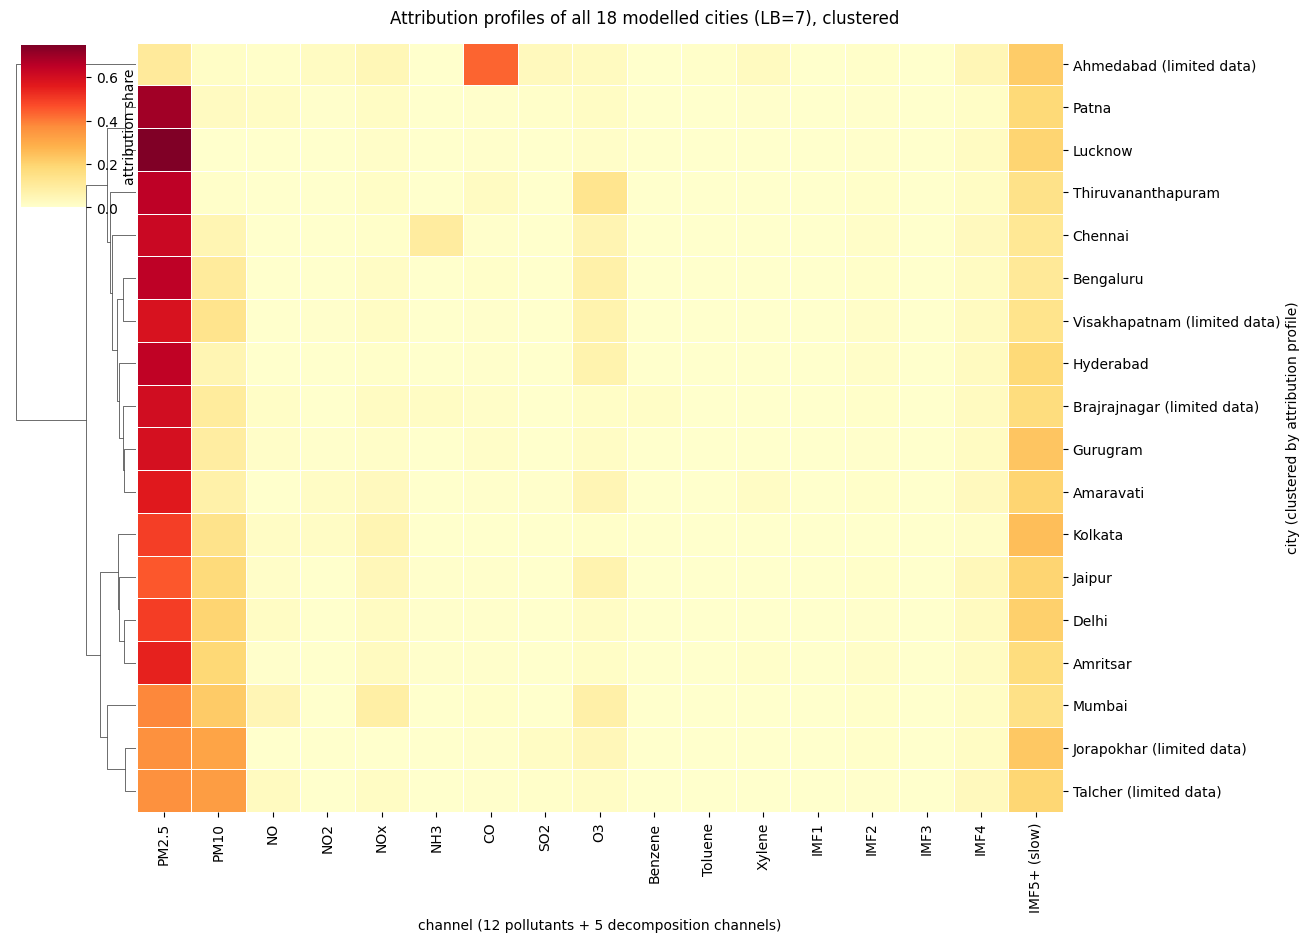

              city  d4_attribution_set  passes_completeness  test_r2  decomposition_share_pct  imf1_4_share_pct  slow_of_decomposition_pct leading_input                      top3
             Delhi                True                 True     0.92                    23.98              3.27                      86.38         PM2.5 PM2.5, IMF5+ (slow), PM10
            Mumbai                True                 True     0.87                    17.66              2.54                      85.63         PM2.5 PM2.5, PM10, IMF5+ (slow)
         Bengaluru                True                 True     0.50                    14.53              3.22                      77.85         PM2.5 PM2.5, IMF5+ (slow), PM10
             Patna                True                 True     0.91                    20.04              1.75                      91.28         PM2.5 PM2.5, IMF5+ (slow), PM10
          Gurugram                True                 True     0.85                    26.16            

In [37]:
# ── G1 (R1.15, plan section 3): attribution for all 18 modelled cities ──
# Section 14 of notebook 02 _r1_ext explained the 8 cities of rule D4. This explains the other 10 modelled cities with
# the same model, method and samples: run_shap_for_city, one value per channel, 100 test windows in the period
# proportions, 50 training windows as background, the city's own seed. The 8 cities are read from the checked cache,
# so their numbers do not change (compared below with the I-15 run's matrix). Coimbatore and Guwahati have no
# training window under the common-date split and are not modelled (R1.9/R1.10).
# Reporting (decision G1-r (i), as R3.3 D4): the main text describes the 13 cities passing the completeness rule, the
# SI lists all 18 with the 5 limited-data cities flagged. The statements that now say "in every city" are checked
# again over all 18 and over the 13, with any exception named.
G1_CITIES = list(D4_SHAP8_CITIES) + sorted(c for c in C5_DECOMP if c not in D4_SHAP8_CITIES)
G1_MATRIX_CSV = SHAP_REPORTS_DIR / f'g1_shap18_matrix_lb{MAIN_LOOKBACK}.csv'
G1_SUMMARY_CSV = SHAP_REPORTS_DIR / f'g1_shap18_summary_lb{MAIN_LOOKBACK}.csv'
G1_PERIODS_CSV = SHAP_REPORTS_DIR / f'g1_shap18_periods_lb{MAIN_LOOKBACK}.csv'
G1_STATEMENTS_JSON = SHAP_REPORTS_DIR / f'g1_statements_lb{MAIN_LOOKBACK}.json'
if sorted(G1_CITIES) != sorted(C5_DECOMP) or len(G1_CITIES) != 18:
    raise ValueError(f'G1: expected the 18 modelled cities, got {G1_CITIES}')

g1_vals = {}
for city in G1_CITIES:
    g_shap_cache_readable(shap_cache_path('v2', city, MAIN_LOOKBACK, SHAP_MAX_TEST, SHAP_N_BACKGROUND))
    cached = shap_cache_path('v2', city, MAIN_LOOKBACK, SHAP_MAX_TEST, SHAP_N_BACKGROUND).exists()
    print(f"{city}: {'from the cache' if cached else 'computing (about 14 min)'}", flush=True)
    mean_abs = g_quiet(run_shap_for_city, city, MAIN_LOOKBACK, G_MAIN, G_MAIN_CITY_TO_IDX,
                       n_background=SHAP_N_BACKGROUND, max_test_samples=SHAP_MAX_TEST)
    if mean_abs is None:
        raise ValueError(f'G1: {city} is not in the main model')
    rows = SHAP_PERIOD_ROWS[('v2', MAIN_LOOKBACK, city)]
    if any(r['missing_test_dates'] or r['missing_background_dates'] for r in rows):
        raise ValueError(f'G1: {city}: sampled dates without a window in the main model')
    g1_vals[city] = np.asarray(mean_abs, dtype=np.float64)

df_g1_matrix = pd.DataFrame(g1_vals, index=FEATURE_NAMES_V2).T.loc[G1_CITIES]
df_g1_matrix.to_csv(G1_MATRIX_CSV)
g1_i15 = pd.read_csv(G_INPUTS_DIR / 'shap' / f'shap8_attribution_matrix_lb{MAIN_LOOKBACK}.csv', index_col=0,
                     float_precision='round_trip')
if sorted(g1_i15.index) != sorted(D4_SHAP8_CITIES) or not np.allclose(
        df_g1_matrix.loc[g1_i15.index, list(g1_i15.columns)].to_numpy(), g1_i15.to_numpy(), rtol=1e-12, atol=0):
    raise ValueError('G1: the 8 cities of Section 14 differ from the I-15 run')

g1_city_test = {r['city']: r for r in r116_city_rows(G_MAIN, G_DATA[C5_SEED_BASE], MAIN_CONDITIONING) if r['part'] == 'test'}
g1_d4 = df_d4.set_index('city')
g1_rows = []
for city in G1_CITIES:
    g1_rows.append({'city': city, 'd4_attribution_set': city in D4_SHAP8_CITIES,
                    'passes_completeness': bool(g1_d4.loc[city, 'passes']), 'kept_pct': float(g1_d4.loc[city, 'kept_pct']),
                    'mean_aqi': float(g1_d4.loc[city, 'mean_aqi']), 'test_n': int(g1_city_test[city]['n']),
                    'test_r2': float(g1_city_test[city]['r2']), 'test_mae': float(g1_city_test[city]['mae']),
                    'n_windows_explained': int(SHAP_PERIOD_ROWS[('v2', MAIN_LOOKBACK, city)][0]['n_windows']),
                    **g_shares(g1_vals[city], FEATURE_NAMES_V2, len(FEATURE_COLUMNS))})
df_g1 = pd.DataFrame(g1_rows)
df_g1.to_csv(G1_SUMMARY_CSV, index=False)
pd.DataFrame([r for c in G1_CITIES for r in SHAP_PERIOD_ROWS[('v2', MAIN_LOOKBACK, c)]]).to_csv(G1_PERIODS_CSV, index=False)


def g1_statements(t):
    '''The "in every city" statements of the 8-city text, over the cities of t.'''
    return {'n_cities': int(len(t)),
            'pm25_leads_in': int((t['leading_input'] == 'PM2.5').sum()),
            'cities_where_pm25_does_not_lead': t.loc[t['leading_input'] != 'PM2.5', 'city'].tolist(),
            'decomposition_share_pct_range': [float(t['decomposition_share_pct'].min()), float(t['decomposition_share_pct'].max())],
            'imf1_4_share_pct_range': [float(t['imf1_4_share_pct'].min()), float(t['imf1_4_share_pct'].max())],
            'slow_of_decomposition_pct_range': [float(t['slow_of_decomposition_pct'].min()),
                                                float(t['slow_of_decomposition_pct'].max())],
            'cities_where_slow_channel_is_not_most_of_decomposition': t.loc[t['slow_of_decomposition_pct'] <= 50, 'city'].tolist()}


g1_statements_all = {'all 18 modelled cities': g1_statements(df_g1),
                     '13 cities passing completeness': g1_statements(df_g1[df_g1['passes_completeness']]),
                     '5 limited-data cities': g1_statements(df_g1[~df_g1['passes_completeness']]),
                     'the 8 cities of D4 (as reported)': g1_statements(df_g1[df_g1['d4_attribution_set']])}
G1_STATEMENTS_JSON.write_text(json.dumps(g1_statements_all, indent=1))

if len(df_g1_matrix) >= 3:
    import seaborn as sns
    g1_share = df_g1_matrix.div(df_g1_matrix.sum(axis=1), axis=0)
    g1_share.index = [c + ('' if df_g1.set_index('city').loc[c, 'passes_completeness'] else ' (limited data)')
                      for c in g1_share.index]
    g = sns.clustermap(g1_share, cmap='YlOrRd', figsize=(13, 9), row_cluster=True, col_cluster=False, linewidths=0.4,
                       cbar_kws={'label': 'attribution share'}, dendrogram_ratio=(0.12, 0.0))
    g.ax_heatmap.set_xlabel(f'channel ({len(FEATURE_COLUMNS)} pollutants + {len(IMF_LABELS)} decomposition channels)')
    g.ax_heatmap.set_ylabel('city (clustered by attribution profile)')
    g.fig.suptitle(f'Attribution profiles of all {len(df_g1_matrix)} modelled cities (LB={MAIN_LOOKBACK}), clustered', y=1.02)
    g.savefig(SHAP_PLOTS_DIR / f'g1_shap18_clustered_lb{MAIN_LOOKBACK}.png', dpi=200, bbox_inches='tight')
    plt.show()

print(df_g1[['city', 'd4_attribution_set', 'passes_completeness', 'test_r2', 'decomposition_share_pct', 'imf1_4_share_pct',
             'slow_of_decomposition_pct', 'leading_input', 'top3']].round(2).to_string(index=False))
for k, st in g1_statements_all.items():
    print(f"{k}: PM2.5 leads in {st['pm25_leads_in']} of {st['n_cities']}"
          + (f" (not in {st['cities_where_pm25_does_not_lead']})" if st['cities_where_pm25_does_not_lead'] else '')
          + f"; decomposition share {st['decomposition_share_pct_range'][0]:.1f}-{st['decomposition_share_pct_range'][1]:.1f}%"
          f"; IMF1-IMF4 {st['imf1_4_share_pct_range'][0]:.2f}-{st['imf1_4_share_pct_range'][1]:.2f}%; slow channel "
          f"{st['slow_of_decomposition_pct_range'][0]:.1f}-{st['slow_of_decomposition_pct_range'][1]:.1f}% of the "
          f"decomposition share")
print(f'\nWritten: {G1_MATRIX_CSV.name}, {G1_SUMMARY_CSV.name}, {G1_PERIODS_CSV.name}, {G1_STATEMENTS_JSON.name}')


## G2 (R1.1, R1.3): 4 decompositions × 5 model seeds

In [38]:
# ── G2 (R1.1, R1.3, plan section 4): the two new decompositions, seed bases 2024 and 7 ──
# The same causal C5 settings, AR boundary extension, calendar and days as the main decomposition (Section 4 of
# notebook 02 _r1_ext) and Section 17's second one. Only the city seeds differ: the seed base + the city's index in
# C5_ALL_CITIES. Saved per city in its own folder; a city interrupted by a disconnect is computed again, finished
# cities are reloaded and spot-checked (g_decompose_all, P2a tolerance). Cost: about 18 CPU-hours each, 2.5 to 3 h on
# 8 cores.
for b in G2_DSEEDS:
    if b not in G2_DECOMP:
        g_saved = [p for p in G2_CACHE_DIRS[b].glob('c5_*.npz') if '.partial' not in p.name]
        print(f'decomposition with seed base {b}: {len(g_saved)} of 18 cities saved', flush=True)
        G2_DECOMP[b] = g_decompose_all(b)
    if list(G2_DECOMP[b]) != list(C5_DECOMP) or any(not np.array_equal(G2_DECOMP[b][c]['days'], C5_DECOMP[c]['days'])
                                                    for c in C5_DECOMP):
        raise ValueError(f'G2: the decomposition with seed base {b} covers other cities or days than the main one')
    g2_short = {c: int((d['n_components'] < C5_N_CHANNELS).sum()) for c, d in G2_DECOMP[b].items()}
    print(f"seed base {b}: {len(G2_DECOMP[b])} cities; days with fewer than {C5_N_CHANNELS} components: "
          f"{ {c: n for c, n in g2_short.items() if n} or 'none'}")
(REPORTS_DIR / 'g_spot_check.json').write_text(json.dumps(G_SPOT, indent=1))


seed base 123: 18 cities; days with fewer than 5 components: none
seed base 42: 18 cities; days with fewer than 5 components: none
decomposition with seed base 2024: 18 of 18 cities saved
seed base 2024: 18 cities; days with fewer than 5 components: none
decomposition with seed base 7: 18 of 18 cities saved
seed base 7: 18 cities; days with fewer than 5 components: none


352

In [39]:
# ── G2 (plan section 4): the main design on each of the 4 decompositions, with the 5 model seeds ──
# 20 models: scalar bias, lookback 7, the settings of Section 8b (r116_fit). Reused from the I-15 run: the 5 seeds on
# the main decomposition (Sections 6 and 8b) and seed RANDOM_SEED on seed base 42 (Section 17). New: 14 trainings.
# Every dataset on another decomposition must equal the main one in everything but the 5 decomposition channels
# (g_same_windows). Each model that SHAP explains next gets its own model, scalers and dataset files (tag below).
G2_MSEEDS = list(SEEDS)
G2_MODELS_CSV = REPORTS_DIR / f'g2_models_lb{MAIN_LOOKBACK}.csv'


def g2_tag(b, s):
    '''File tag of the model on seed base b with model seed s ('' and '_dseed42' are the I-15 run's own files).'''
    if (b, s) == (C5_SEED_BASE, RANDOM_SEED):
        return ''
    if (b, s) == (42, RANDOM_SEED):
        return '_dseed42'
    return f'_g2d{b}m{s}'


for b in G2_DSEEDS:
    if b not in G_DATA:
        set_all_seeds(RANDOM_SEED)
        G_DATA[b] = build_augmented_dataset(df, FEATURE_COLUMNS, TARGET_COLUMN, seq_len=MAIN_LOOKBACK,
                                            decompositions=G2_DECOMP[b])
    if b != C5_SEED_BASE:
        g_same_windows(G_DATA[b], G_DATA[C5_SEED_BASE])

G2_TRAINERS, g2_rows = {}, []
for s in G2_MSEEDS:
    for b in G2_DSEEDS:
        t0 = time.time()
        if b == C5_SEED_BASE:
            trainer, source = G_REUSED[('cond', MAIN_CONDITIONING, s)], 'I-15 run (Section 6 or 8b)'
        elif (b, s) == (42, RANDOM_SEED):
            trainer, source = G_DSEED42, 'I-15 run (Section 17)'
        else:
            trainer = r116_fit(G_DATA[b], MAIN_CONDITIONING, s, MAIN_LOOKBACK, run=f'g2_dseed{b}')
            source = 'G2 (new)'
        train_time = time.time() - t0 + getattr(trainer, 'resume_shift', 0.0) if source == 'G2 (new)' else np.nan
        if g2_tag(b, s) not in ('', '_dseed42'):
            g_save_for_shap(trainer, G_DATA[b], g2_tag(b, s))
        G2_TRAINERS[(b, s)] = trainer
        g2_rows.append({'decomposition_seed_base': b, 'model_seed': s, 'tag': g2_tag(b, s), 'source': source,
                        'train_time_s': train_time, **r116_pooled(trainer, G_DATA[b])})
df_g2_models = pd.DataFrame(g2_rows)
df_g2_models.to_csv(G2_MODELS_CSV, index=False)

# Coherence with the I-15 records: the main decomposition's rows are Section 8b's, seed base 42 at seed RANDOM_SEED is
# Section 17's model
g2_main = df_g2_models[df_g2_models['decomposition_seed_base'] == C5_SEED_BASE].set_index('model_seed')
g2_r116 = G_R116_RUNS[G_R116_RUNS['conditioning'] == MAIN_CONDITIONING].set_index('seed')
if not np.allclose(g2_main.loc[G2_MSEEDS, 'test_r2'], g2_r116.loc[G2_MSEEDS, 'test_r2'], rtol=1e-5, atol=1e-6):
    raise ValueError("G2: the main decomposition's models do not reproduce Section 8b")
g2_r117 = pd.read_csv(G_INPUTS_DIR / f'r117_decomp_seed_accuracy_lb{MAIN_LOOKBACK}.csv', float_precision='round_trip')
g2_r117 = g2_r117.set_index('metric')['dseed42']
g2_42 = df_g2_models[(df_g2_models['decomposition_seed_base'] == 42) & (df_g2_models['model_seed'] == RANDOM_SEED)].iloc[0]
if not all(np.isclose(g2_42[f'test_{m}'], g2_r117[m], rtol=1e-5, atol=1e-6) for m in ('r2', 'rmse', 'mae')):
    raise ValueError("G2: the seed-base-42 model does not reproduce Section 17's accuracy")

print(f'G2 models at LB={MAIN_LOOKBACK} ({MAIN_CONDITIONING}): test R2 by decomposition seed base (rows) and model seed')
print(df_g2_models.pivot(index='decomposition_seed_base', columns='model_seed', values='test_r2').round(4).to_string())
print(f'\nWritten: {G2_MODELS_CSV.name}')


G2 models at LB=7 (bias): test R2 by decomposition seed base (rows) and model seed
model_seed                 7       42      123     2024    2025
decomposition_seed_base                                        
7                        0.8229  0.8304  0.8279  0.8103  0.8282
42                       0.8319  0.8227  0.8451  0.8088  0.7703
123                      0.8072  0.8390  0.8326  0.8116  0.8148
2024                     0.8218  0.8108  0.8335  0.8270  0.8236

Written: g2_models_lb7.csv


In [40]:
# ── G2 (plan section 4): KernelSHAP of the 20 models for Delhi, Mumbai and Bengaluru ──
# run_shap_for_city as in Section 9: the same sampled test and background dates (drawn from the main model's
# windows), the same method and city seeds. Each model explains its own windows forecasting those dates, which are
# the same windows in every model (g_same_windows), so only the model differs. Reused: the main model (run 'v2') and
# Section 17's model (run 'v2_dseed42'). New: 54 city runs of about 14 min each, cached per city and model, so a
# disconnect loses at most one city run. Model seeds run in the outer loop, so a partial result covers whole seeds.
G2_SHAP_CITIES = list(SHAP_CITIES)
g2_main_cache = {}
for city in G2_SHAP_CITIES:
    with np.load(shap_cache_path('v2', city, MAIN_LOOKBACK, SHAP_MAX_TEST, SHAP_N_BACKGROUND), allow_pickle=False) as z:
        g2_main_cache[city] = (z['test_dates'], z['background_dates'])
g2_done, g2_new = 0, 0
for s in G2_MSEEDS:
    for b in G2_DSEEDS:
        tag = g2_tag(b, s)
        for city in G2_SHAP_CITIES:
            path = shap_cache_path(f'v2{tag}', city, MAIN_LOOKBACK, SHAP_MAX_TEST, SHAP_N_BACKGROUND)
            g_shap_cache_readable(path)
            g2_new += not path.exists()
            print(f"seed base {b}, model seed {s}, {city}: {'from the cache' if path.exists() else 'computing'}", flush=True)
            if g_quiet(run_shap_for_city, city, MAIN_LOOKBACK, G2_TRAINERS[(b, s)], G_DATA[b]['city_to_idx'],
                       n_background=SHAP_N_BACKGROUND, max_test_samples=SHAP_MAX_TEST, tag=tag) is None:
                raise ValueError(f'G2: {city} is not in the model {tag}')
            with np.load(path, allow_pickle=False) as z:
                same = all(np.array_equal(x, y) for x, y in zip((z['test_dates'], z['background_dates']), g2_main_cache[city]))
                missing = int(z['missing_test']) + int(z['missing_background'])
            if not same or missing:
                raise ValueError(f'G2: {city}, model {tag}: other explained dates than the main model, or {missing} missing')
            g2_done += 1
print(f'G2 SHAP: {g2_done} city runs ({g2_new} computed in this session)')


seed base 123, model seed 42, Delhi: from the cache
  Delhi top drivers: PM2.5(0.0272), IMF5+ (slow)(0.0118), PM10(0.0104)
seed base 123, model seed 42, Mumbai: from the cache
  Mumbai top drivers: PM2.5(0.0147), IMF5+ (slow)(0.0106), PM10(0.0057)
seed base 123, model seed 42, Bengaluru: from the cache
  Bengaluru top drivers: PM2.5(0.0074), IMF5+ (slow)(0.0037), PM10(0.0013)
seed base 42, model seed 42, Delhi: from the cache
  Delhi top drivers: PM2.5(0.0308), IMF5+ (slow)(0.0136), PM10(0.0036)
seed base 42, model seed 42, Mumbai: from the cache
  Mumbai top drivers: PM2.5(0.0139), IMF5+ (slow)(0.0055), PM10(0.0011)
seed base 42, model seed 42, Bengaluru: from the cache
  Bengaluru top drivers: PM2.5(0.0062), IMF5+ (slow)(0.0012), PM10(0.0002)
seed base 2024, model seed 42, Delhi: from the cache
  Delhi top drivers: PM2.5(0.0333), IMF5+ (slow)(0.0119), PM10(0.0023)
seed base 2024, model seed 42, Mumbai: from the cache
  Mumbai top drivers: PM2.5(0.0148), IMF5+ (slow)(0.0049), NOx(0.00

In [41]:
# ── G2 (plan section 4): how much do attribution and accuracy depend on the decomposition, beyond training? ──
# Analysis fixed in advance (plan section 4). Per city (period 'all'; the periods are listed too) and per model: the
# decomposition share, the IMF1-IMF4 share, the slow channel's share of the decomposition share, the leading input,
# the rank of PM2.5, and the Spearman rho of the 12 pollutants against the main model. For the three shares and for
# accuracy (validation R2, test R2, MAE and RMSE, pooled and per period): one-way random effects over the 4
# decompositions with 5 model seeds each (g_oneway). Wording fixed in advance for each city's decomposition share
# (g2_sentence, p < 0.05). Also: the single comparison of Section 17 is reproduced from these models.
G2_SHAP_CSV = SHAP_REPORTS_DIR / f'g2_shap_lb{MAIN_LOOKBACK}.csv'
G2_ANOVA_CSV = REPORTS_DIR / f'g2_anova_lb{MAIN_LOOKBACK}.csv'
G2_STATEMENTS_JSON = REPORTS_DIR / f'g2_statements_lb{MAIN_LOOKBACK}.json'
G2_SHARES = ['decomposition_share_pct', 'imf1_4_share_pct', 'slow_of_decomposition_pct']
G2_ACCURACY = ['val_r2', 'test_r2', 'test_mae', 'test_rmse', 'test_r2_pre', 'test_mae_pre', 'test_r2_lock',
               'test_mae_lock']
g2_n_pol = len(FEATURE_COLUMNS)


def g2_vector(row):
    return np.array([row[f] for f in FEATURE_NAMES_V2], dtype=np.float64)


g2_shap_rows = []
for (b, s) in G2_TRAINERS:
    for city in G2_SHAP_CITIES:
        main_all = next(r for r in SHAP_PERIOD_ROWS[('v2', MAIN_LOOKBACK, city)] if r['period'] == 'all')
        for r in SHAP_PERIOD_ROWS[(f'v2{g2_tag(b, s)}', MAIN_LOOKBACK, city)]:
            if not r['n_windows']:
                continue
            v = g2_vector(r)
            rho = scipy.stats.spearmanr(g2_vector(main_all)[:g2_n_pol], v[:g2_n_pol])[0]
            g2_shap_rows.append({'decomposition_seed_base': b, 'model_seed': s, 'city': city, 'period': r['period'],
                                 'n_windows': r['n_windows'], **g_shares(v, FEATURE_NAMES_V2, g2_n_pol),
                                 'spearman_rho_pollutants_vs_main': float(rho),
                                 **{f'mean_abs_{f}': float(x) for f, x in zip(FEATURE_NAMES_V2, v)}})
df_g2_shap = pd.DataFrame(g2_shap_rows)
df_g2_shap.to_csv(G2_SHAP_CSV, index=False)

g2_anova_rows, g2_statements = [], {'decomposition_share': {}, 'pm25_leads_in_every_model': {},
                                    'min_spearman_rho_pollutants_vs_main': {}}
g2_all = df_g2_shap[df_g2_shap['period'] == 'all']
for city in G2_SHAP_CITIES:
    t = g2_all[g2_all['city'] == city]
    for q in G2_SHARES:
        groups = [t[t['decomposition_seed_base'] == b].sort_values('model_seed')[q].to_numpy() for b in G2_DSEEDS]
        res = g_oneway(groups)
        g2_anova_rows.append({'scope': city, 'quantity': q, **{k: v for k, v in res.items() if k != 'group_means'},
                              **{f'mean_dseed{b}': m for b, m in zip(G2_DSEEDS, res['group_means'])}})
        if q == 'decomposition_share_pct':
            g2_statements['decomposition_share'][city] = g2_sentence(city, res)
    g2_statements['pm25_leads_in_every_model'][city] = bool((t['leading_input'] == 'PM2.5').all())
    g2_statements['min_spearman_rho_pollutants_vs_main'][city] = float(t['spearman_rho_pollutants_vs_main'].min())
for q in G2_ACCURACY:
    groups = [df_g2_models[df_g2_models['decomposition_seed_base'] == b].sort_values('model_seed')[q].to_numpy()
              for b in G2_DSEEDS]
    res = g_oneway(groups)
    g2_anova_rows.append({'scope': 'pooled', 'quantity': q, **{k: v for k, v in res.items() if k != 'group_means'},
                          **{f'mean_dseed{b}': m for b, m in zip(G2_DSEEDS, res['group_means'])}})
df_g2_anova = pd.DataFrame(g2_anova_rows)
df_g2_anova.to_csv(G2_ANOVA_CSV, index=False)

# Section 17's single comparison (seed base 42 against 123, model seed RANDOM_SEED), reproduced from these models
g2_r117 = pd.read_csv(G_INPUTS_DIR / 'shap' / f'r117_decomp_seed_shap_lb{MAIN_LOOKBACK}.csv', float_precision='round_trip')
for city in G2_SHAP_CITIES:
    one = g2_all[(g2_all['city'] == city) & (g2_all['model_seed'] == RANDOM_SEED)].set_index('decomposition_seed_base')
    mine = one.loc[42, 'decomposition_share_pct'] - one.loc[C5_SEED_BASE, 'decomposition_share_pct']
    theirs = float(g2_r117[(g2_r117['city'] == city) & (g2_r117['period'] == 'all')]['channel_share_difference_pp'].iloc[0])
    if not np.isclose(mine, theirs, rtol=1e-9, atol=1e-9):
        raise ValueError(f"G2: {city}: Section 17's share difference {theirs:.4f} pp is not reproduced ({mine:.4f})")
g2_statements['section17_single_comparison_reproduced'] = True
G2_STATEMENTS_JSON.write_text(json.dumps(g2_statements, indent=1))

print(f'G2: {len(G2_DSEEDS)} decompositions (seed bases {G2_DSEEDS}) x {len(G2_MSEEDS)} model seeds, LB={MAIN_LOOKBACK}')
print(df_g2_anova[['scope', 'quantity', 'mean', 'sd_within', 'sd_between', 'F', 'p_value', 'between_share_pct',
                   'min', 'max']].round(4).to_string(index=False))
for line in g2_statements['decomposition_share'].values():
    print(' ', line)
print('PM2.5 leads in every model:', g2_statements['pm25_leads_in_every_model'])
print('lowest Spearman rho of the pollutants against the main model:',
      {c: round(v, 3) for c, v in g2_statements['min_spearman_rho_pollutants_vs_main'].items()})
print(f'\nWritten: {G2_SHAP_CSV.name}, {G2_ANOVA_CSV.name}, {G2_STATEMENTS_JSON.name}')


G2: 4 decompositions (seed bases [123, 42, 2024, 7]) x 5 model seeds, LB=7
    scope                  quantity    mean  sd_within  sd_between      F  p_value  between_share_pct     min     max
    Delhi   decomposition_share_pct 22.5916     5.8572      0.0000 0.4634   0.7118             0.0000  7.4606 32.0789
    Delhi          imf1_4_share_pct  2.6385     1.3306      0.3434 1.3331   0.2986             6.2456  0.4205  5.4355
    Delhi slow_of_decomposition_pct 87.2929     9.0005      2.3933 1.3535   0.2925             6.6038 55.3148 97.4146
   Mumbai   decomposition_share_pct 21.3364     7.0435      0.0000 0.6715   0.5819             0.0000 12.3559 34.2035
   Mumbai          imf1_4_share_pct  1.6743     0.7692      0.0000 0.7203   0.5543             0.0000  0.5849  2.9542
   Mumbai slow_of_decomposition_pct 92.1061     3.1973      0.0000 0.5116   0.6800             0.0000 85.1986 96.4354
Bengaluru   decomposition_share_pct 16.1721     6.7413      0.0000 0.8172   0.5031             0.00

## Results file

In [42]:
# ── G1-G3: the results file for download ──
# reports/ and plots/ of guide_followups in one zip (the models stay on Drive). Download it and the executed notebook.
import zipfile

G_RESULTS_ZIP = RESULTS_DIR / 'guide_followups_results.zip'
g_tmp_zip = G_RESULTS_ZIP.with_name(G_RESULTS_ZIP.stem + '.partial.zip')
with zipfile.ZipFile(g_tmp_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    for folder in (REPORTS_DIR, PLOTS_DIR):
        for p in sorted(folder.rglob('*')):
            if p.is_file() and '.partial' not in p.name:
                zf.write(p, p.relative_to(RESULTS_DIR))
os.replace(g_tmp_zip, G_RESULTS_ZIP)
print(f'G1-G3 COMPLETE. Saved {G_RESULTS_ZIP}: download it and the executed notebook.')


G1-G3 COMPLETE. Saved /content/drive/MyDrive/phase4_v2_results_r1_ext/guide_followups/guide_followups_results.zip: download it and the executed notebook.
